# 09 Persist full and reduced sensitivity pipelines for interpretation
This notebook performs a separate exploratory training run: full and thresholds 0.95, 0.90, 0.80 
for logistic regression, RF, XGBoost, LightGBM and MLP. All three sensor configurations are included. 
It saves fitted pipelines, provenance and OOF rows after each fold. 
Output uses a new directory, preserving existing sensitivity results. 
This is expensive and does not resume automatically. No reduced versions of binary or composite 
experiments are invented: this run matches the three-class sensitivity design of notebook09.


## Execution and recovery
Run setup, function definitions, and the full training cell before plotting. 
Tables are checkpointed after each completed fold. The plotting cell reads saved tables 
and rejects missing tree importances instead of silently skipping them. 
Saved metrics alone cannot recover importance values when fitted models were not saved. 
The training cell starts a new run and overwrites its checkpoint files; it does not automatically resume. 
All three thresholds (0.95, 0.90, 0.80) are post-hoc sensitivity analyses.


In [1]:
from pathlib import Path
import sys, os, json, copy, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from io import BytesIO
from IPython.display import display, Image, Markdown
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import balanced_accuracy_score, f1_score
from sklearn.inspection import permutation_importance

PROJECT_ROOT = None
here=Path.cwd().resolve()
ROOT=Path(PROJECT_ROOT).resolve() if PROJECT_ROOT else next(
    (p for p in [here,*here.parents] if (p/'configs/config.yaml').is_file() and (p/'src').is_dir()),None)
if ROOT is None: raise RuntimeError('Salva il notebook in notebooks/ oppure imposta PROJECT_ROOT.')
os.chdir(ROOT)
if str(ROOT) not in sys.path: sys.path.insert(0,str(ROOT))
from src import workflow as w
from src.config import load, fingerprint
from src.models import pipeline as original_pipeline, grid, feature_columns
from src.splits import loso, inner
from src.fusion import comparison_tables

c=load()
lock=json.loads((w.root(c)/'protocol_lock.json').read_text(encoding='utf-8'))
c=copy.deepcopy(lock['config'])
if fingerprint(c)!=lock['config_sha256']: raise ValueError('Protocollo non coerente.')
OUT=w.root(c)/'exploratory/feature_redundancy_saved_models'
OUT.mkdir(parents=True,exist_ok=True)

# Soglia fissata, NON ottimizzata sul test. Cambiarla crea un'altra analisi esplorativa.
CORRELATION_THRESHOLDS=[0.95,0.90,0.80]
CORRELATION_METHOD='spearman'
SITES=['early_fusion','chest','wrist']
MODELS=['logistic_regression','random_forest','xgboost','lightgbm','mlp']
# Per includere i boosting, se installati:
# MODELS += ['xgboost','lightgbm']
N_PERMUTATION_REPEATS=10
TOP_N=20
SAVE_MODELS=True
SEED=c['splits']['seed']
tables=w.load_tables(c)
frames=comparison_tables(tables,paired_only=True)
def show(fig,name):
    fig.savefig(OUT/name,dpi=160,bbox_inches='tight')
    with BytesIO() as b:
        fig.savefig(b,format='png',dpi=125,bbox_inches='tight'); data=b.getvalue()
    plt.close(fig);display(Image(data=data))
print('Analysis output directory ready.')
print('Il notebook riaddestra modelli con tuning annidato: può richiedere tempo.')


Analysis output directory ready.
Il notebook riaddestra modelli con tuning annidato: può richiedere tempo.


## Redundancy selector

Absolute Spearman correlation between features in the training set only. Deterministic alphabetical order, independent of labels: the first available feature is kept, and those excessively correlated with an already retained feature are discarded. This does not guarantee finding the optimal subset. All exclusions are logged. Constant or entirely missing features are removed in the reduced variant.

Pooled correlation may reflect differences between subjects or conditions: it is not a within-person physiological association test. The threshold is an engineering rule of thumb and does not resolve all forms of multicollinearity.

In [2]:
class CorrelationSelector(TransformerMixin, BaseEstimator):
    def __init__(self, threshold=0.90, method='spearman'):
        self.threshold=threshold; self.method=method
    def fit(self,X,y=None):
        if not isinstance(X,pd.DataFrame): raise TypeError('Servono DataFrame con nomi.')
        if not 0 < self.threshold <= 1: raise ValueError('Soglia non valida.')
        X=X.replace([np.inf,-np.inf],np.nan)
        self.feature_names_in_=np.asarray(X.columns,dtype=object)
        self.n_features_in_=len(X.columns)
        columns=sorted(X.columns)
        usable=[col for col in columns if X[col].nunique(dropna=True)>1]
        self.correlation_=X[usable].corr(method=self.method,min_periods=3).abs()
        self.kept_=[];self.removed_=[]
        for col in columns:
            if col not in usable:
                self.removed_.append(dict(feature=col,reason='constant_or_all_missing',representative=None,abs_r=np.nan))
                continue
            matches=[other for other in self.kept_ if self.correlation_.loc[col,other]>=self.threshold]
            if matches:
                other=matches[0]
                self.removed_.append(dict(feature=col,reason='correlated',representative=other,
                                          abs_r=float(self.correlation_.loc[col,other])))
            else:self.kept_.append(col)
        if not self.kept_:raise ValueError('Nessuna feature rimasta.')
        return self
    def transform(self,X):return X.loc[:,self.kept_].copy()
    def get_feature_names_out(self,input_features=None):return np.asarray(self.kept_,dtype=object)

def make_pipeline(model_name,reduced):
    base=original_pipeline(model_name,c)
    steps=list(base.steps)
    if reduced is not None:steps=[('correlation',CorrelationSelector(reduced,CORRELATION_METHOD))]+steps
    return Pipeline(steps)

def tune_training(train,cols,model_name,reduced):
    base=make_pipeline(model_name,reduced)
    best_params=None;best_score=-np.inf;trace=[]
    for params in ParameterGrid(grid(model_name,c)):
        scores=[]
        for tr,va in inner(train,c['splits']['inner_folds']):
            fit=clone(base).set_params(**params)
            fit.fit(train.iloc[tr][cols],train.iloc[tr]['label'])
            valid=train.iloc[va]
            guessed=fit.predict(valid[cols])
            for sid in valid.subject_id.unique():
                mask=valid.subject_id.to_numpy()==sid
                if set(valid.loc[mask,'label'])!={1,2,3}:raise ValueError('Classe assente in validazione.')
                scores.append(balanced_accuracy_score(valid.loc[mask,'label'],guessed[mask]))
        score=float(np.mean(scores));trace.append({'params':params,'score':score})
        if score>best_score:best_score=score;best_params=params
    fitted=clone(base).set_params(**best_params).fit(train[cols],train['label'])
    return fitted,{'best_params':best_params,'inner_score':best_score,'trace':trace}


## Training and importances

The comparison uses the same subjects and windows across both variants. RF internal importances are impurity-based; for LightGBM and XGBoost, the native model-declared type is retained. They are normalized per fold and are not directly comparable as absolute units across algorithms.

Permutation importance measures the drop in balanced accuracy on the test subject when a feature is permuted. Correlation can mask individual feature importance. Window permutations disrupt temporal structure: this is a diagnostic perturbation, not a temporal significance test. The deviation across repetitions is not a confidence interval across individuals.

In [3]:
fold_rows=[];prediction_rows=[];selection_rows=[];importance_rows=[];warning_rows=[];traces=[]
for site in SITES:
    frame=frames[site].reset_index(drop=True)
    cols=feature_columns(frame)
    if np.isinf(frame[cols].to_numpy(float)).any():raise ValueError('Feature infinite: controllare estrazione.')
    for model_name in MODELS:
        for variant in ['full','reduced_0.95','reduced_0.90','reduced_0.80']:
            for tr,te in loso(frame,(1,2,3)):
                train,test=frame.iloc[tr],frame.iloc[te]
                sid=int(test.subject_id.iloc[0])
                print(f'{site} | {model_name} | {variant} | S{sid}',flush=True)
                with warnings.catch_warnings(record=True) as observed:
                    warnings.simplefilter('always')
                    fitted,trace=tune_training(train,cols,model_name,float(variant.split('_')[1]) if variant.startswith('reduced_') else None)
                    predicted=fitted.predict(test[cols])
                    probabilities=fitted.predict_proba(test[cols])
                    kept=(fitted.named_steps['correlation'].kept_ if variant.startswith('reduced_') else cols)
                    common=dict(site=site,model=model_name,variant=variant,subject_id=sid)
                    fold_rows.append({**common,'n_windows':len(test),'n_features':len(kept),
                        'balanced_accuracy':balanced_accuracy_score(test.label,predicted),
                        'f1_macro':f1_score(test.label,predicted,labels=[1,2,3],average='macro',zero_division=0),
                        **{f'recall_{k}':float(np.mean(predicted[test.label.to_numpy()==k]==k)) for k in [1,2,3]}})
                    traces.append({**common,**trace})
                    for col in cols:selection_rows.append({**common,'feature':col,'selected':col in kept})
                    if variant.startswith('reduced_'):
                        pd.DataFrame(fitted.named_steps['correlation'].removed_).to_csv(
                            OUT/f'removed_{site}_{model_name}_{variant}_S{sid}.csv',index=False)
                    for j,row in enumerate(test.itertuples()):
                        prediction_rows.append({**common,'window_id':row.window_id,'label':int(row.label),
                            'prediction':int(predicted[j]),**{f'p_{int(k)}':float(probabilities[j,i]) for i,k in enumerate(fitted.classes_)}})
                    estimator=fitted.named_steps['model']
                    # Only the project's label-encoding wrapper should be unwrapped.
                    # RF.estimator_ is an unfitted base-tree template, not the forest.
                    tree=(estimator.estimator_ if hasattr(estimator,'encoder_')
                          and hasattr(estimator,'estimator_') else estimator)
                    if model_name in ['random_forest','xgboost','lightgbm'] and not hasattr(tree,'feature_importances_'):
                        raise RuntimeError(f'Expected tree feature importances missing: {model_name}, {type(tree).__name__}')
                    if hasattr(tree,'feature_importances_'):
                        # Recover names after preprocessing, not merely before imputation.
                        feature_names=fitted[:-1].get_feature_names_out()
                        values=np.asarray(tree.feature_importances_,float)
                        if len(values)!=len(feature_names):raise ValueError('Nomi e importanze non allineati.')
                        total=values.sum()
                        importance_type=('impurity' if model_name=='random_forest' else str(getattr(tree,'importance_type','library_default')))
                        for feature,value in zip(feature_names,values):
                            importance_rows.append({**common,'kind':'internal_normalized','importance_type':importance_type,
                                'feature':feature,'importance':float(value/total) if total else 0.,'repeat_std':np.nan})
                        pi=permutation_importance(fitted,test[cols],test.label,
                            scoring='balanced_accuracy',n_repeats=N_PERMUTATION_REPEATS,
                            random_state=SEED+sid,n_jobs=1)
                        for feature,value,std in zip(cols,pi.importances_mean,pi.importances_std):
                            importance_rows.append({**common,'kind':'permutation_test','importance_type':'BA_drop',
                                'feature':feature,'importance':float(value),'repeat_std':float(std)})
                    for warning in observed:
                        warning_rows.append({**common,'category':warning.category.__name__,'message':str(warning.message)})
                if SAVE_MODELS:
                    import joblib
                    stem=f'{site}_{model_name}_{variant}_S{sid}'
                    joblib.dump(fitted,OUT/f'{stem}.joblib')
                    metadata=dict(features=cols,fit_subjects=sorted(map(int,train.subject_id.unique())),
                        test_subject=sid,classes=list(map(int,fitted.classes_)),variant=variant,
                        task='three_class',site=site,model=model_name,config_sha256=fingerprint(c))
                    (OUT/f'{stem}_metadata.json').write_text(json.dumps(metadata,indent=2),encoding='utf-8')
                # Incremental outputs preserve completed folds if execution is interrupted.
                fold_metrics=pd.DataFrame(fold_rows)
                selection=pd.DataFrame(selection_rows)
                importances=pd.DataFrame(importance_rows,columns=[
                    'site','model','variant','subject_id','kind','importance_type',
                    'feature','importance','repeat_std'])
                fold_metrics.to_csv(OUT/'fold_metrics.csv',index=False)
                selection.to_csv(OUT/'feature_selection.csv',index=False)
                importances.to_csv(OUT/'feature_importances.csv',index=False)
                pd.DataFrame(prediction_rows).to_csv(OUT/'predictions.csv',index=False)
                pd.DataFrame(warning_rows).to_csv(OUT/'fit_warnings.csv',index=False)
                print(f'Completed fold; collected importance rows: {len(importances)}',flush=True)
fold_metrics=pd.DataFrame(fold_rows)
selection=pd.DataFrame(selection_rows)
importances=pd.DataFrame(importance_rows)
pd.DataFrame(prediction_rows).to_csv(OUT/'predictions.csv',index=False)
selection.to_csv(OUT/'feature_selection.csv',index=False)
pd.DataFrame(warning_rows).to_csv(OUT/'fit_warnings.csv',index=False)
(OUT/'tuning_trace.json').write_text(json.dumps(traces,indent=2),encoding='utf-8')
print('Esecuzione completata. Warning registrati:',len(warning_rows))
estimator = fitted.named_steps['model']
tree = estimator
if model_name in ['random_forest', 'xgboost', 'lightgbm'] and not hasattr(tree, 'feature_importances_'):
    raise RuntimeError(
        f'Expected tree feature importances missing: {model_name}, {type(tree).__name__}'
    )

early_fusion | logistic_regression | full | S2
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S3
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S4
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S5
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S6
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S7
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S8
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S9
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S10
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S11
Completed fold; collected importance rows: 0
early_fusion | logistic_regression | full | S13
Completed fold; collected impo

## Training and importances

The comparison uses the same subjects and windows across both variants. RF internal importances are impurity-based; for LightGBM and XGBoost, the native model-declared type is retained. They are normalized per fold and are not directly comparable as absolute units across algorithms.

Permutation importance measures the drop in balanced accuracy on the test subject when a feature is permuted. Correlation can mask individual feature importance. Window permutations disrupt temporal structure: this is a diagnostic perturbation, not a temporal significance test. The deviation across repetitions is not a confidence interval across individuals.

In [4]:
display(fold_metrics.groupby(['site','model','variant'])[['balanced_accuracy','f1_macro','recall_1','recall_2','recall_3','n_features']].agg(['mean','std']))
rng=np.random.default_rng(SEED);rows=[]
for (site,model),g in fold_metrics.groupby(['site','model']):
    pivot=g.pivot(index='subject_id',columns='variant',values='balanced_accuracy')
    for variant in ['reduced_0.95','reduced_0.90','reduced_0.80']:
        if pivot[['full',variant]].isna().any().any():raise ValueError('Fold non appaiati')
        d=(pivot[variant]-pivot['full']).to_numpy()
        boot=d[rng.integers(0,len(d),size=(10000,len(d)))].mean(1)
        low,high=np.quantile(boot,[.025,.975])
        rows.append(dict(site=site,model=model,variant=variant,delta_BA_pp=100*d.mean(),ci_low_pp=100*low,ci_high_pp=100*high))
comparison=pd.DataFrame(rows);display(comparison)
comparison.to_csv(OUT/'paired_reduced_minus_full.csv',index=False)
frequency=selection.groupby(['site','model','variant','feature']).selected.mean().rename('selection_frequency').reset_index()
frequency.to_csv(OUT/'selection_frequency.csv',index=False)
display(frequency)


balanced_accuracy            \
                                                           mean       std   
site         model               variant                                    
chest        lightgbm            full                  0.697021  0.169337   
                                 reduced_0.80          0.680173  0.143812   
                                 reduced_0.90          0.668289  0.170374   
                                 reduced_0.95          0.649213  0.168720   
             logistic_regression full                  0.656612  0.155552   
                                 reduced_0.80          0.661878  0.177229   
                                 reduced_0.90          0.661061  0.150429   
                                 reduced_0.95          0.666880  0.159569   
             mlp                 full                  0.590894  0.120161   
                                 reduced_0.80          0.603922  0.102300   
                                 reduced_0.90          0.572121  0.124706   
                                 reduced_0.95          0.539466  0.138691   
             random_forest       full                  0.630460  0.158727   
                                 reduced_0.80          0.657480  0.144832   
                                 reduced_0.90          0.639795  0.129749   
                                 reduced_0.95          0.643178  0.126783   
             xgboost             full                  0.677808  0.168064   
                                 reduced_0.80          0.674676  0.132705   
                                 reduced_0.90          0.663834  0.160412   
                                 reduced_0.95          0.679908  0.132782   
early_fusion lightgbm            full                  0.679387  0.160949   
                                 reduced_0.80          0.688154  0.162925   
                                 reduced_0.90          0.684357  0.162842   
                                 reduced_0.95          0.664449  0.151654   
             logistic_regression full                  0.682071  0.179244   
                                 reduced_0.80          0.661734  0.170111   
                                 reduced_0.90          0.662790  0.179288   
                                 reduced_0.95          0.690448  0.180197   
             mlp                 full                  0.600501  0.167053   
                                 reduced_0.80          0.656924  0.151266   
                                 reduced_0.90          0.626390  0.187644   
                                 reduced_0.95          0.629773  0.149283   
             random_forest       full                  0.674375  0.147567   
                                 reduced_0.80          0.699482  0.119024   
                                 reduced_0.90          0.723559  0.127080   
                                 reduced_0.95          0.702592  0.112288   
             xgboost             full                  0.684601  0.141796   
                                 reduced_0.80          0.653720  0.164883   
                                 reduced_0.90          0.672936  0.159420   
                                 reduced_0.95          0.676174  0.170457   
wrist        lightgbm            full                  0.660591  0.147446   
                                 reduced_0.80          0.621971  0.124053   
                                 reduced_0.90          0.656390  0.155304   
                                 reduced_0.95          0.662988  0.146833   
             logistic_regression full                  0.661080  0.170277   
                                 reduced_0.80          0.648945  0.158398   
                                 reduced_0.90          0.665611  0.166426   
                                 reduced_0.95          0.658930  0.169956   
             mlp                 full                  0.667457  0.133108   
                                 reduced_0

,site,model,variant,delta_BA_pp,ci_low_pp,ci_high_pp
0,chest,lightgbm,reduced_0.95,-4.780797,-8.617506,-1.527227
1,chest,lightgbm,reduced_0.90,-2.873130,-7.679797,1.826135
2,chest,lightgbm,reduced_0.80,-1.684725,-5.187744,1.846962
3,chest,logistic_regression,reduced_0.95,1.026739,-0.193162,2.540730
4,chest,logistic_regression,reduced_0.90,0.444907,-1.839566,2.767428
5,chest,logistic_regression,reduced_0.80,0.526587,-2.947074,5.677011
6,chest,mlp,reduced_0.95,-5.142849,-9.659394,-0.447668
7,chest,mlp,reduced_0.90,-1.877369,-7.623416,4.285876
8,chest,mlp,reduced_0.80,1.302734,-6.003425,9.043538
9,chest,random_forest,reduced_0.95,1.271758,-2.163906,4.759597


,site,model,variant,feature,selection_frequency
0,chest,lightgbm,full,chest__ACC__activity_level,1.0
1,chest,lightgbm,full,chest__ACC__movement_variance,1.0
2,chest,lightgbm,full,chest__ACC__posture_axis_0,1.0
3,chest,lightgbm,full,chest__ACC__posture_axis_1,1.0
4,chest,lightgbm,full,chest__ACC__posture_axis_2,1.0
...,...,...,...,...,...
1795,wrist,xgboost,reduced_0.95,wrist__EDA__std,1.0
1796,wrist,xgboost,reduced_0.95,wrist__EDA__tonic_proxy,0.0
1797,wrist,xgboost,reduced_0.95,wrist__TEMP__mean,1.0
1798,wrist,xgboost,reduced_0.95,wrist__TEMP__slope_per_second,1.0


## Importanze: media tra soggetti e stabilità

Si visualizzano RF e gli eventuali boosting inclusi in MODELS. Nella variante ridotta, le feature escluse da un fold ricevono importanza interna zero ai soli fini della media complessiva: riportare anche la frequenza di selezione. Permutation importance negativa significa che la perturbazione ha migliorato lo score del test, non un effetto fisiologico protettivo.

site          model                variant     
chest         lightgbm             full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              logistic_regression  full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              mlp                  full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              random_forest        full            15
                                   reduced_0.80    15
                                   reduced_0.90    15
                                   reduced_0.95    15
              xgboost              full            15
                                  

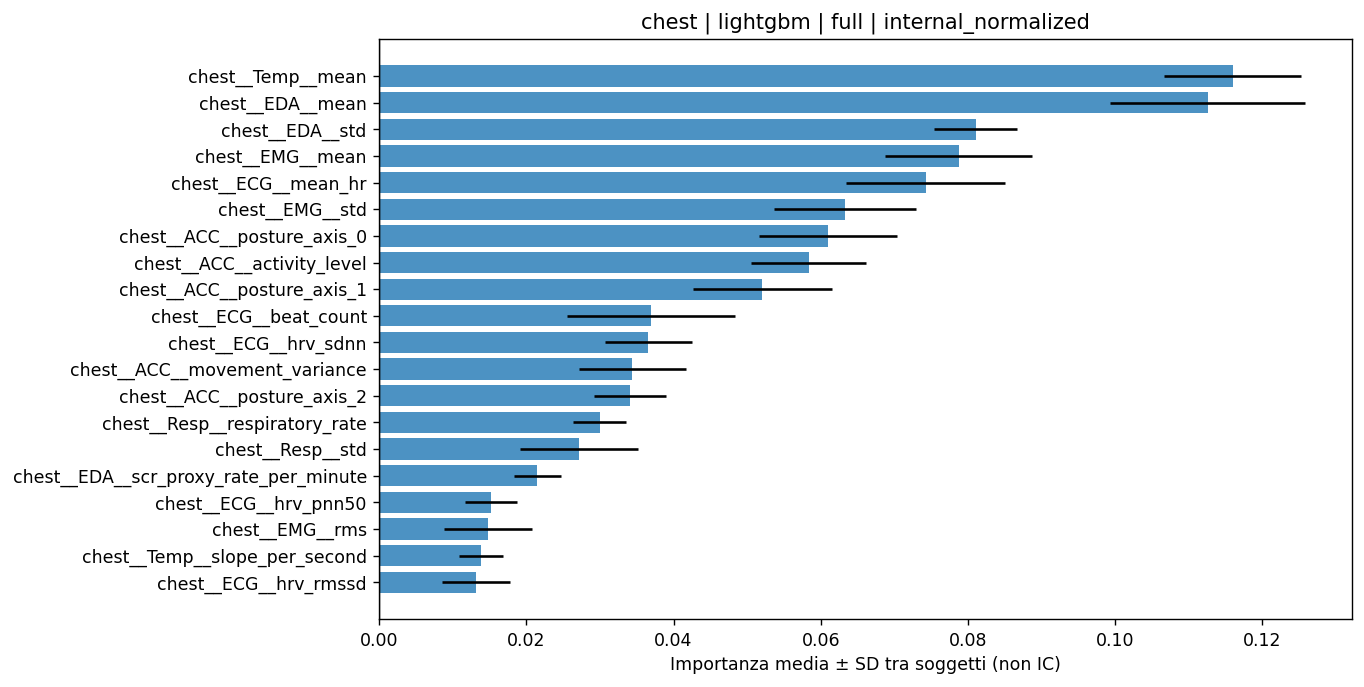

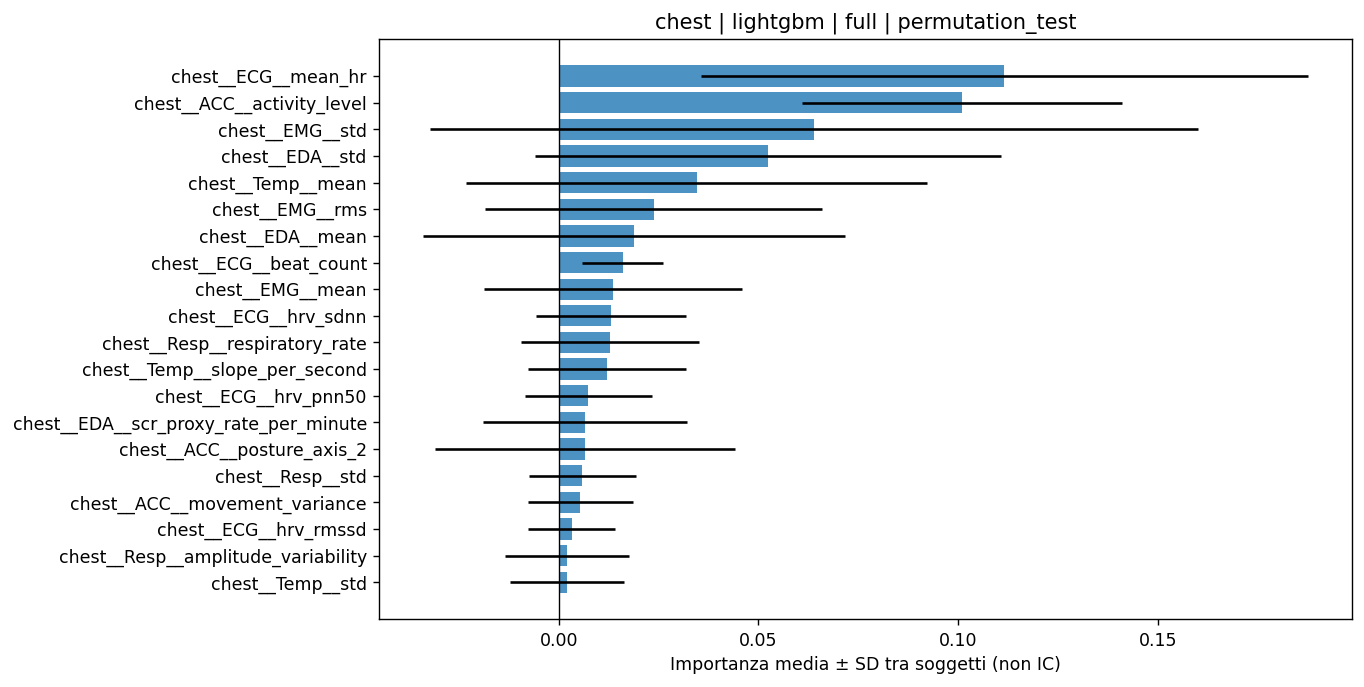

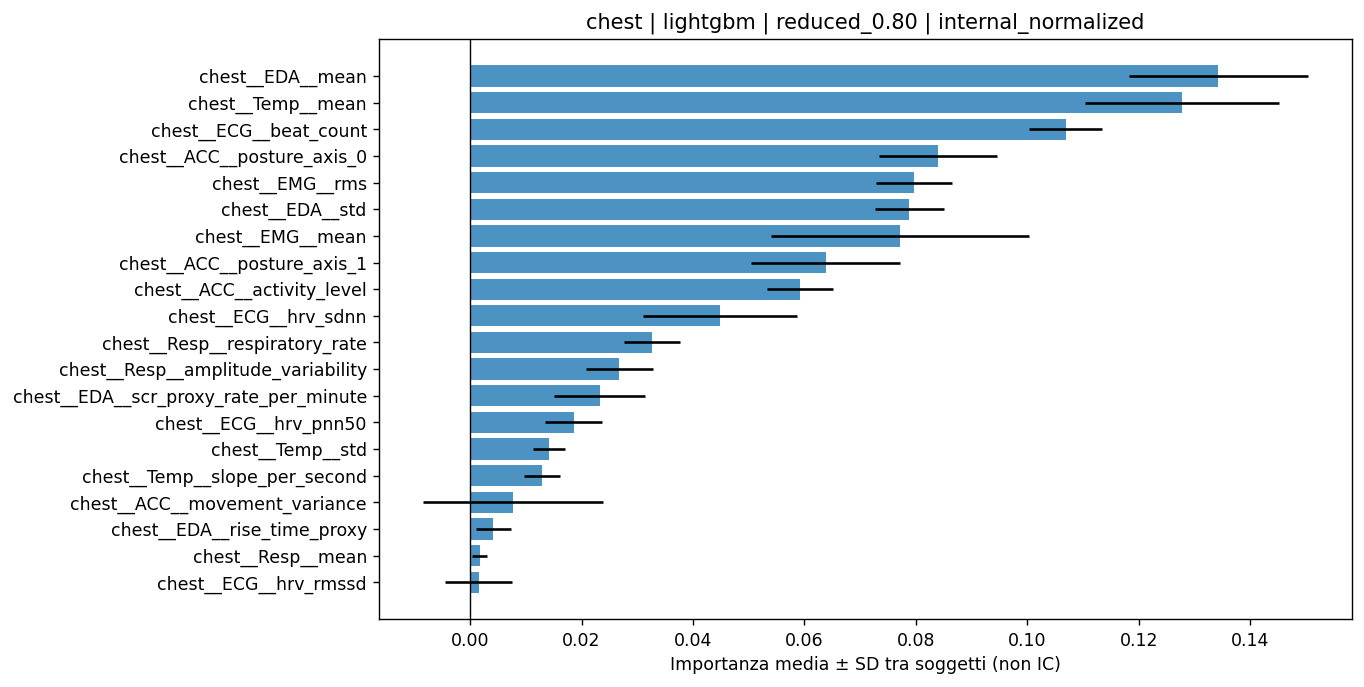

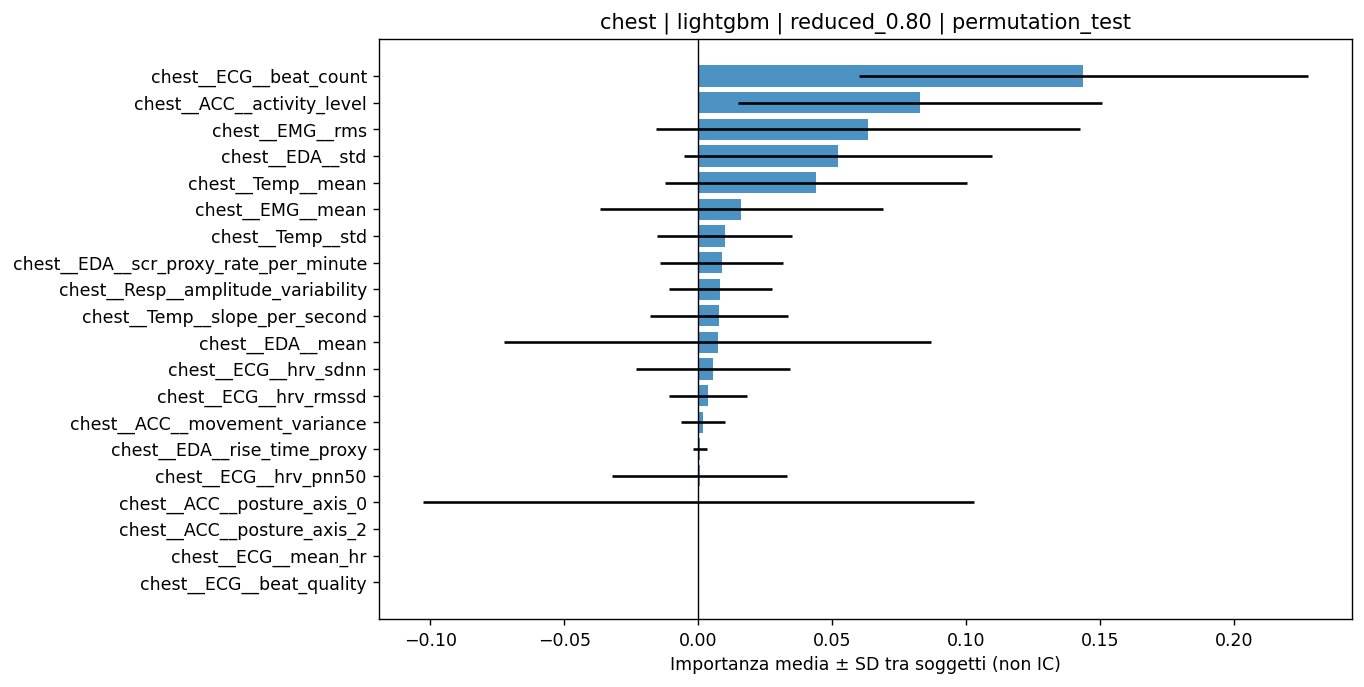

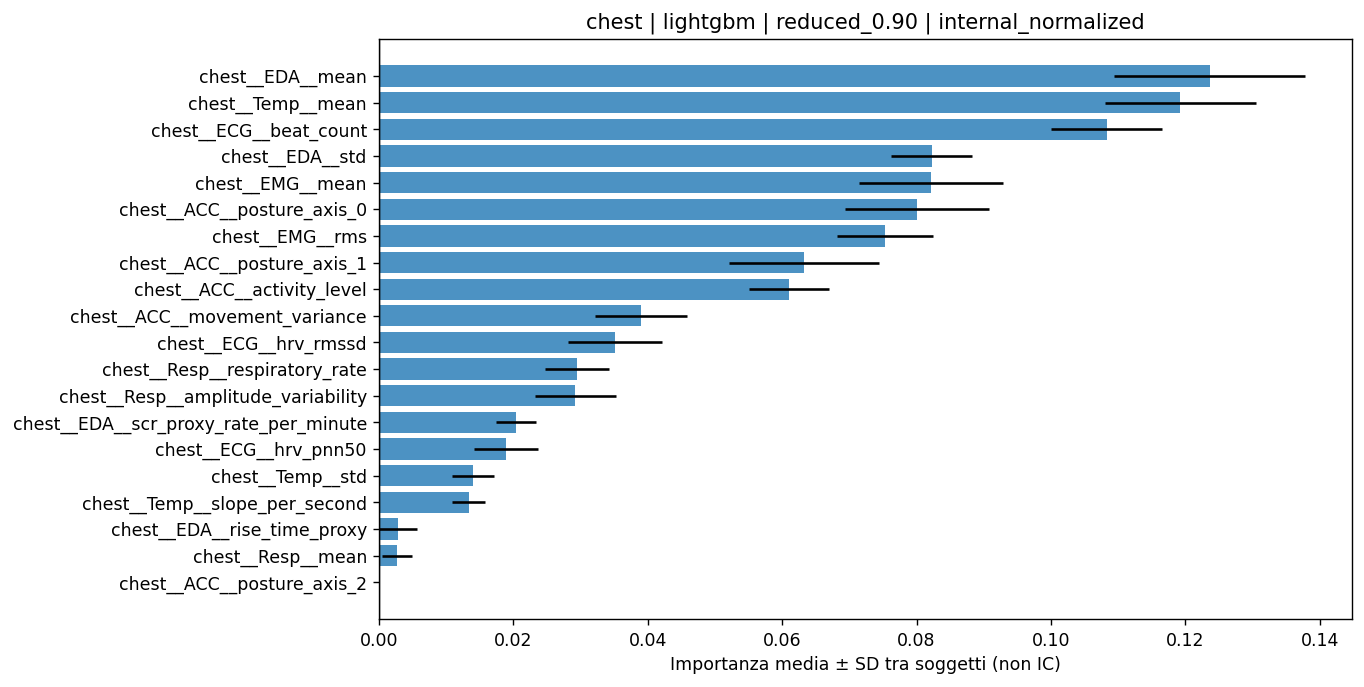

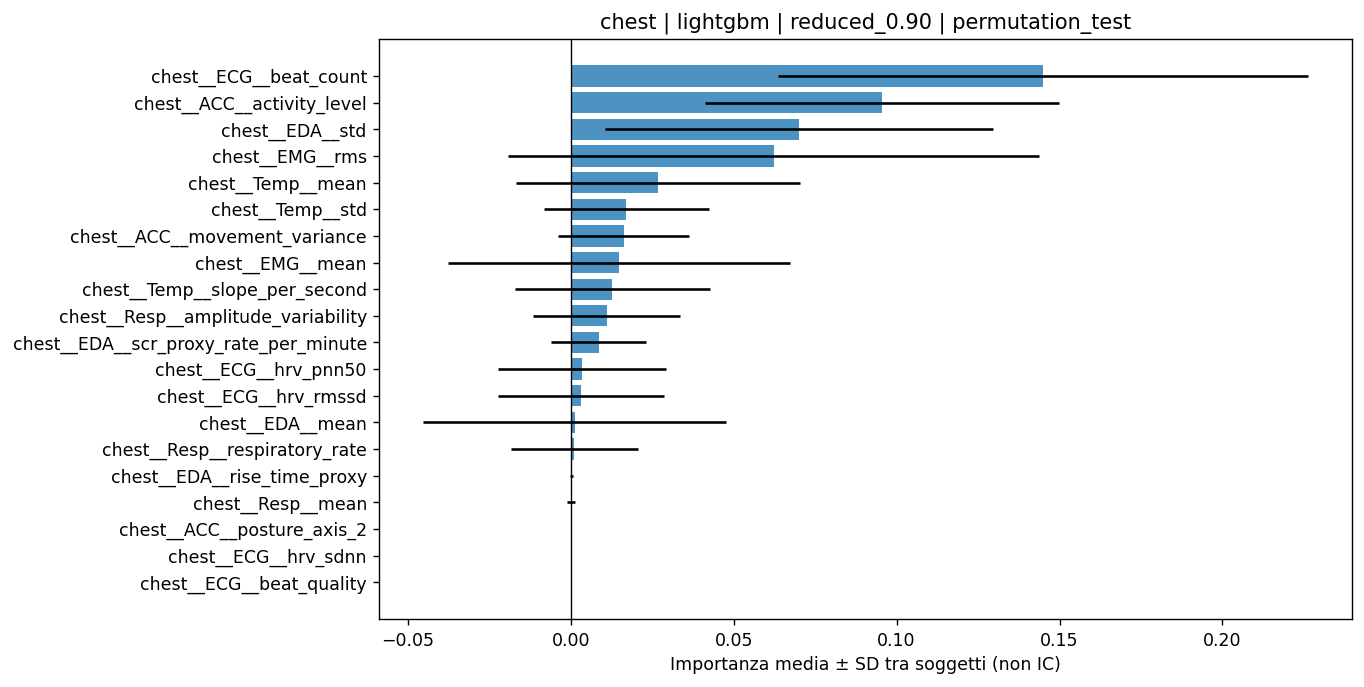

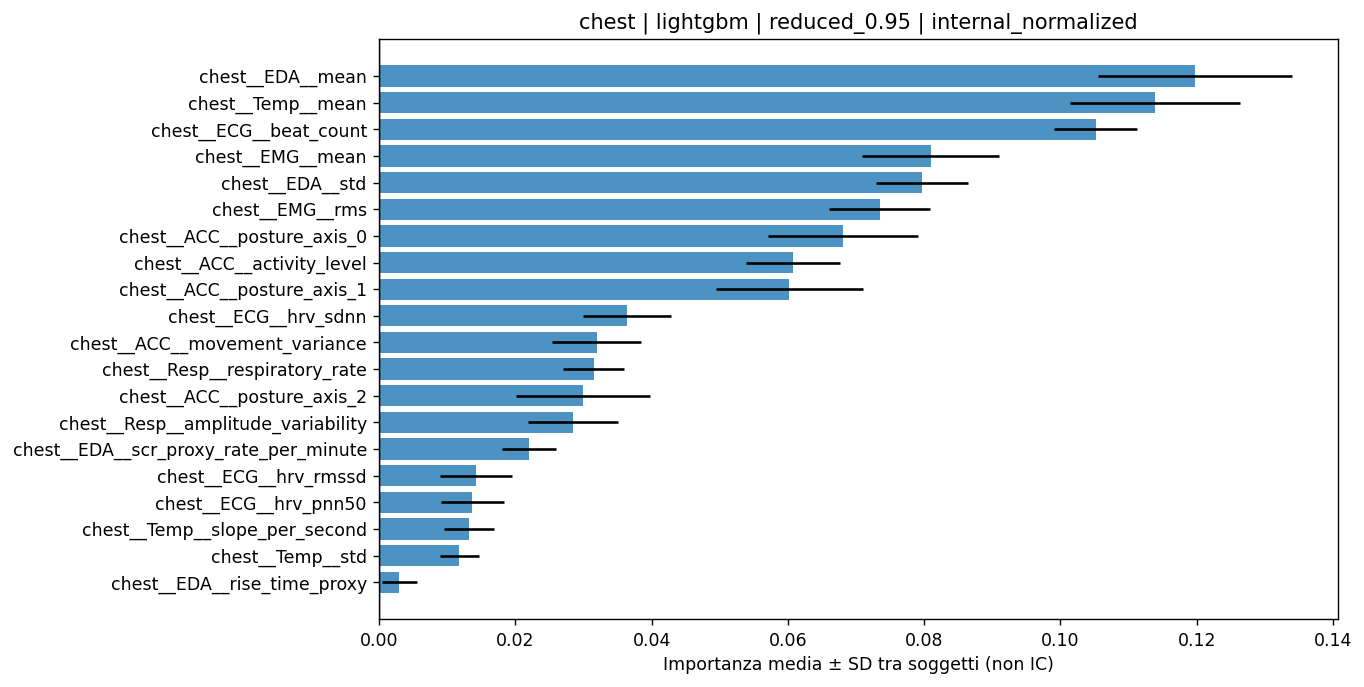

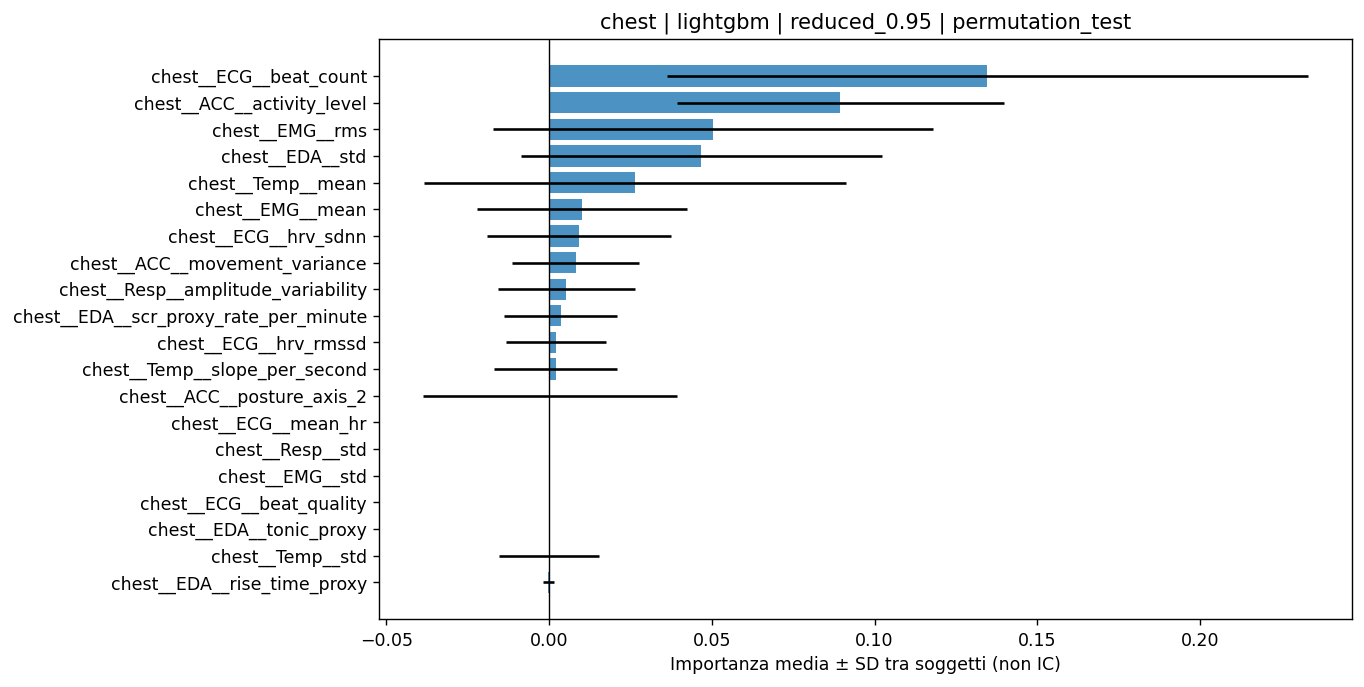

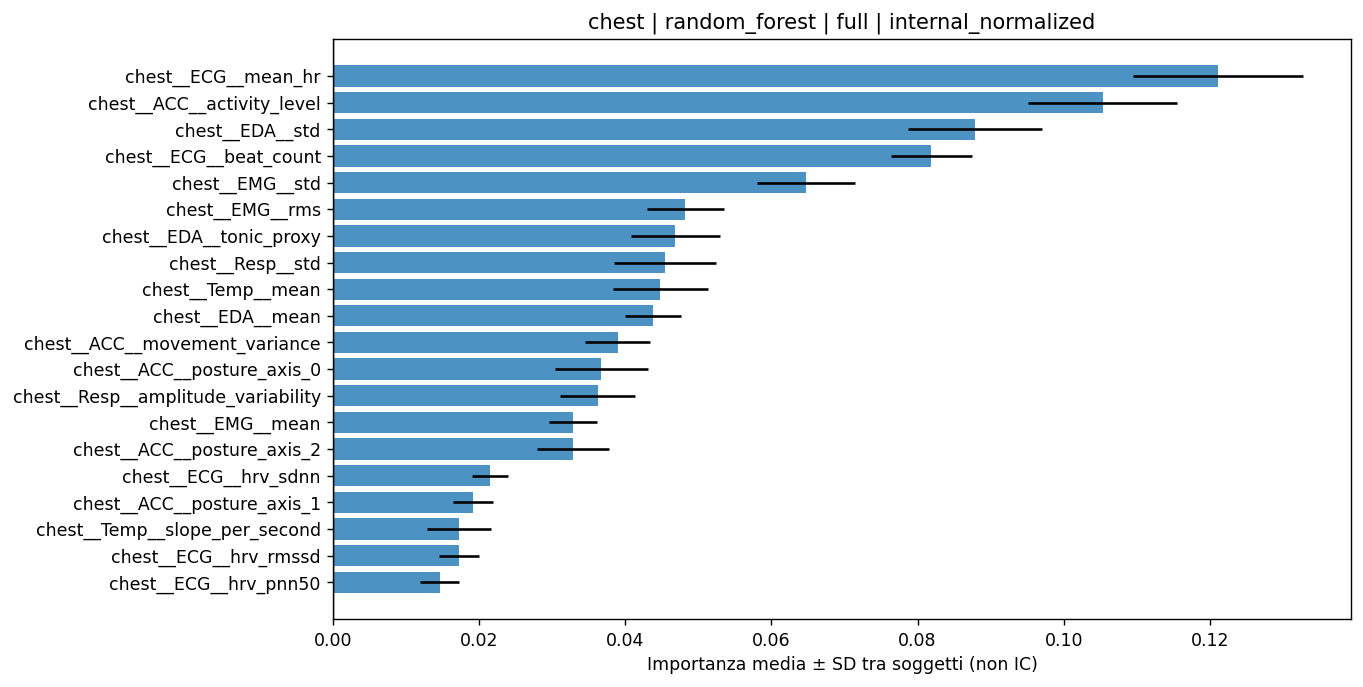

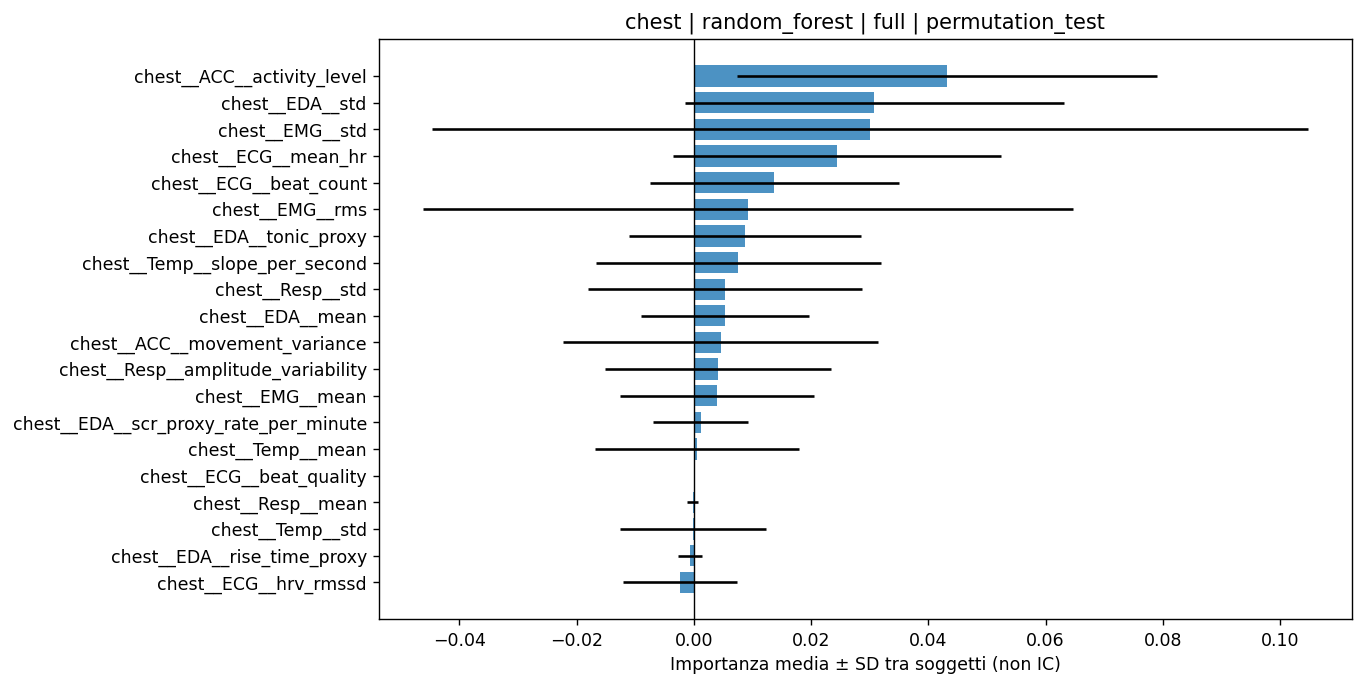

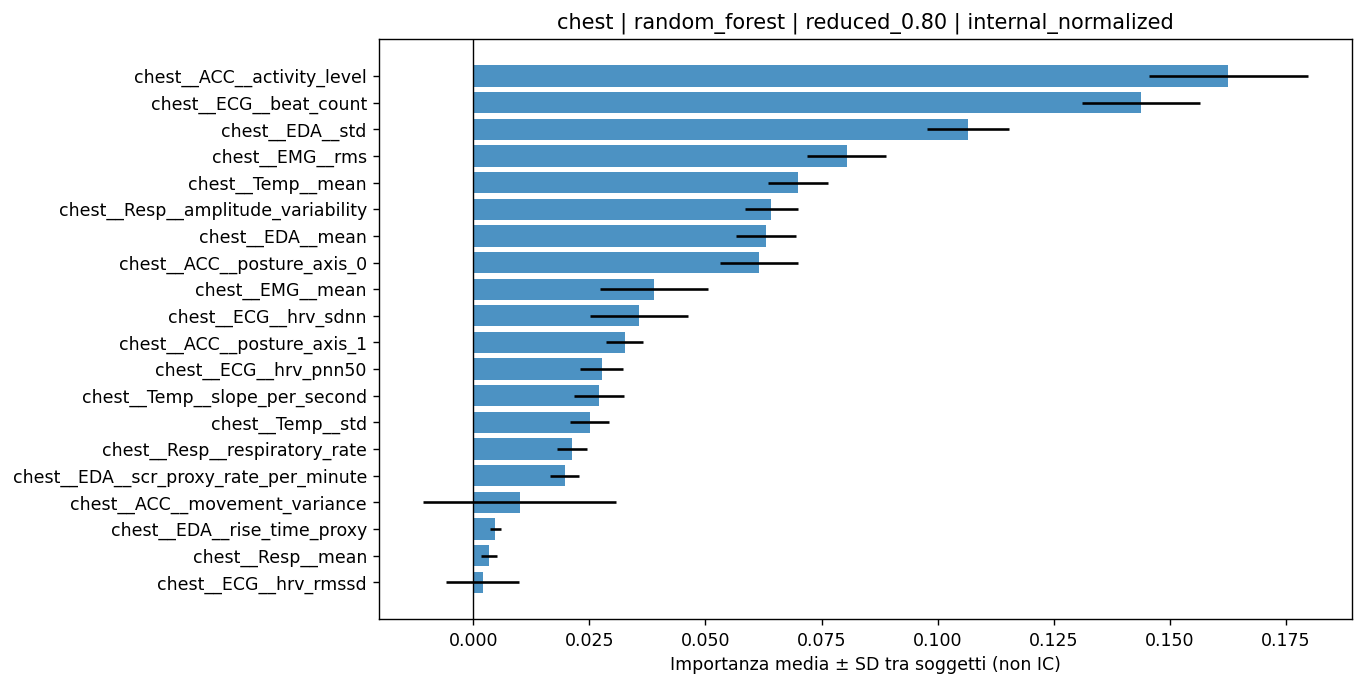

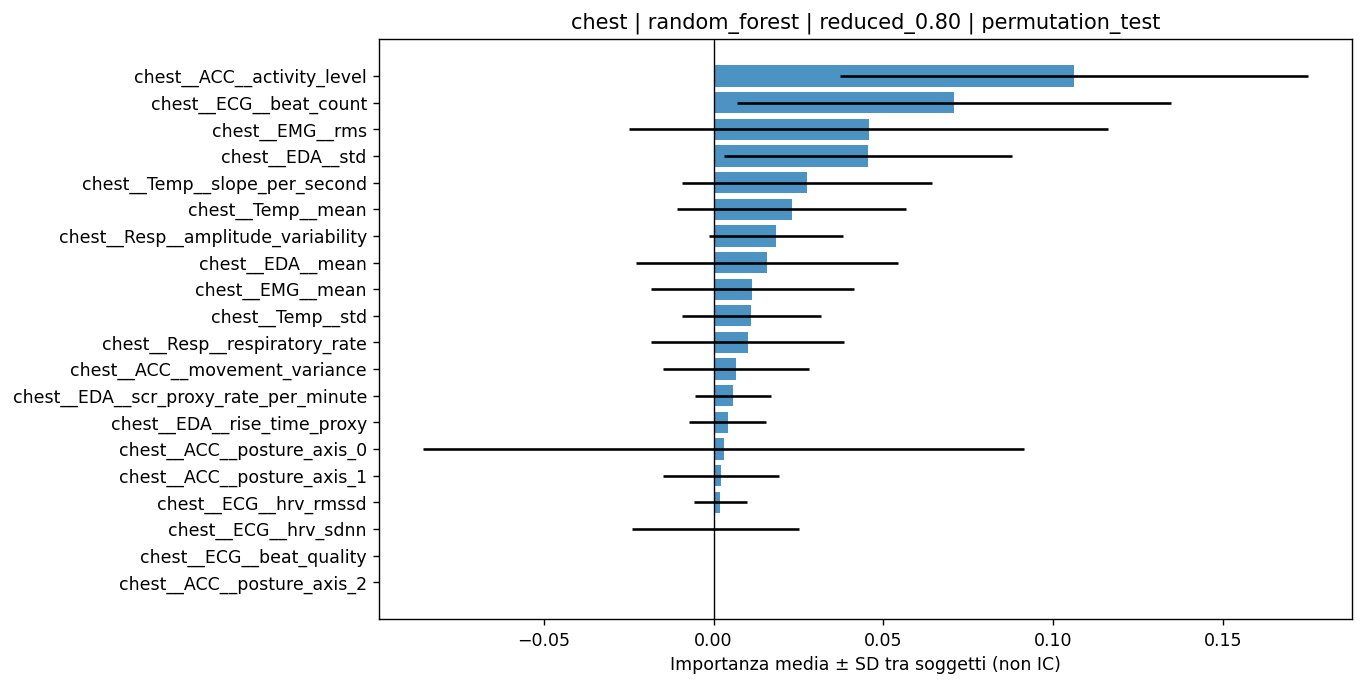

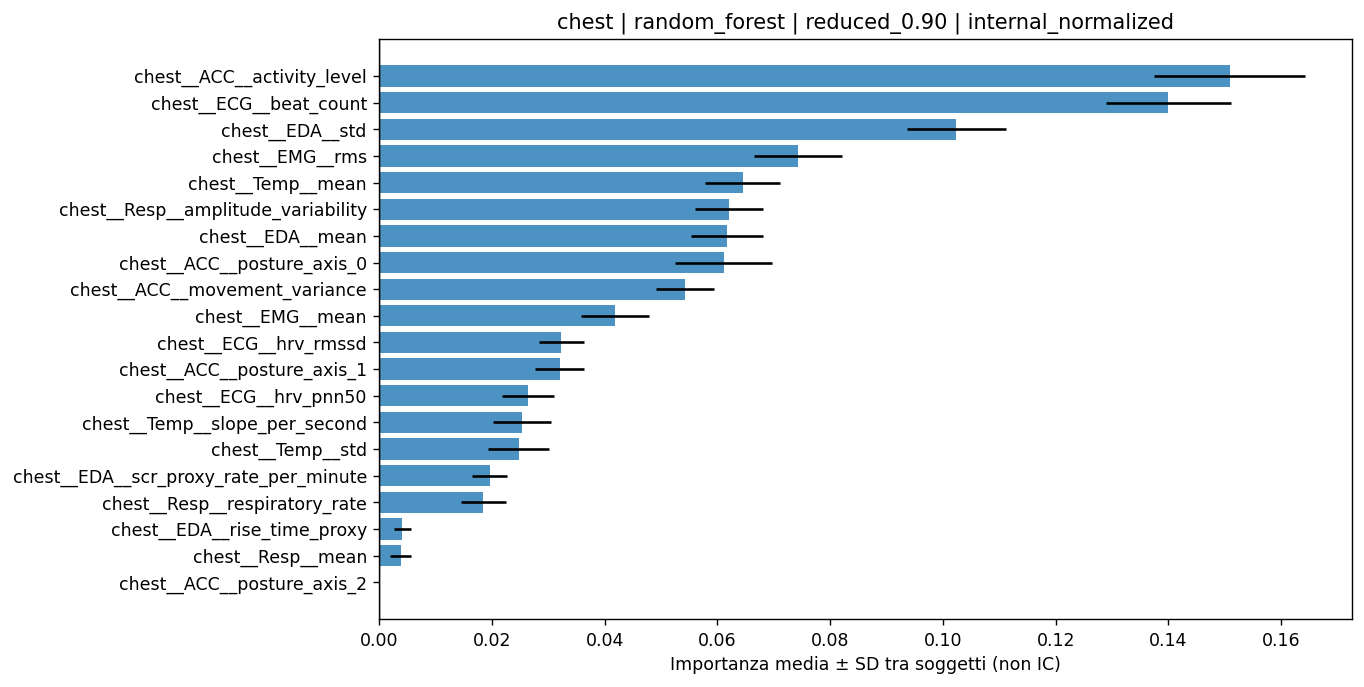

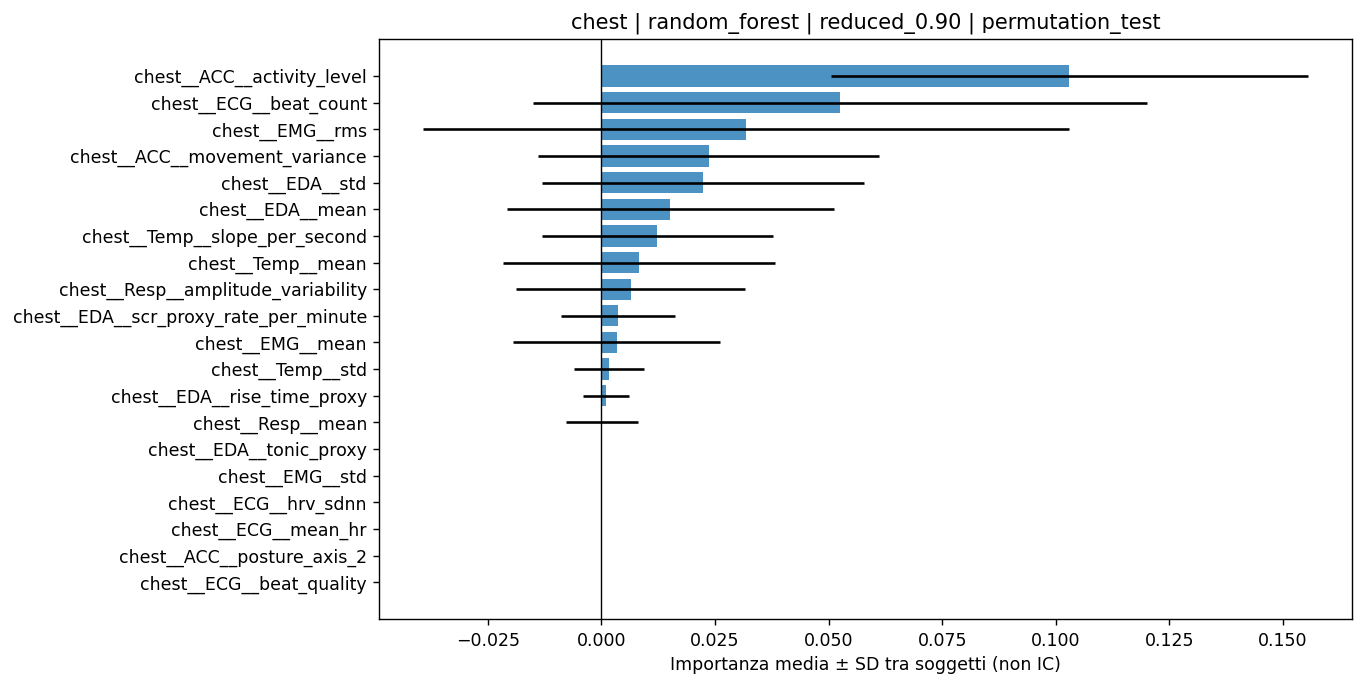

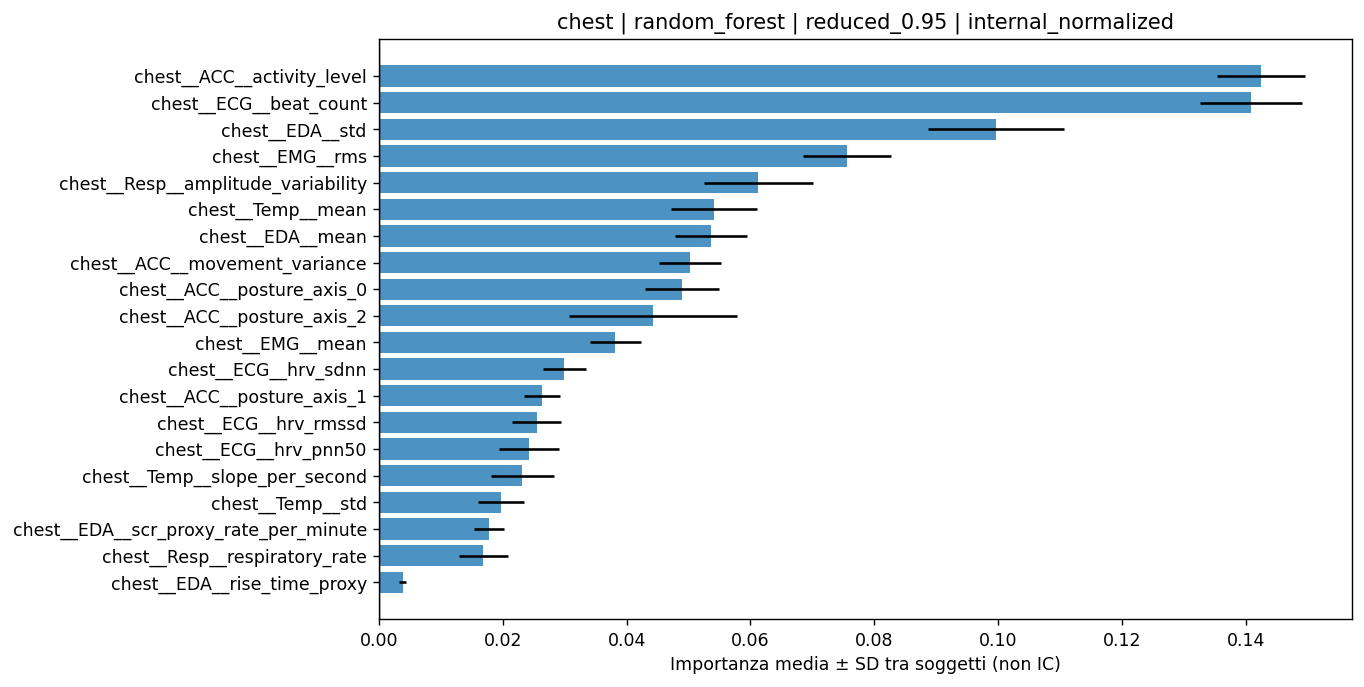

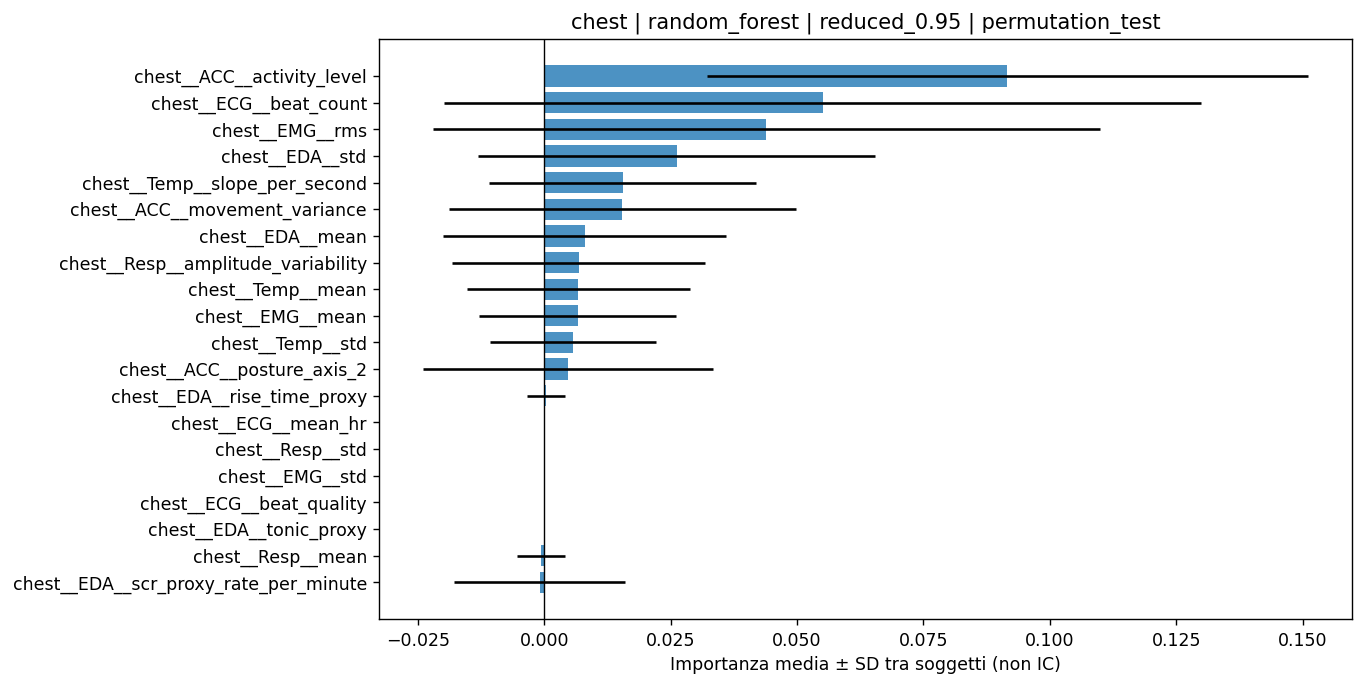

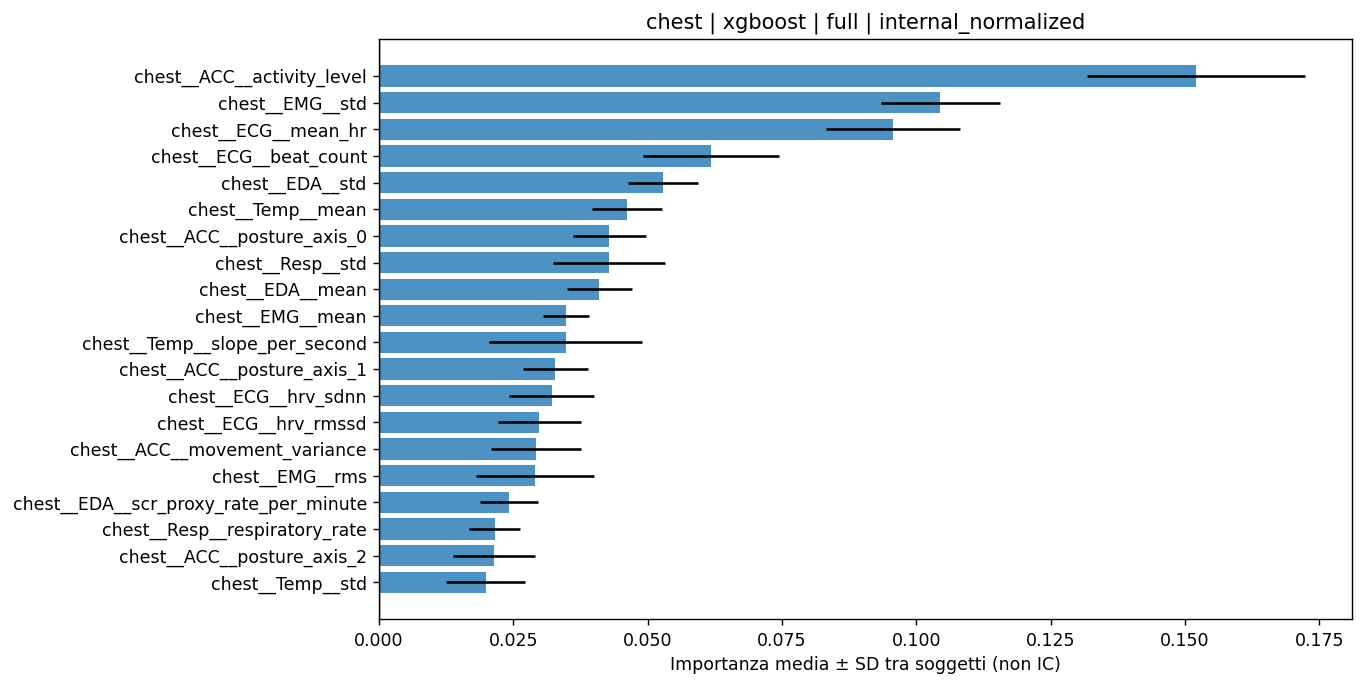

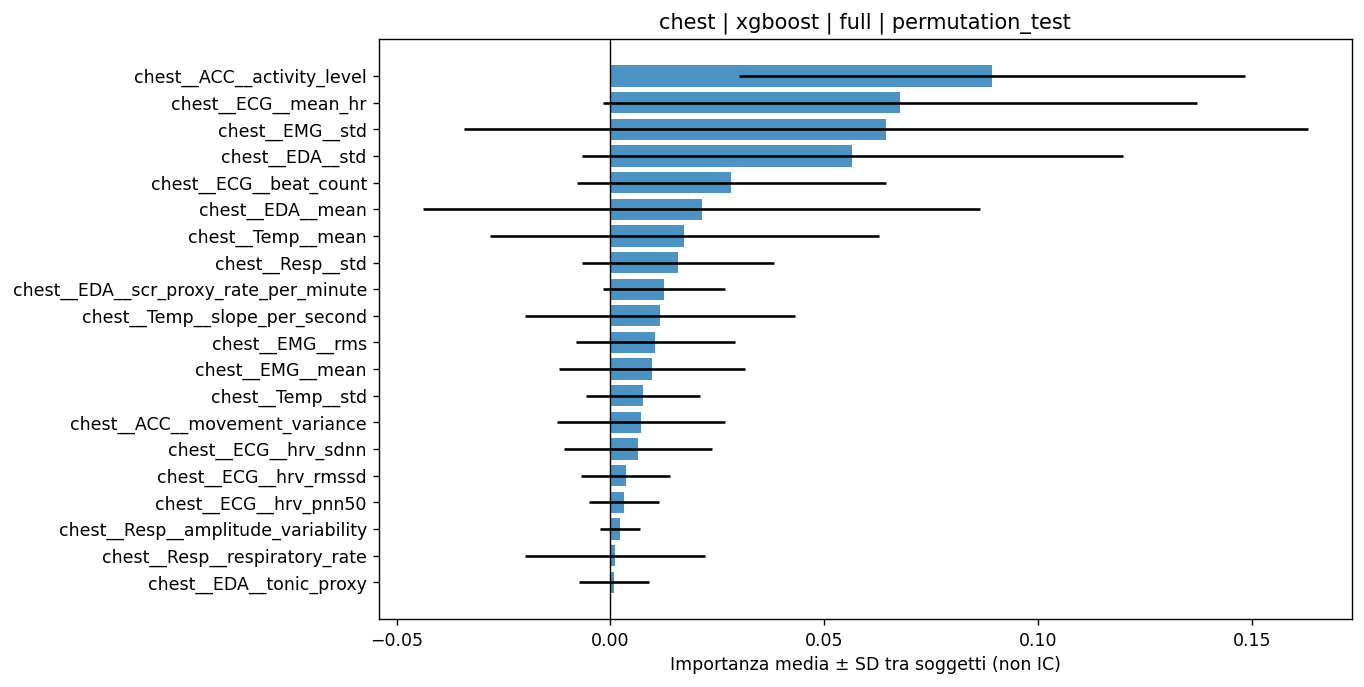

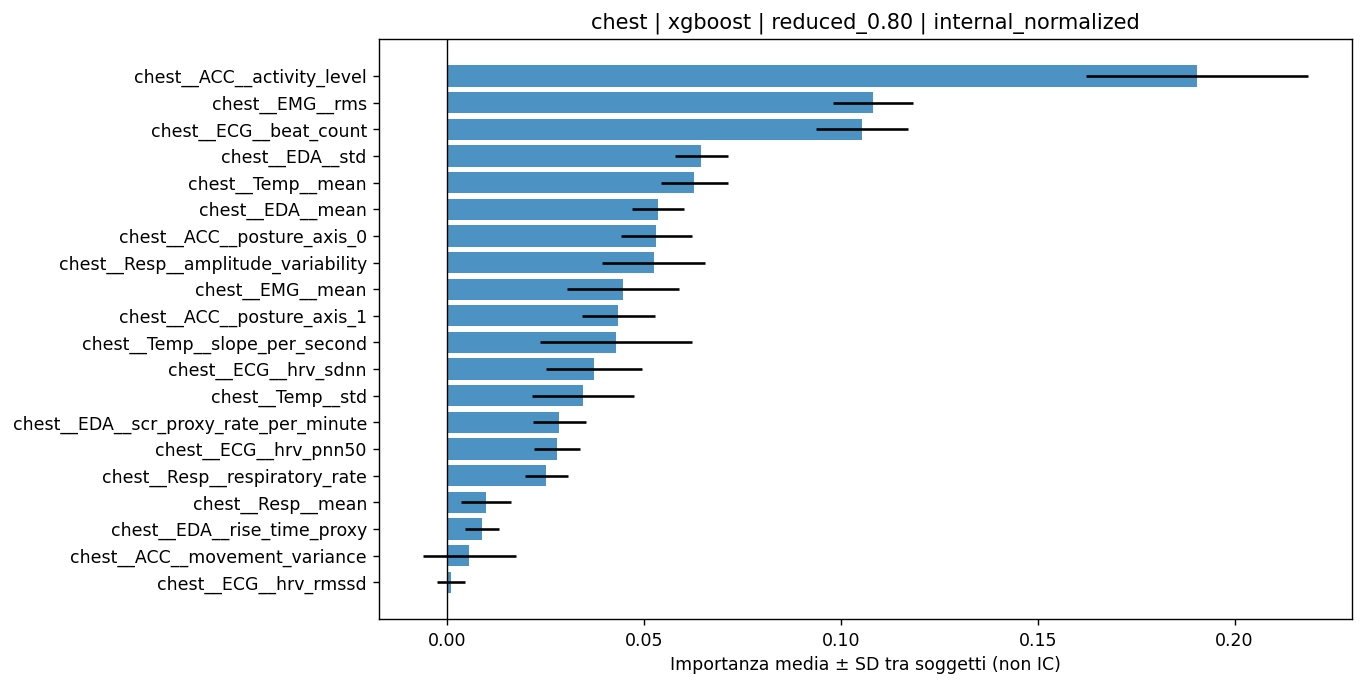

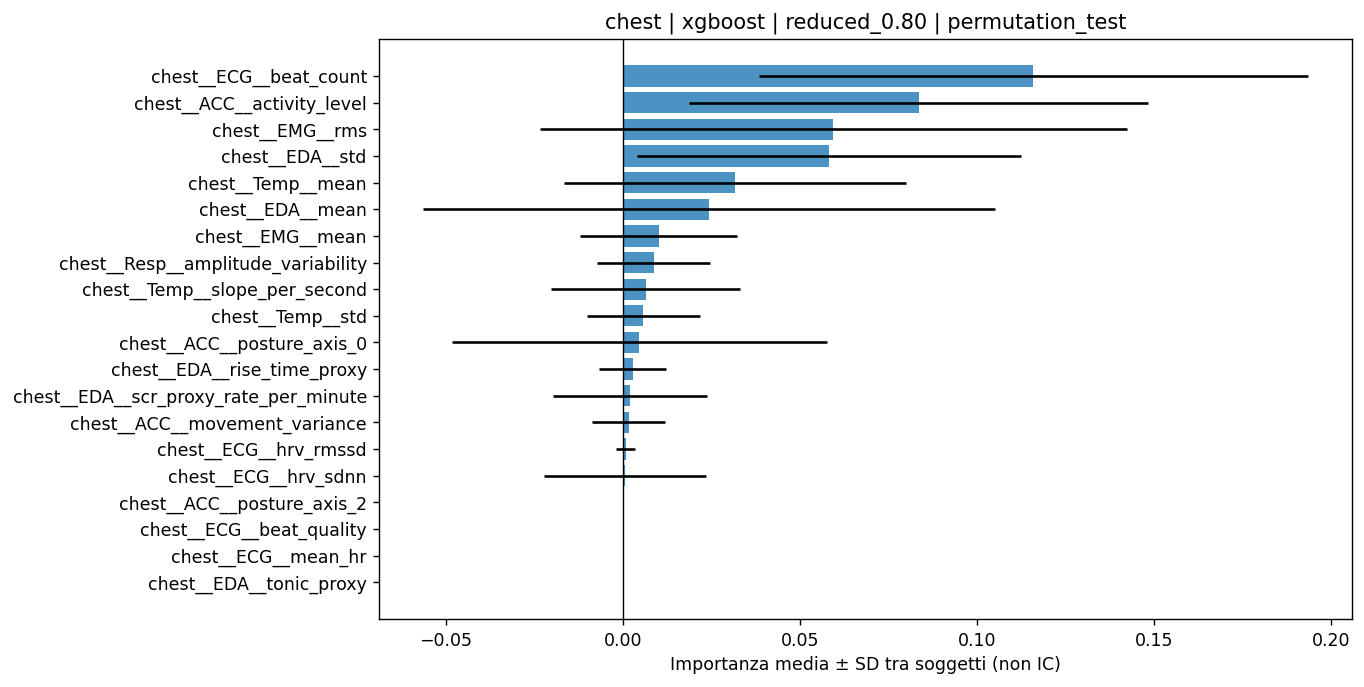

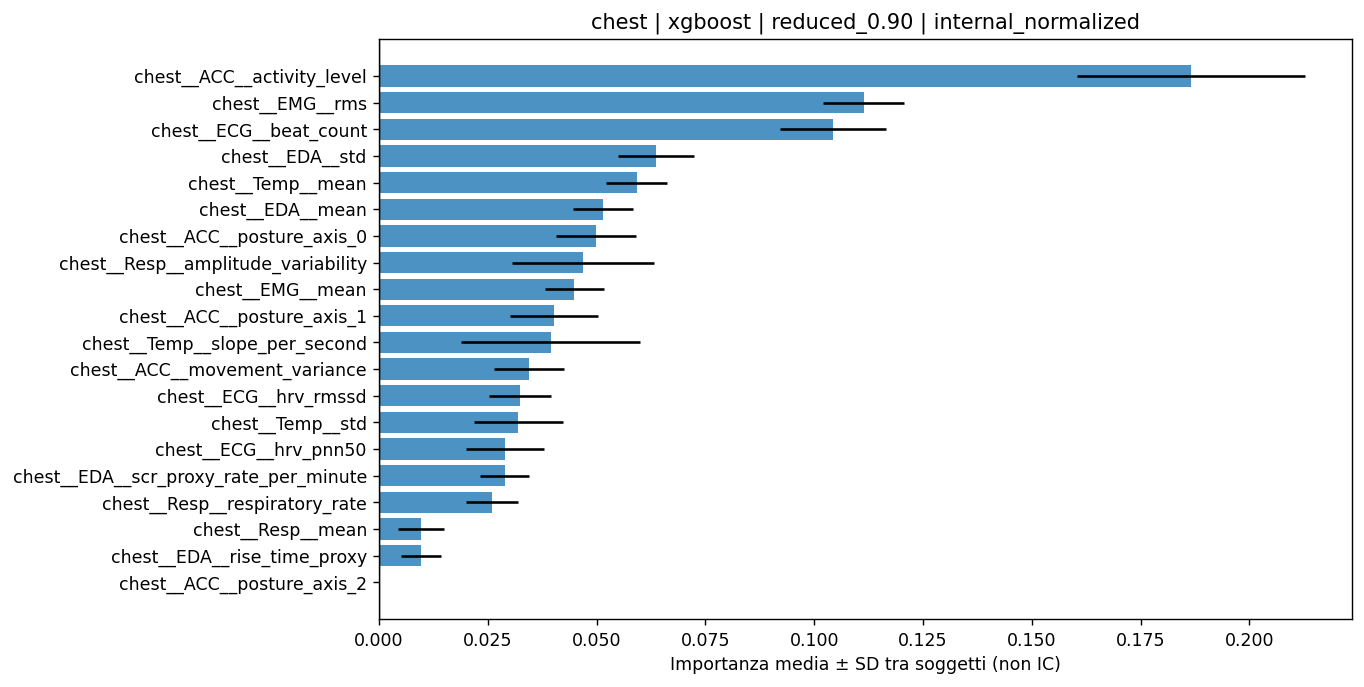

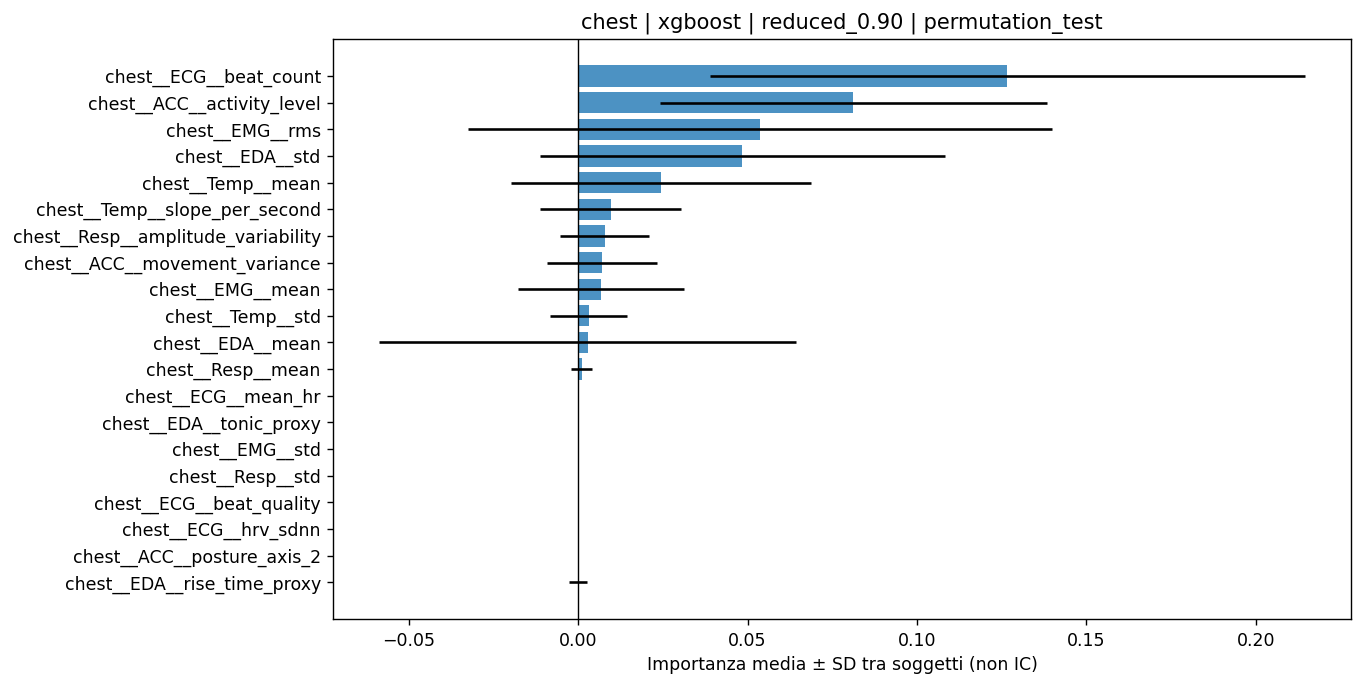

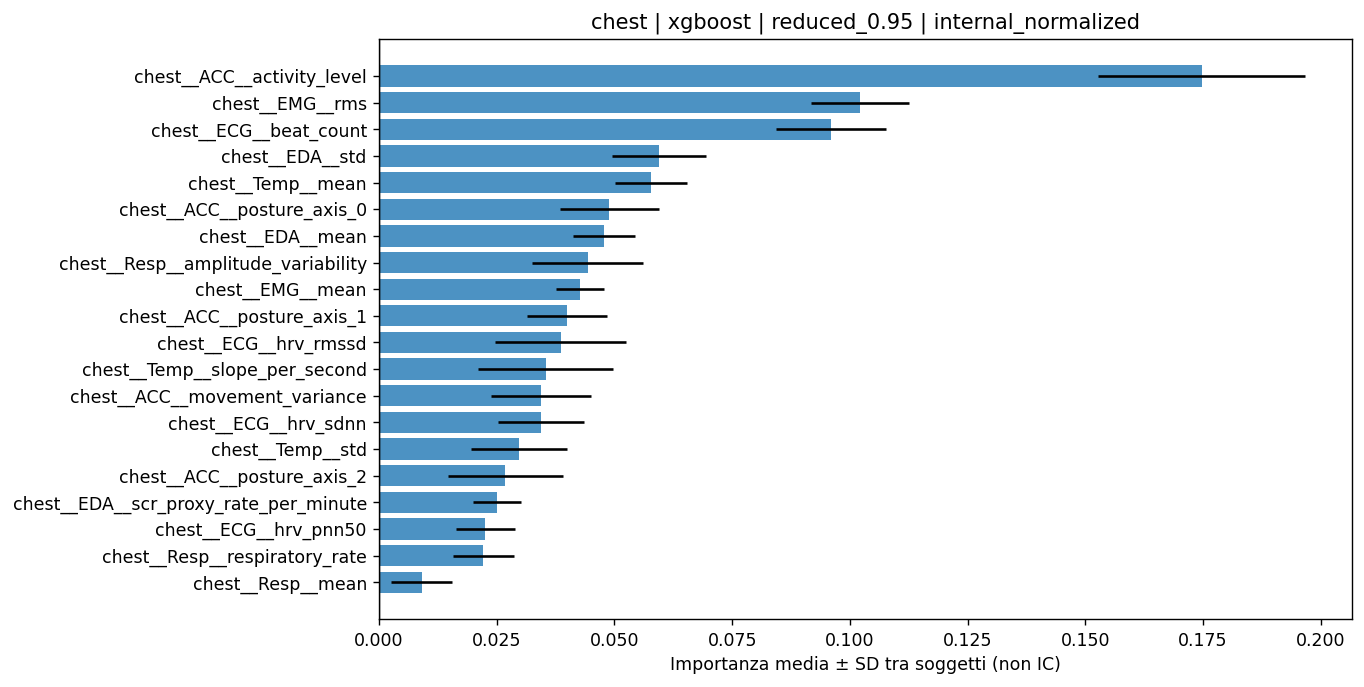

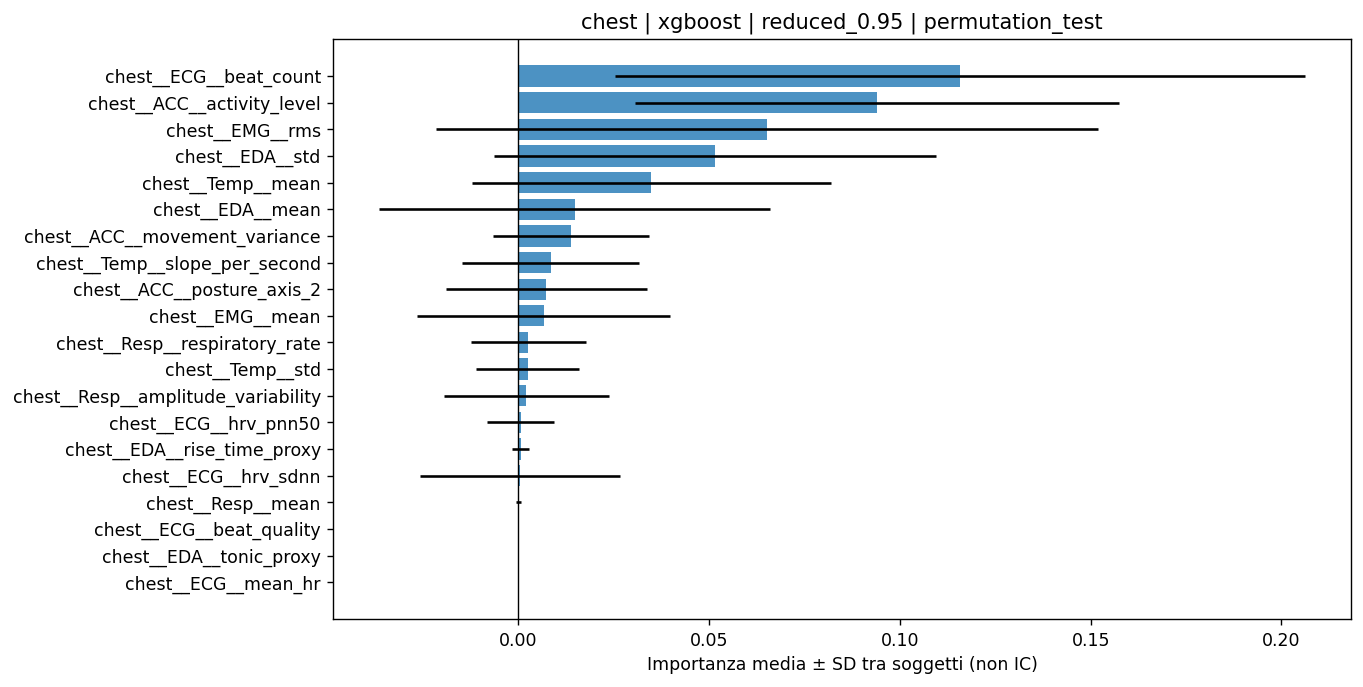

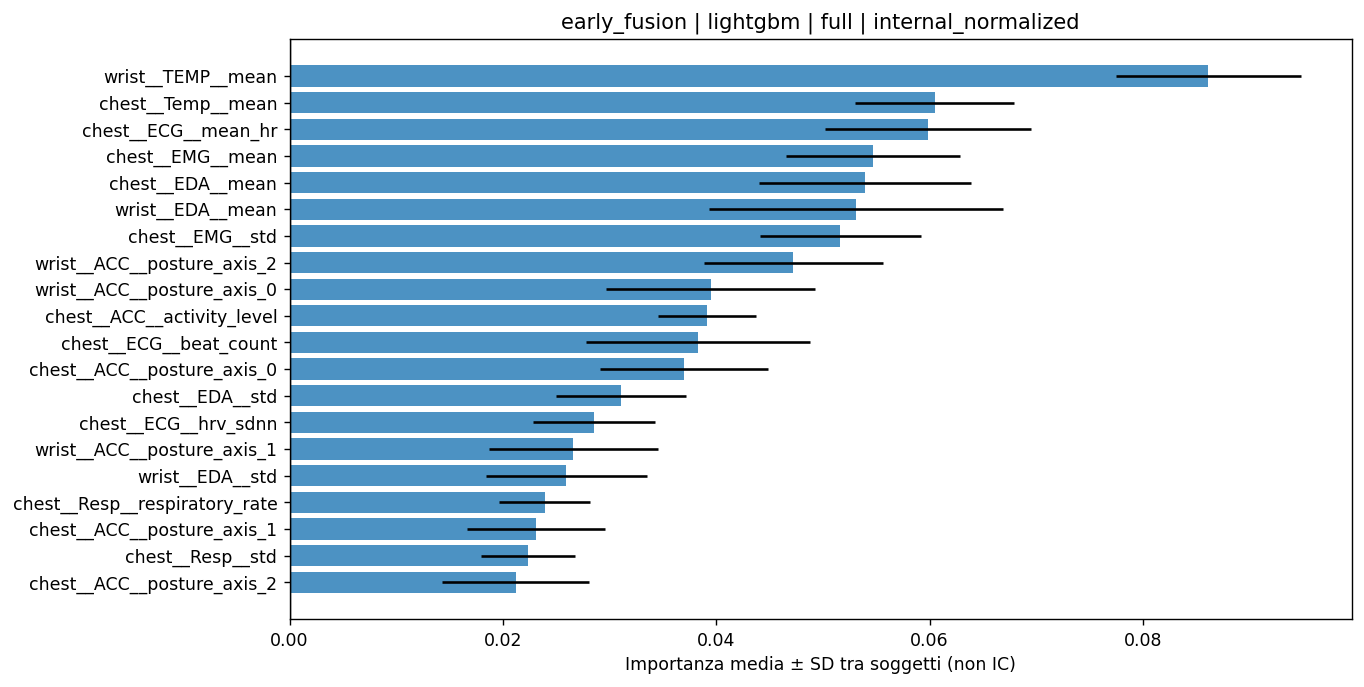

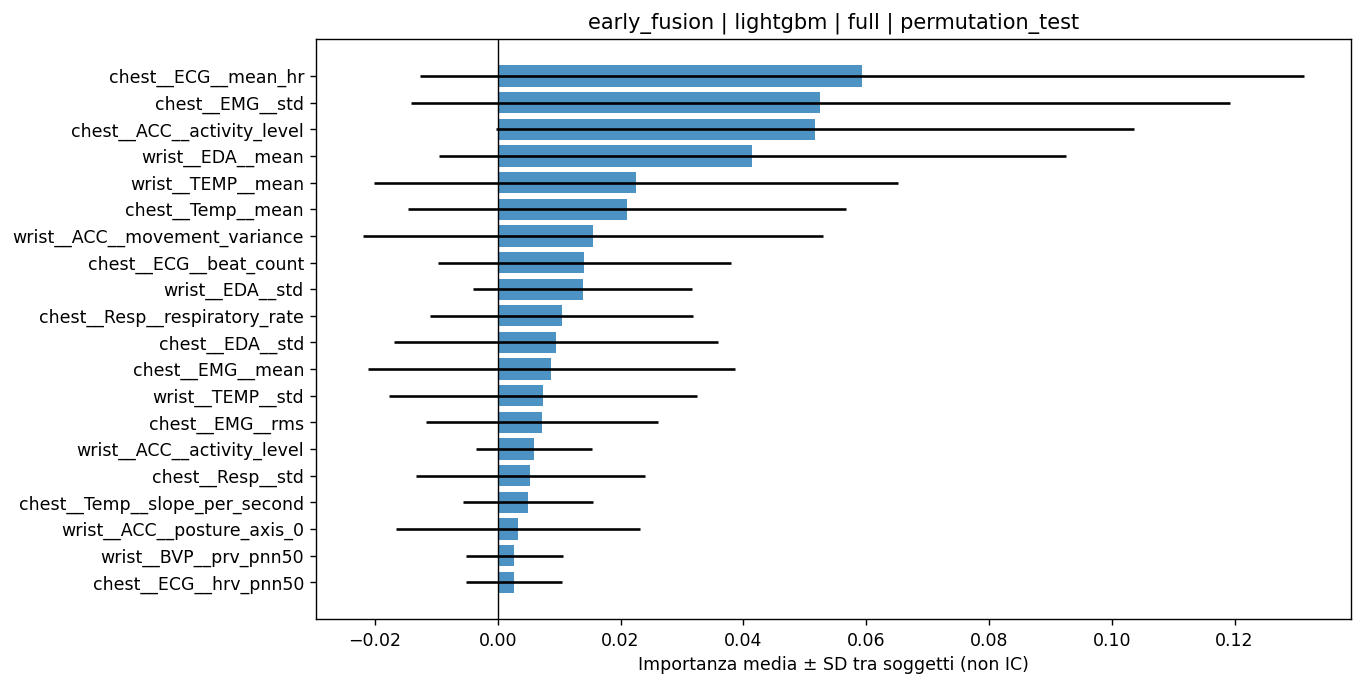

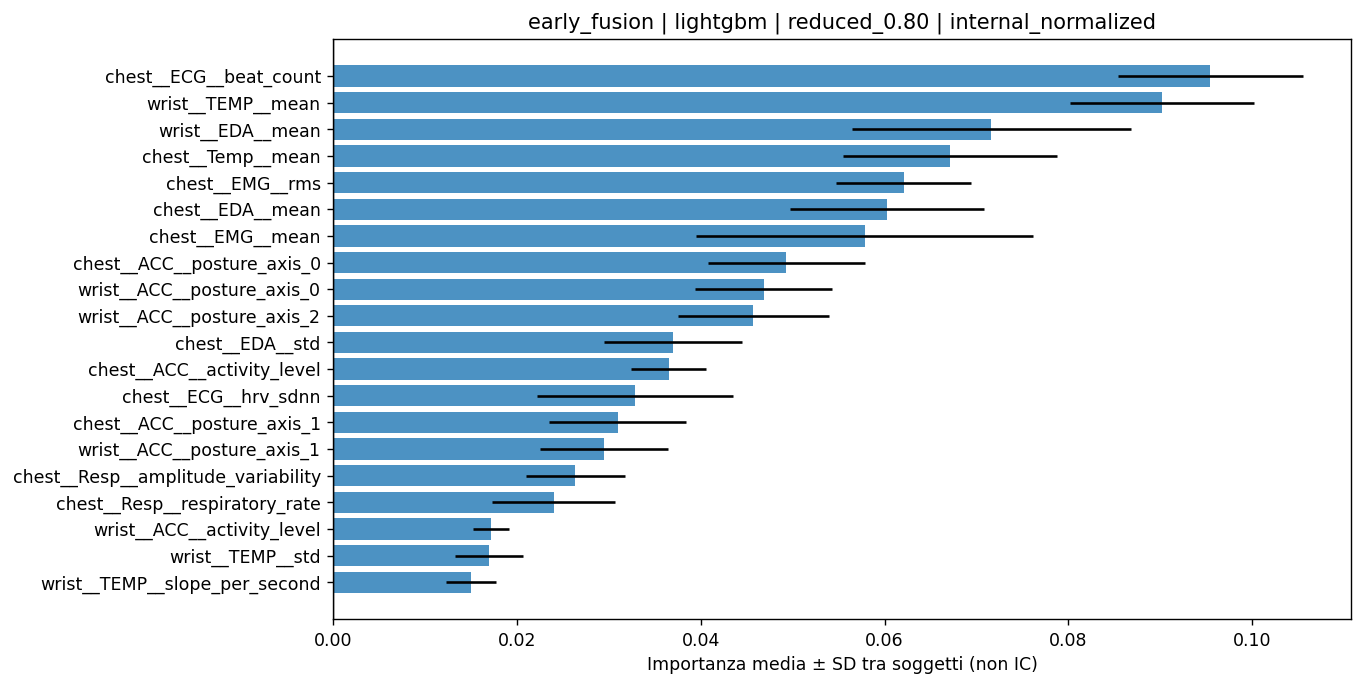

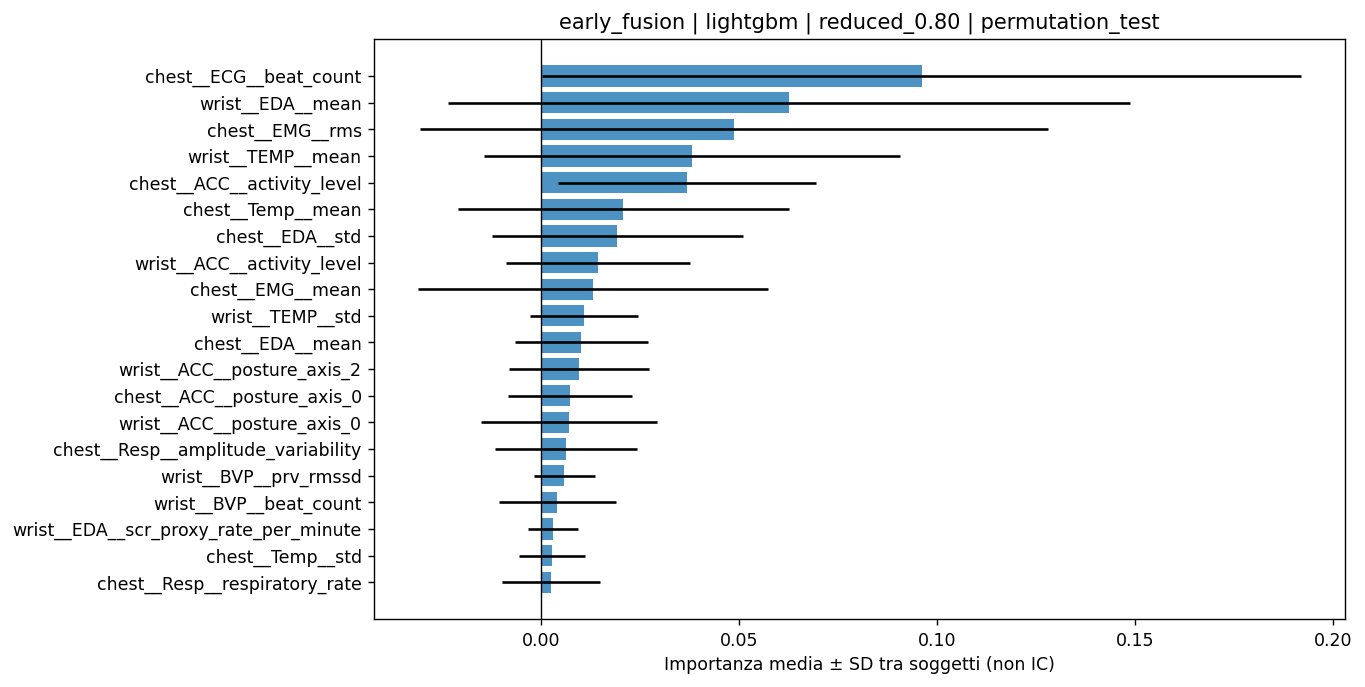

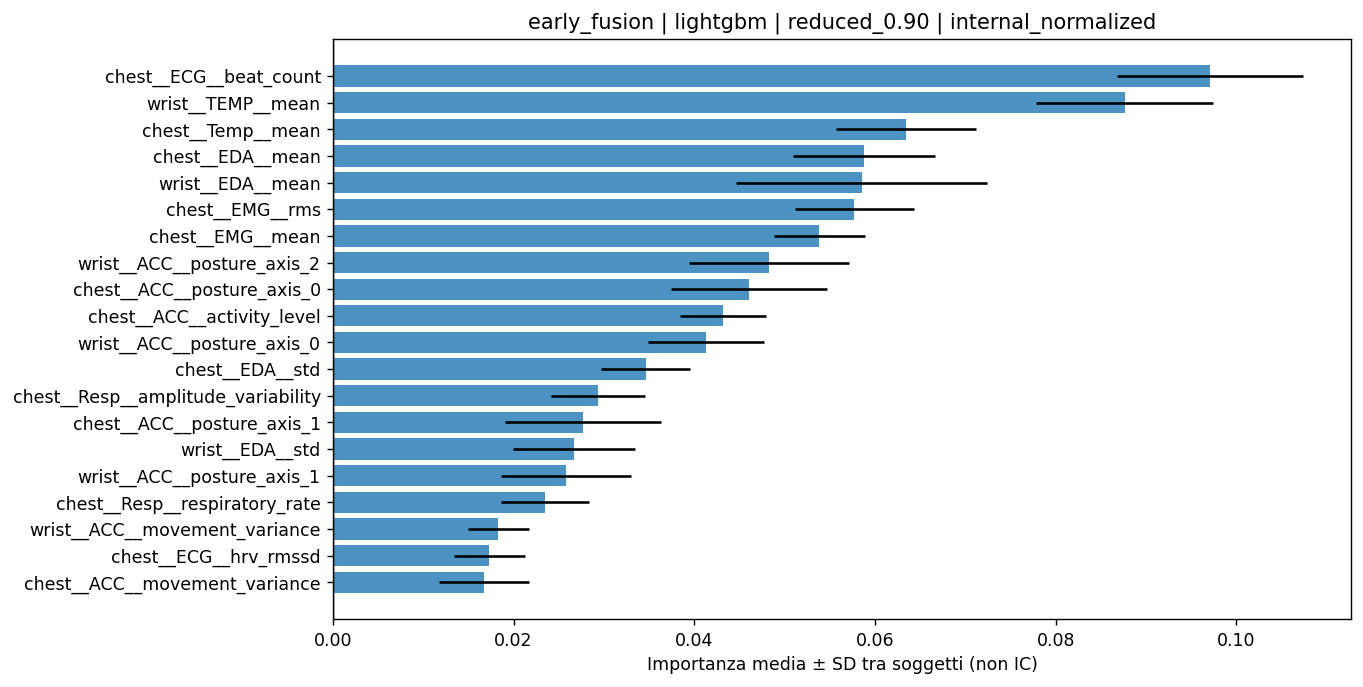

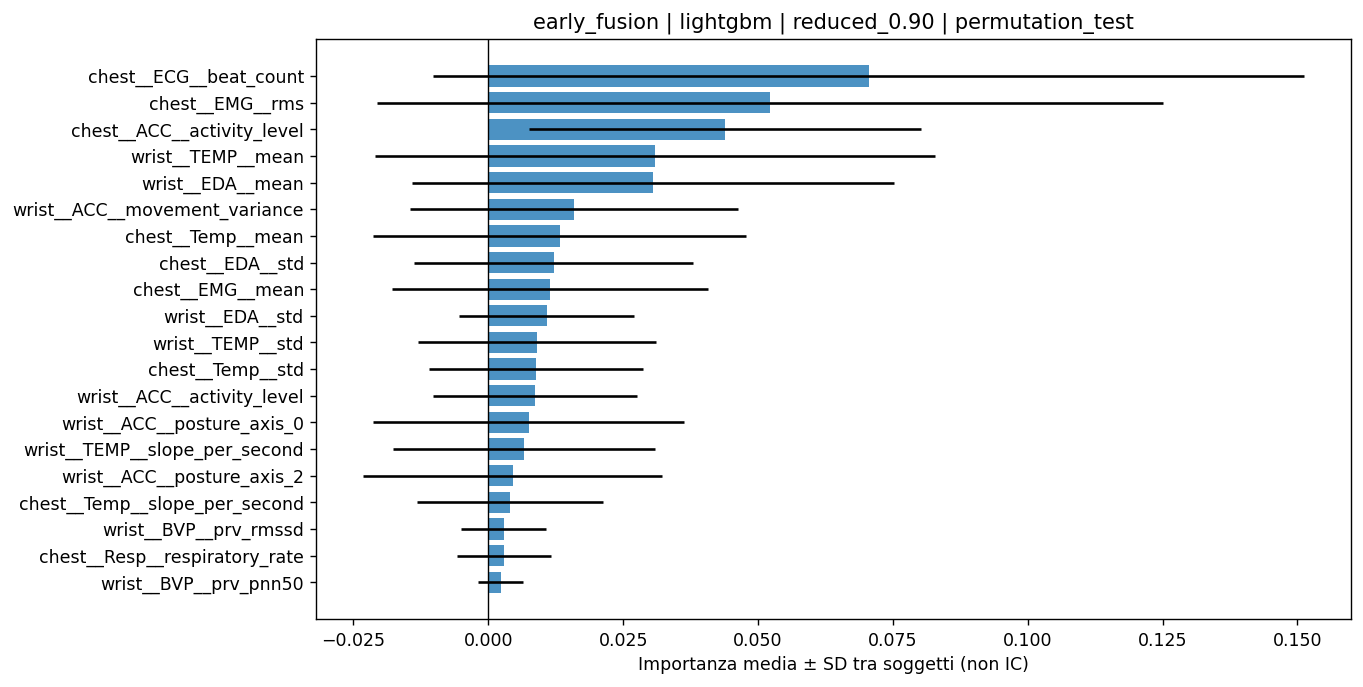

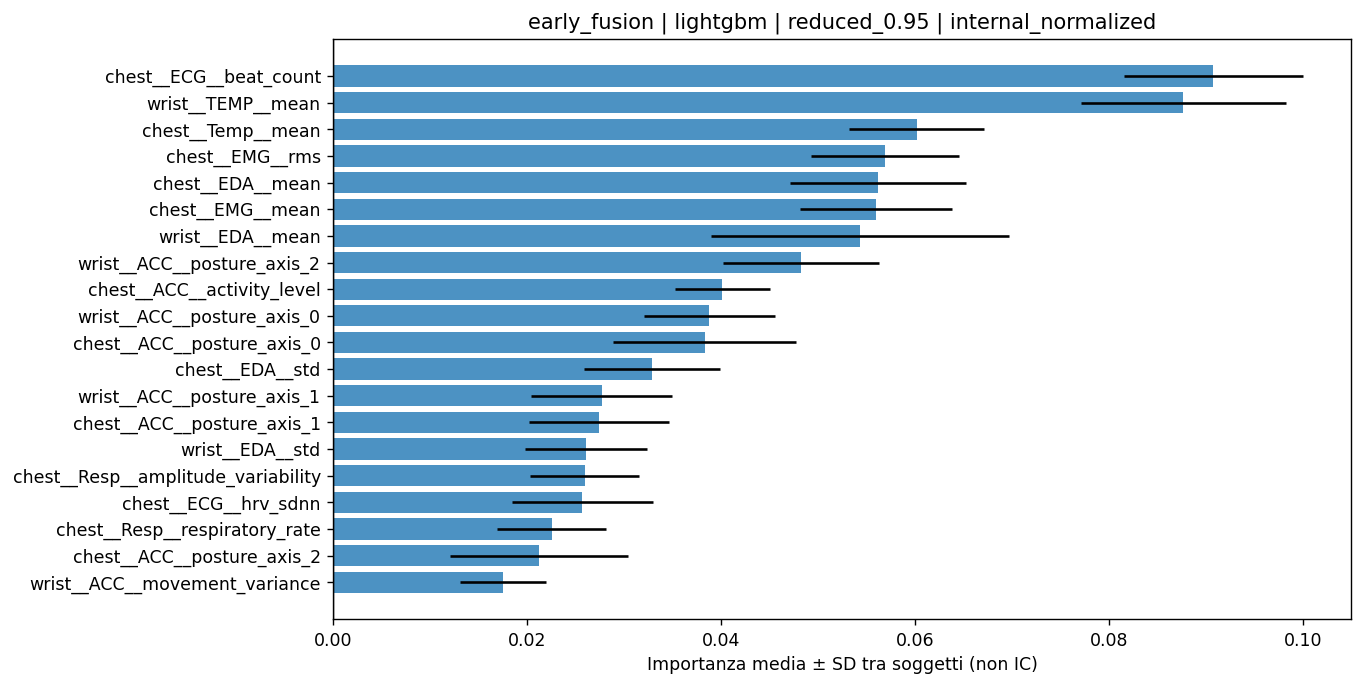

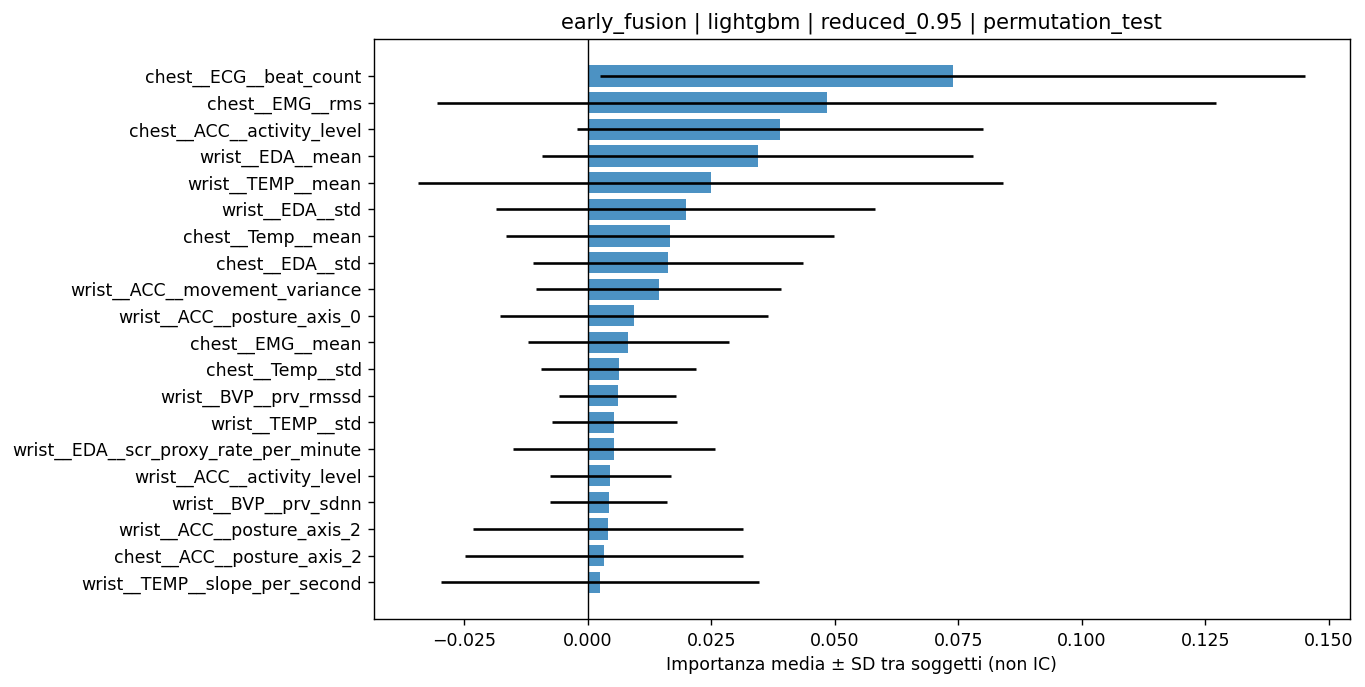

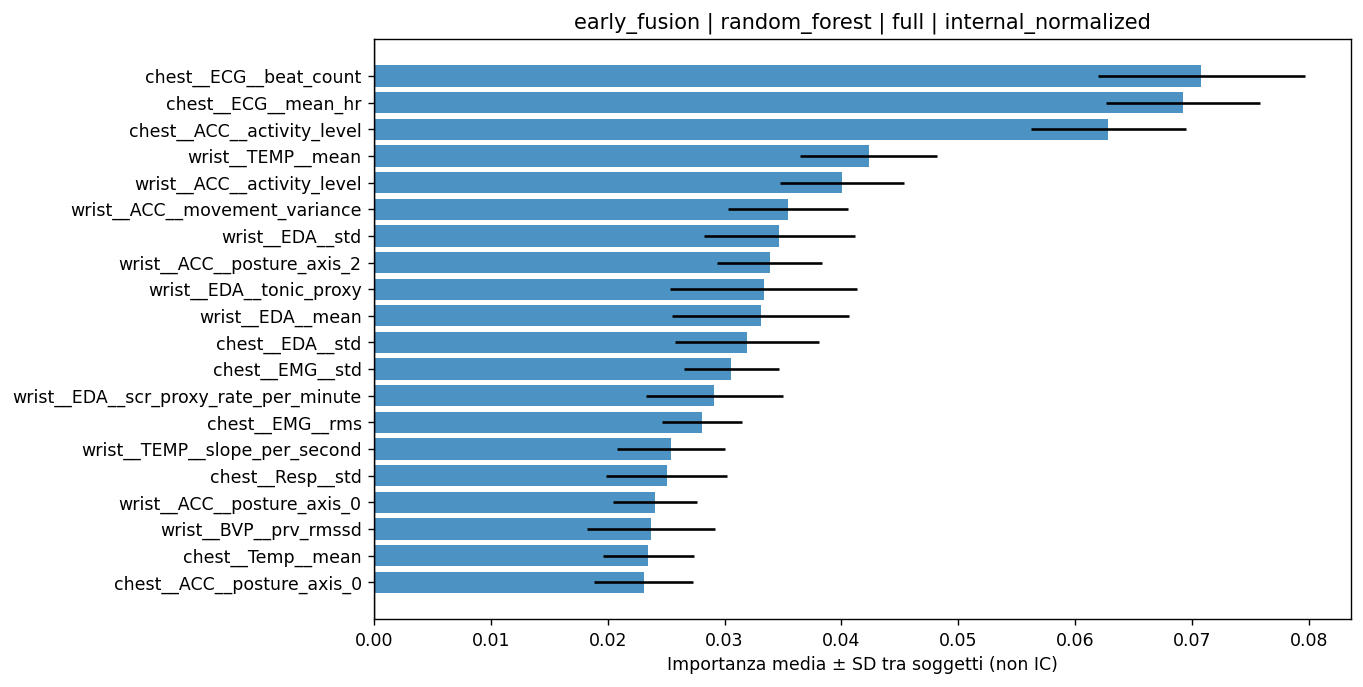

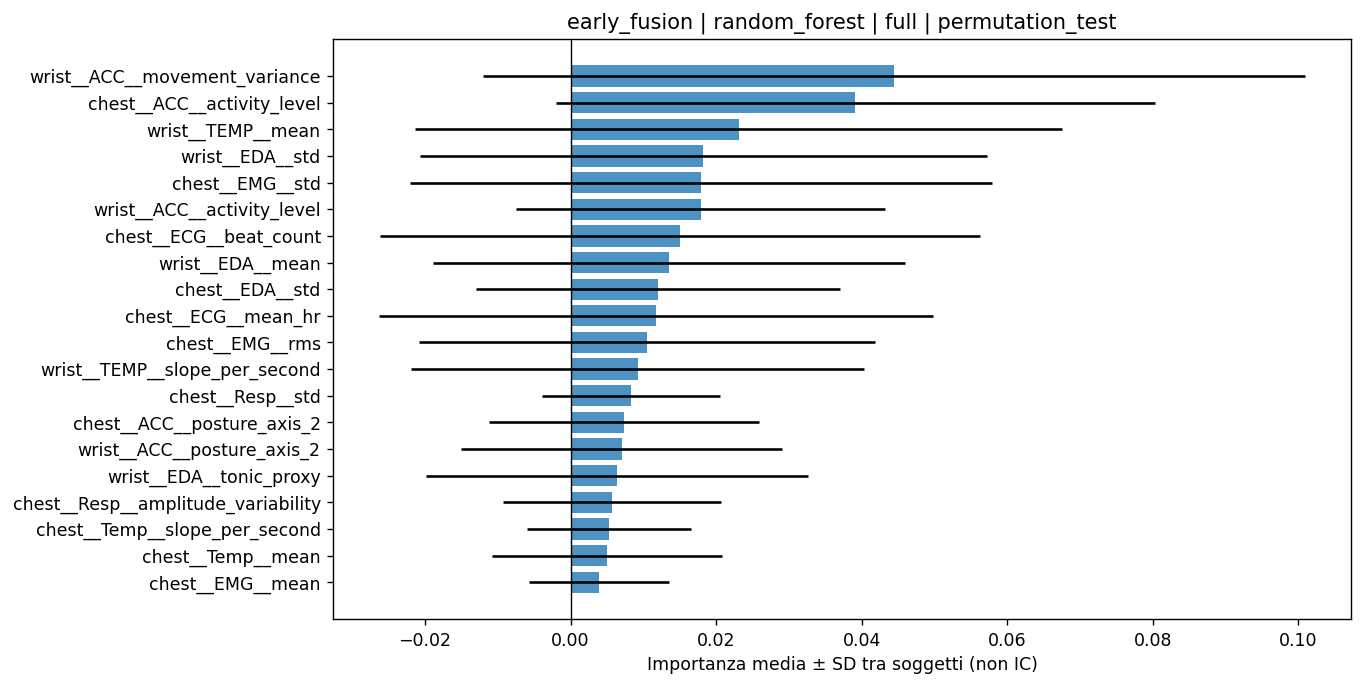

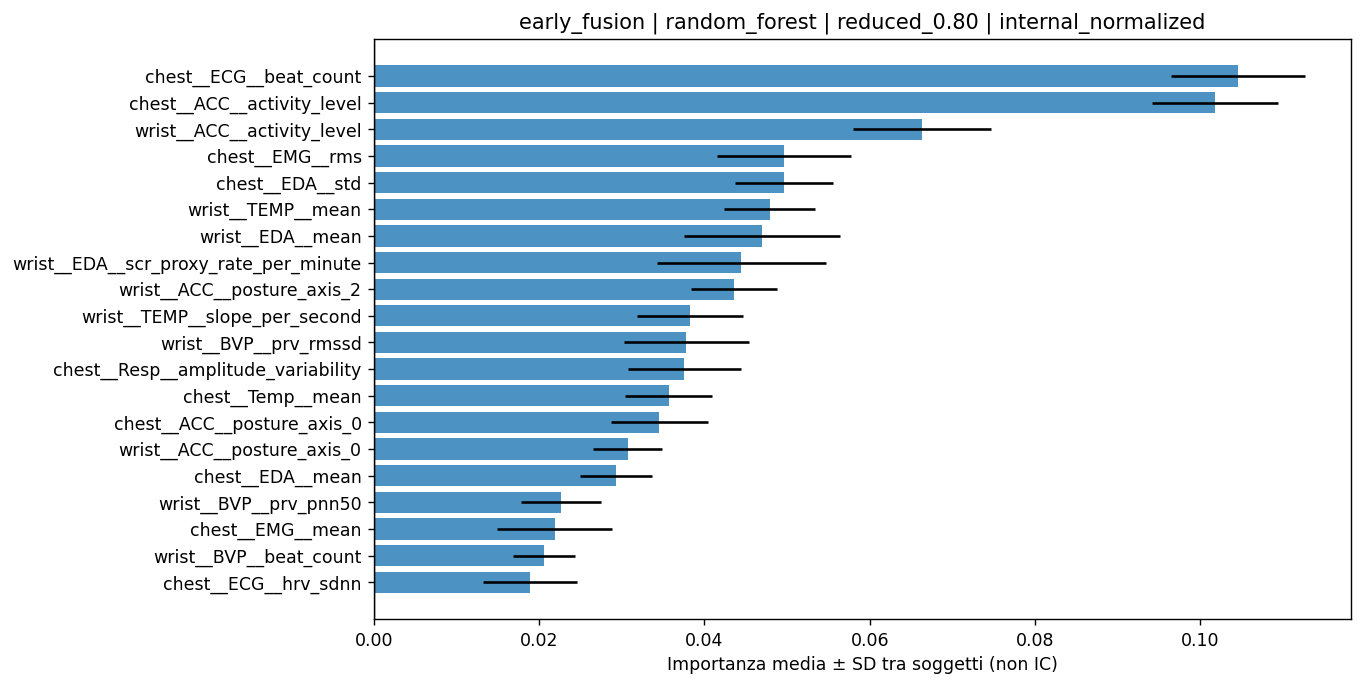

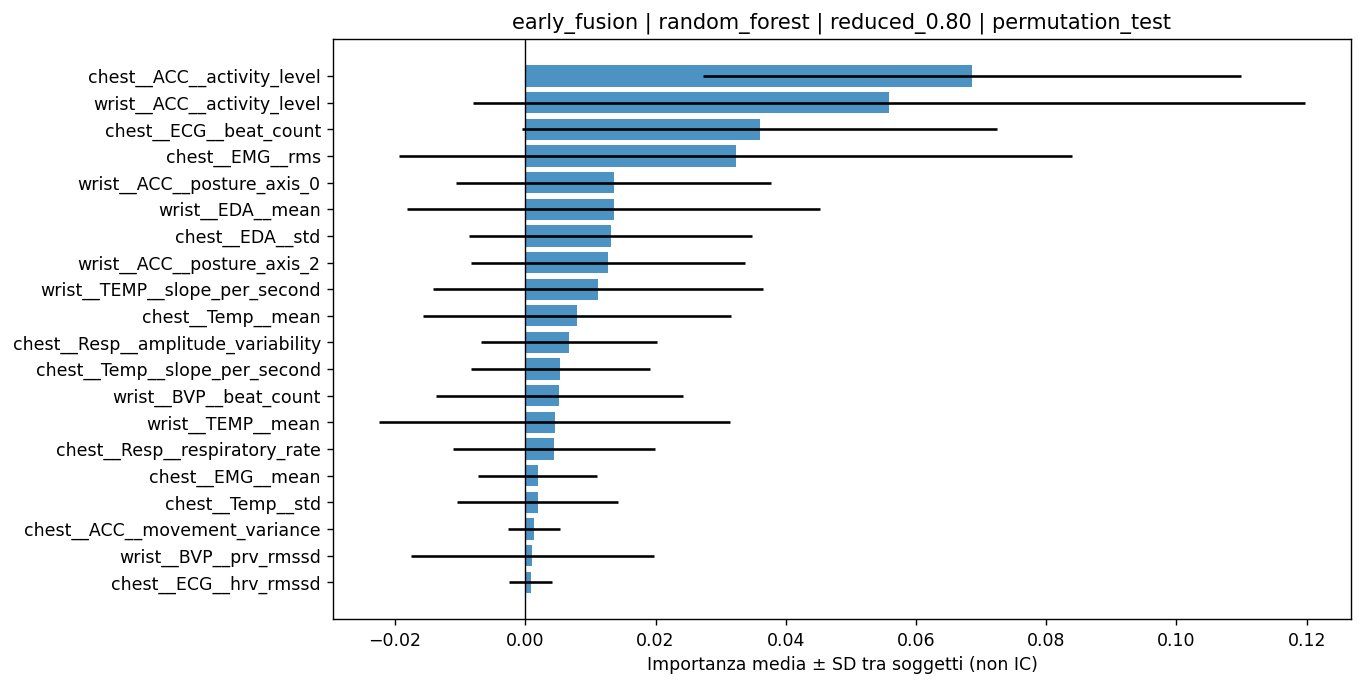

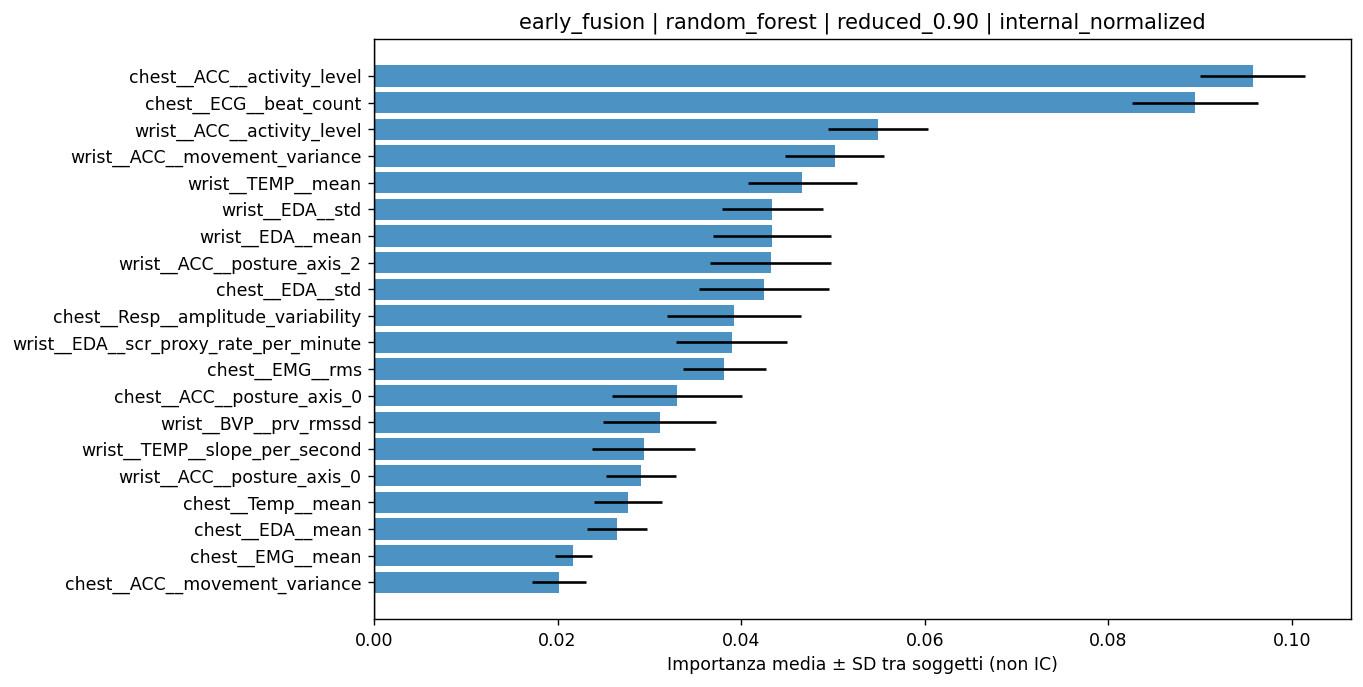

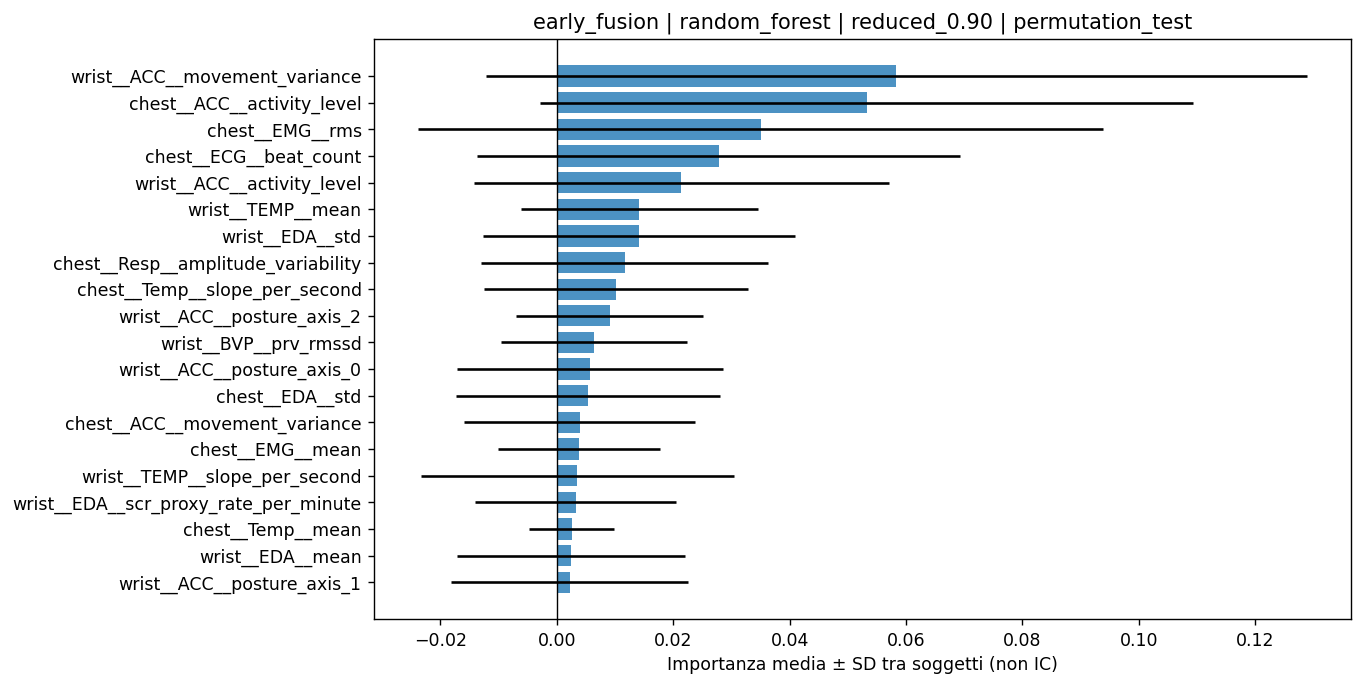

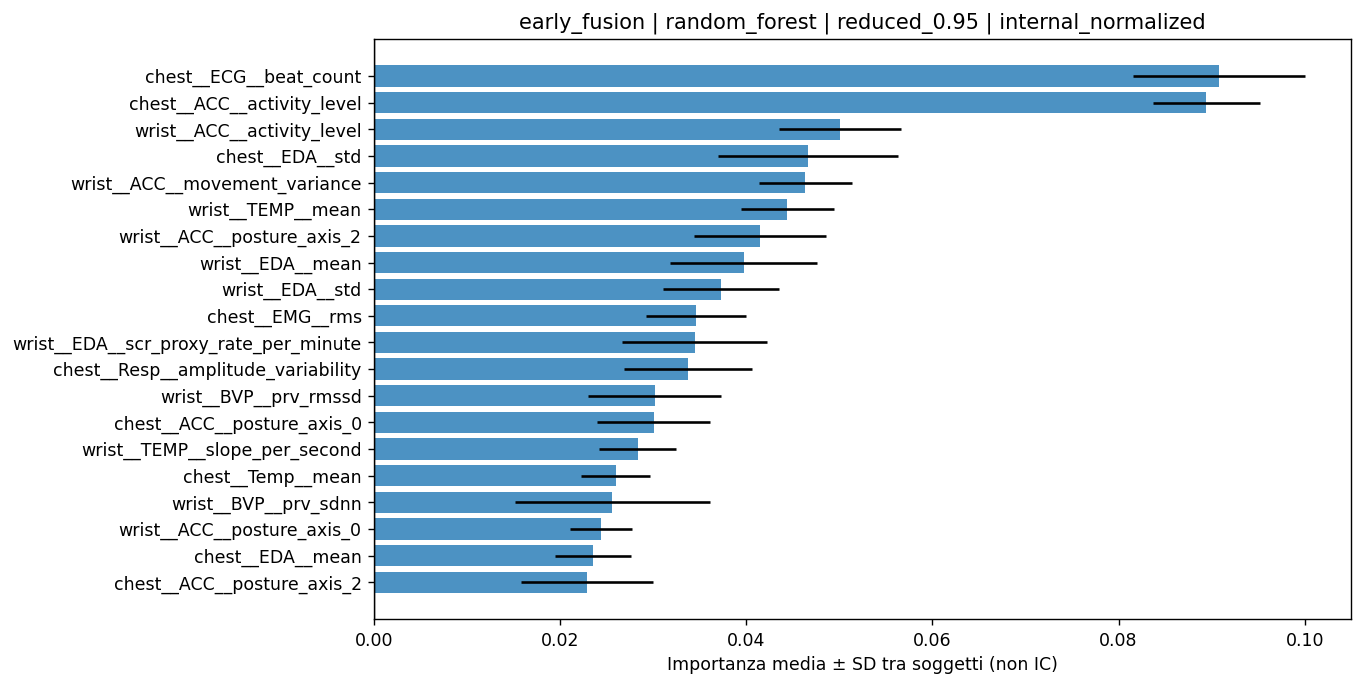

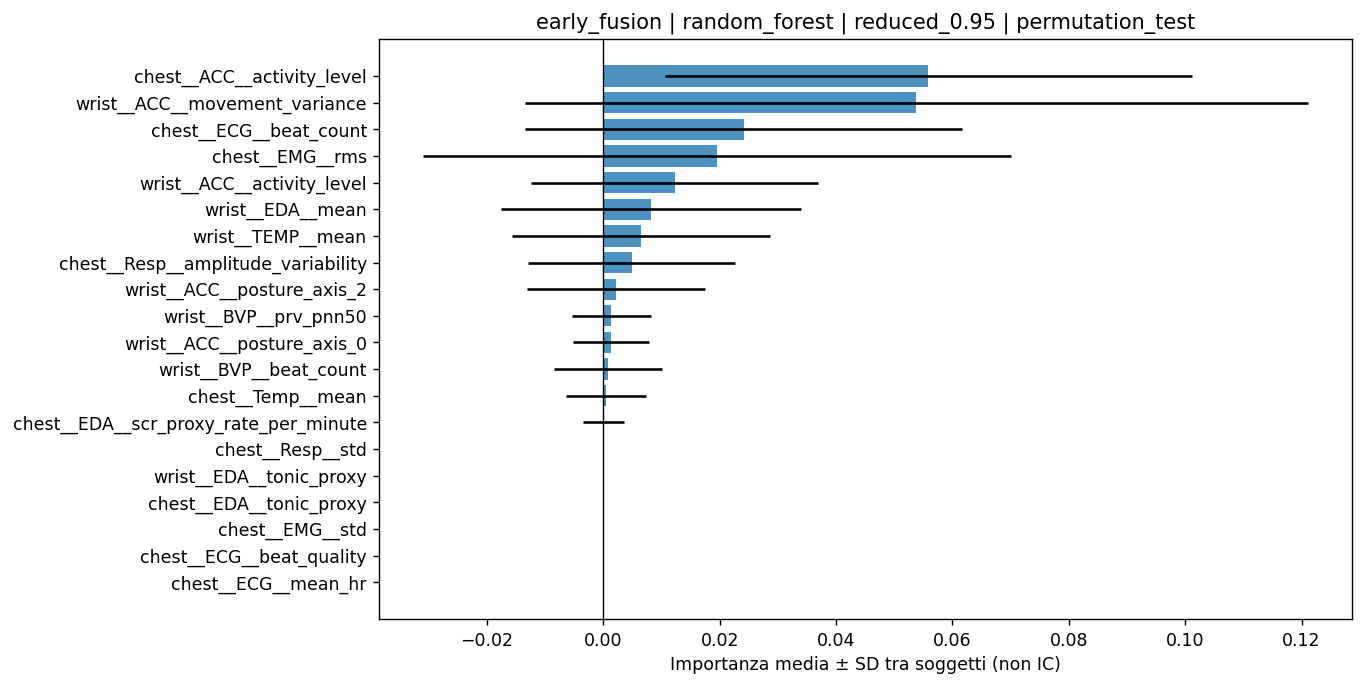

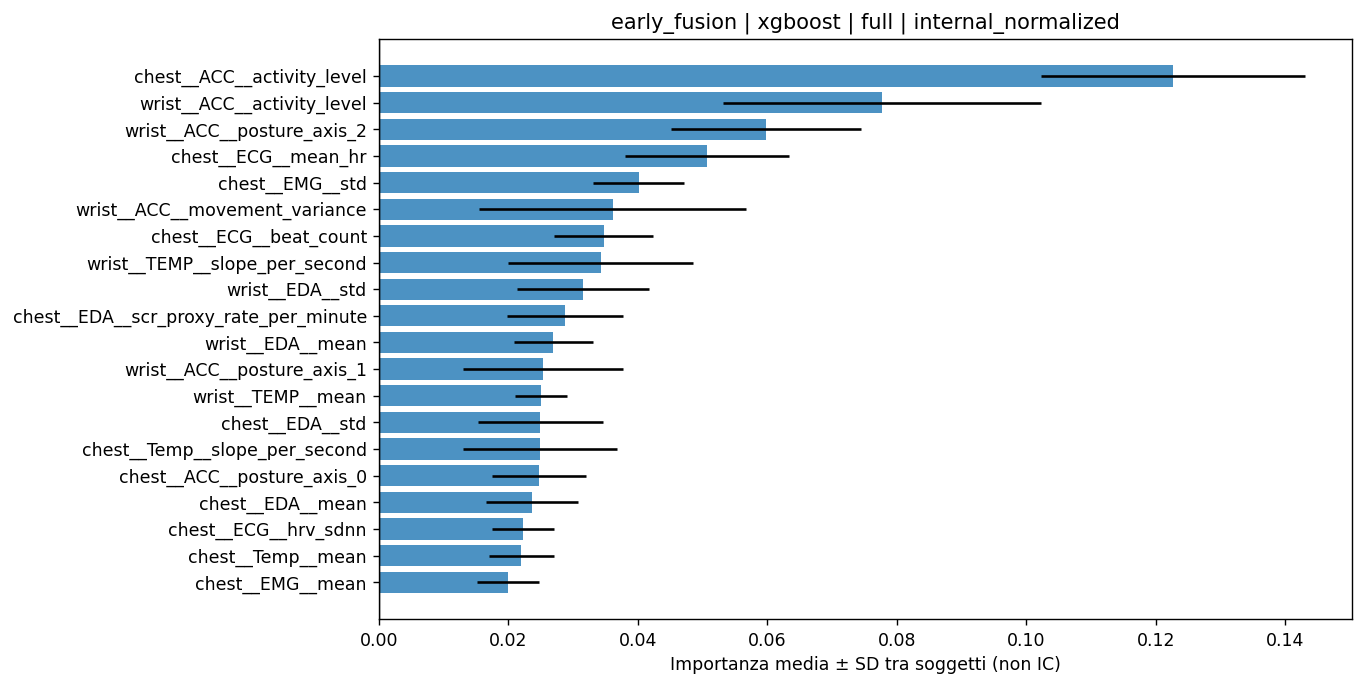

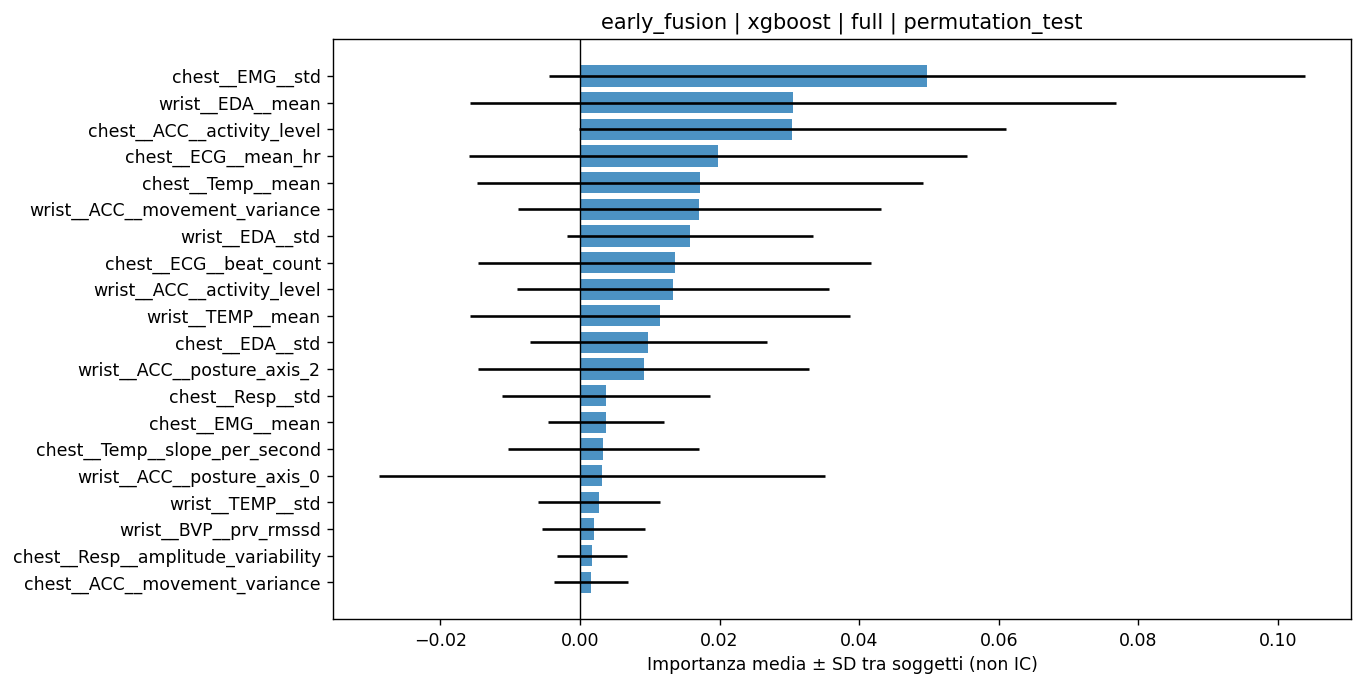

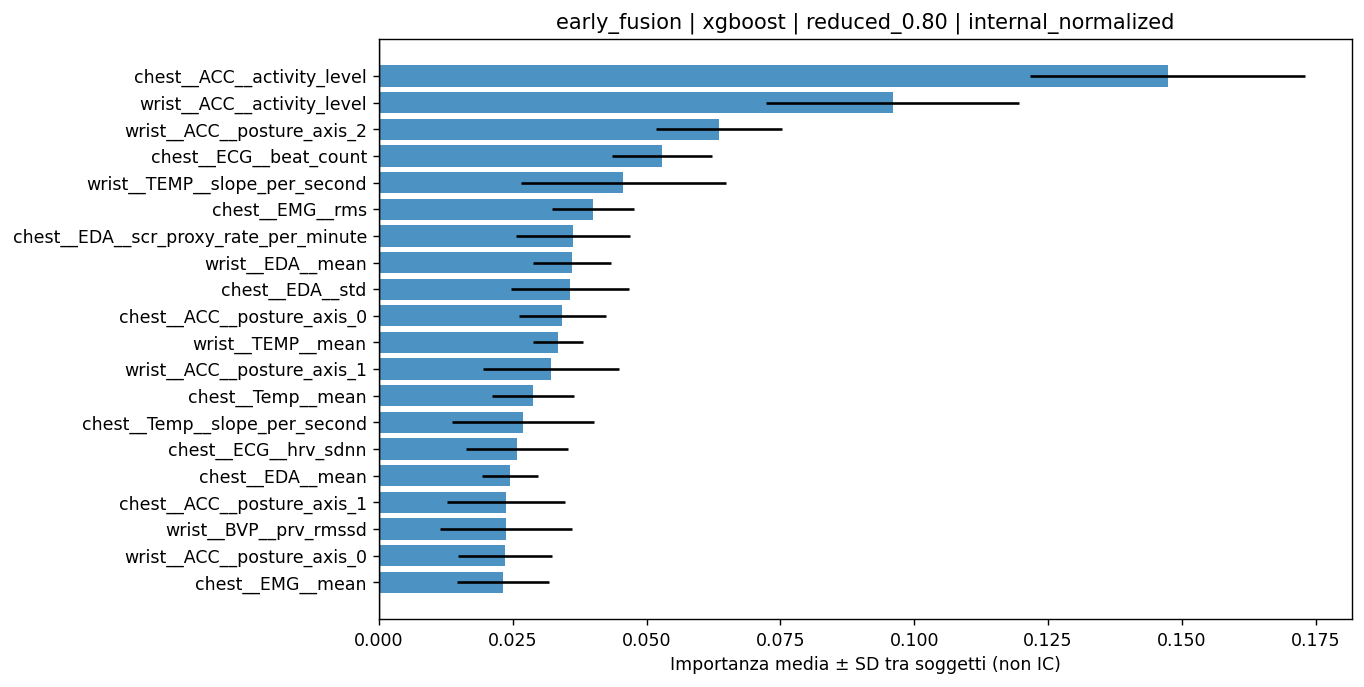

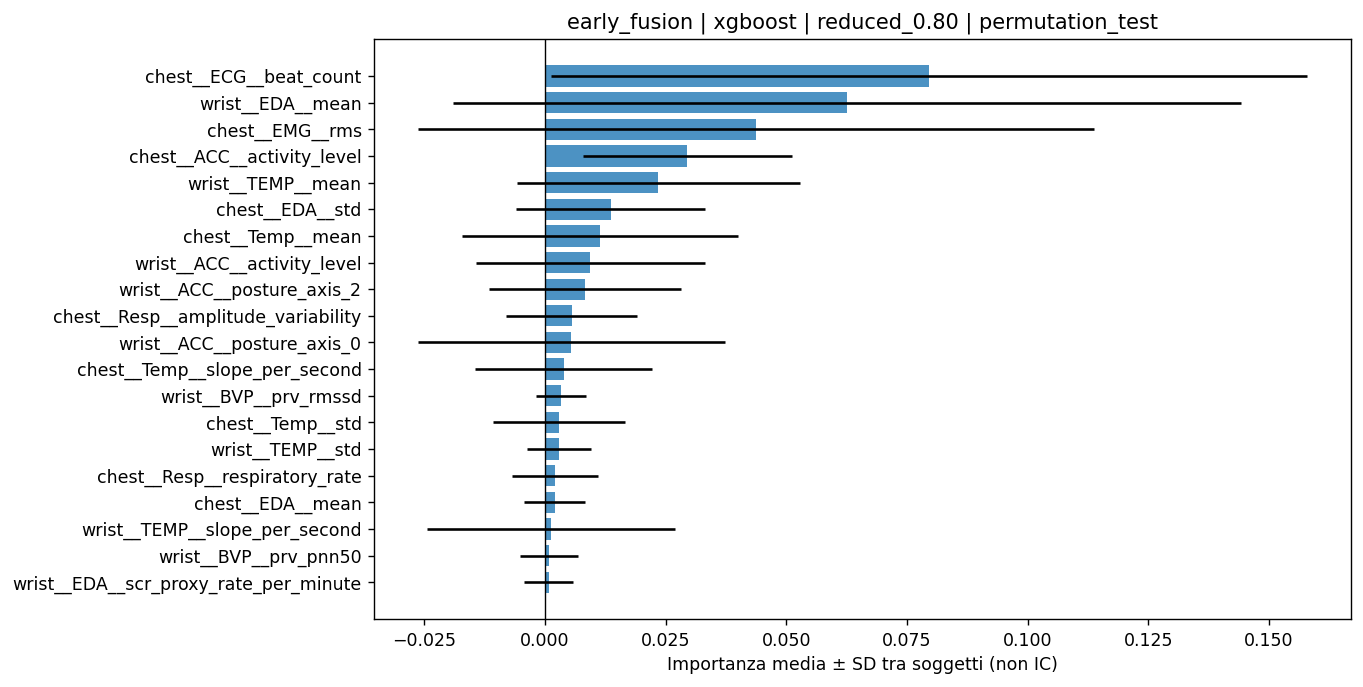

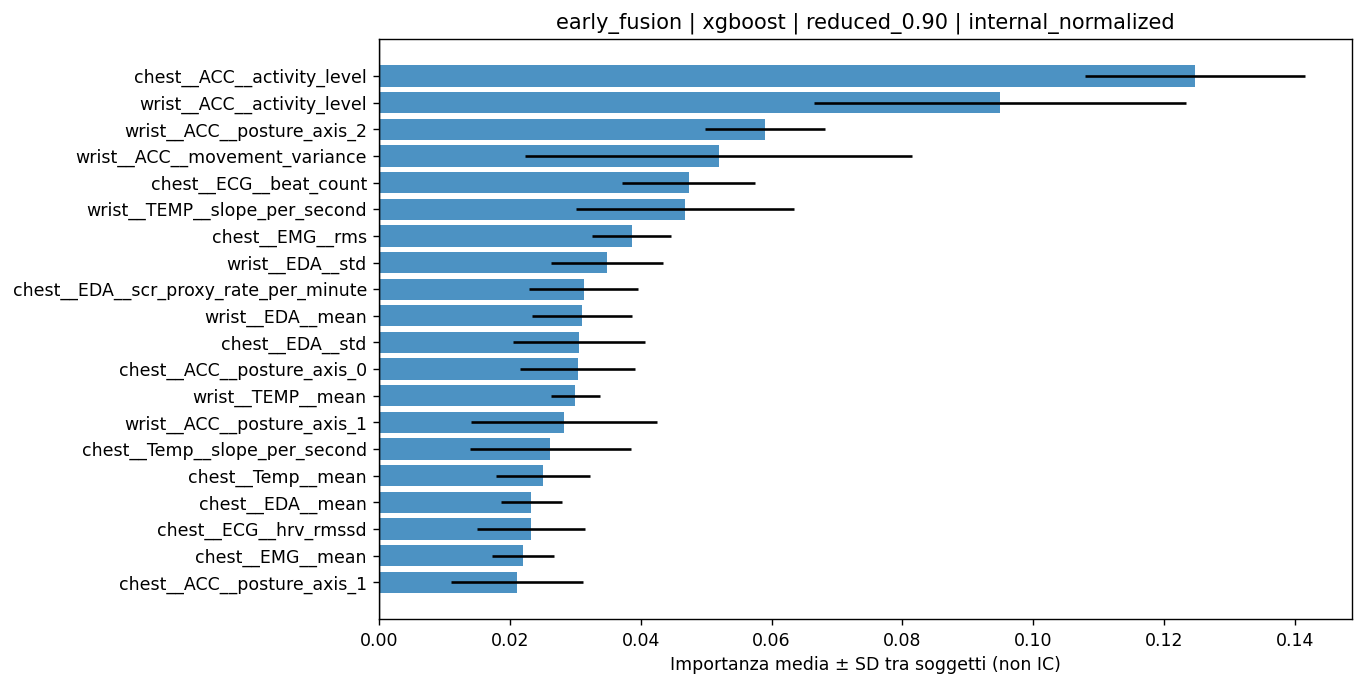

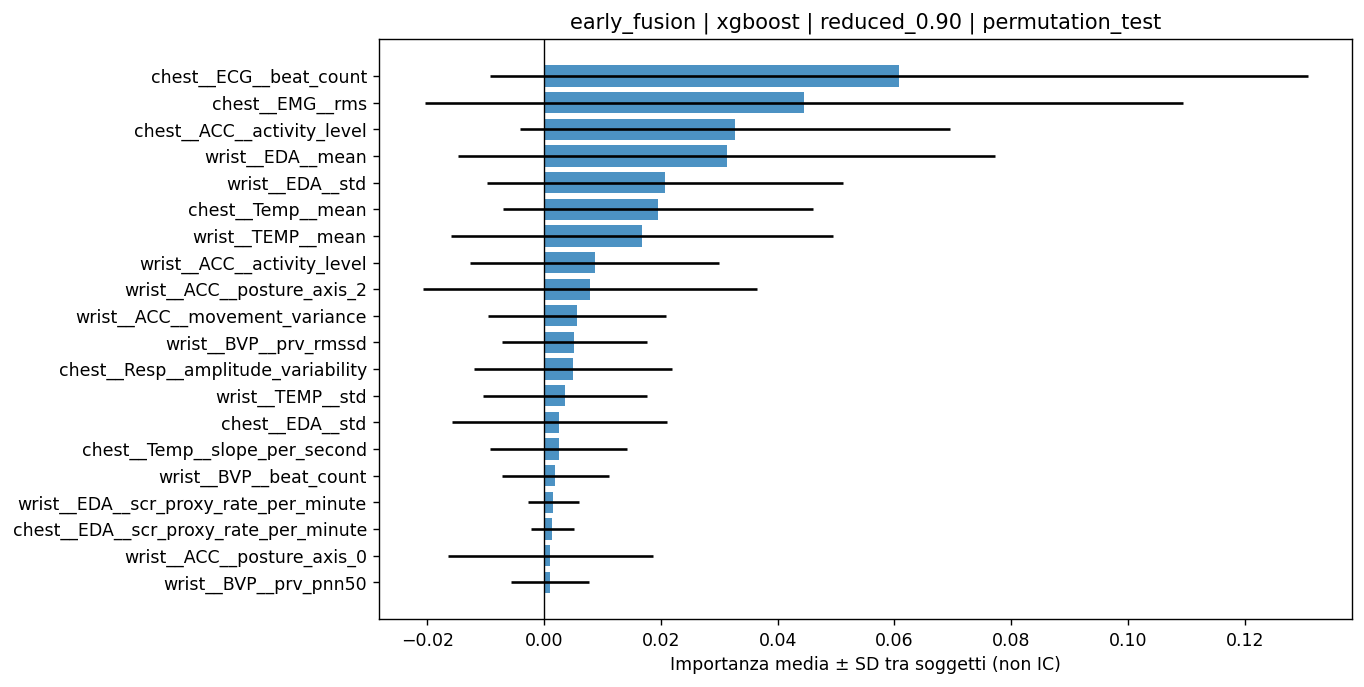

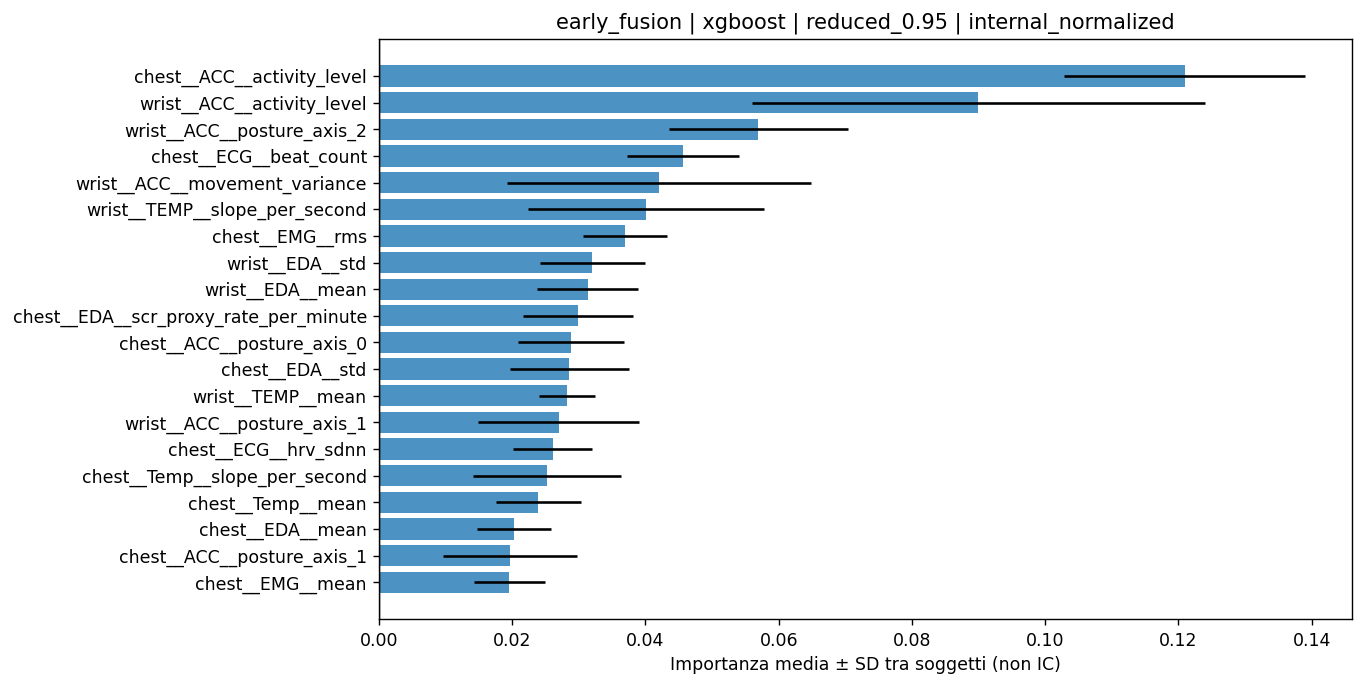

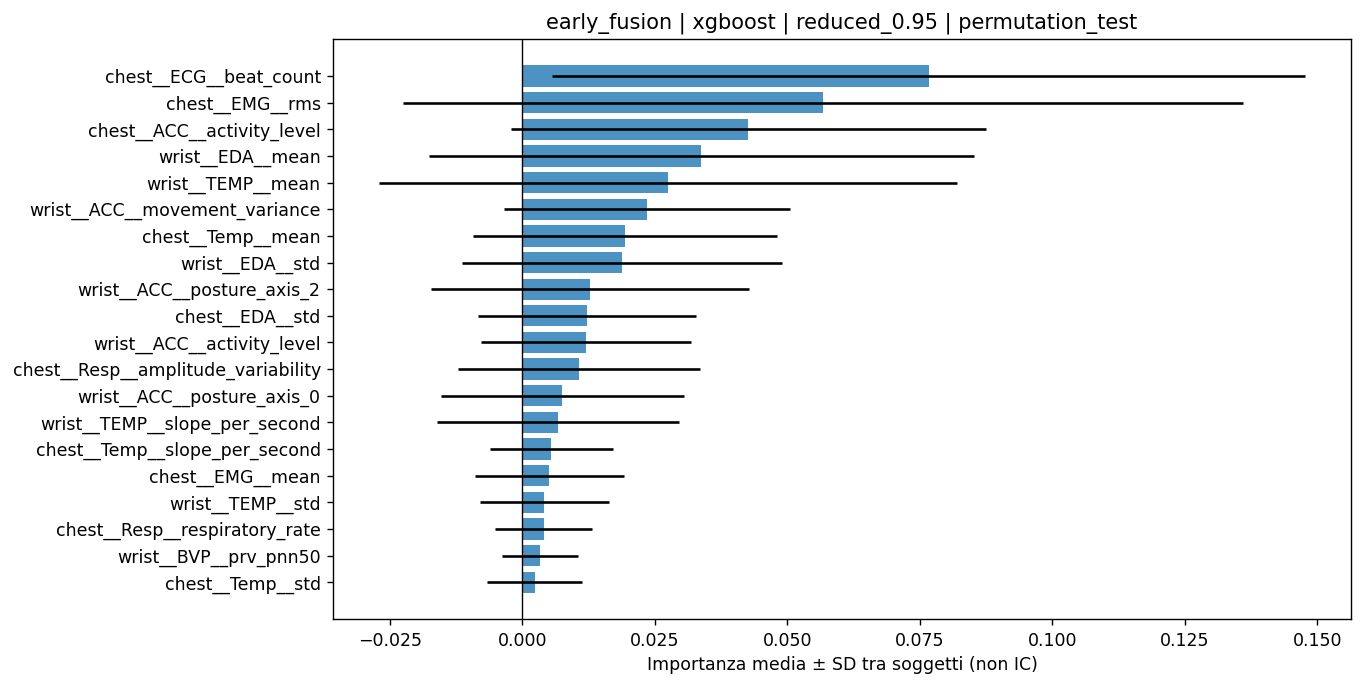

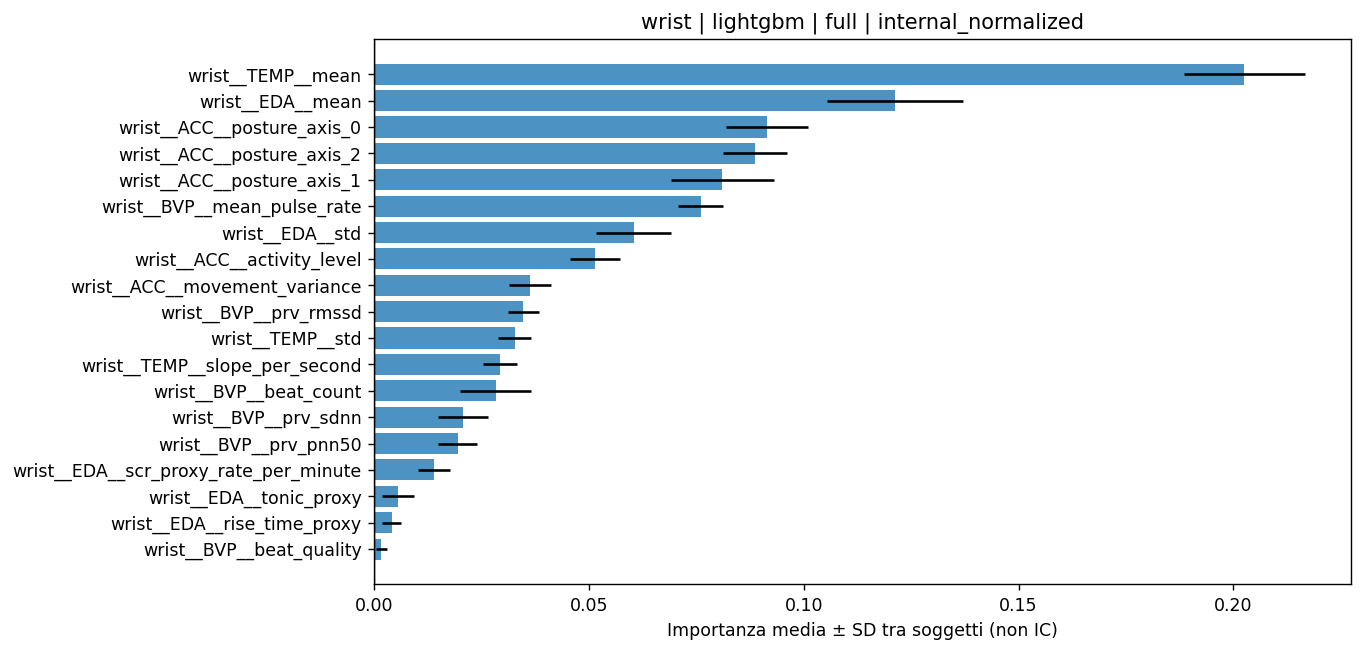

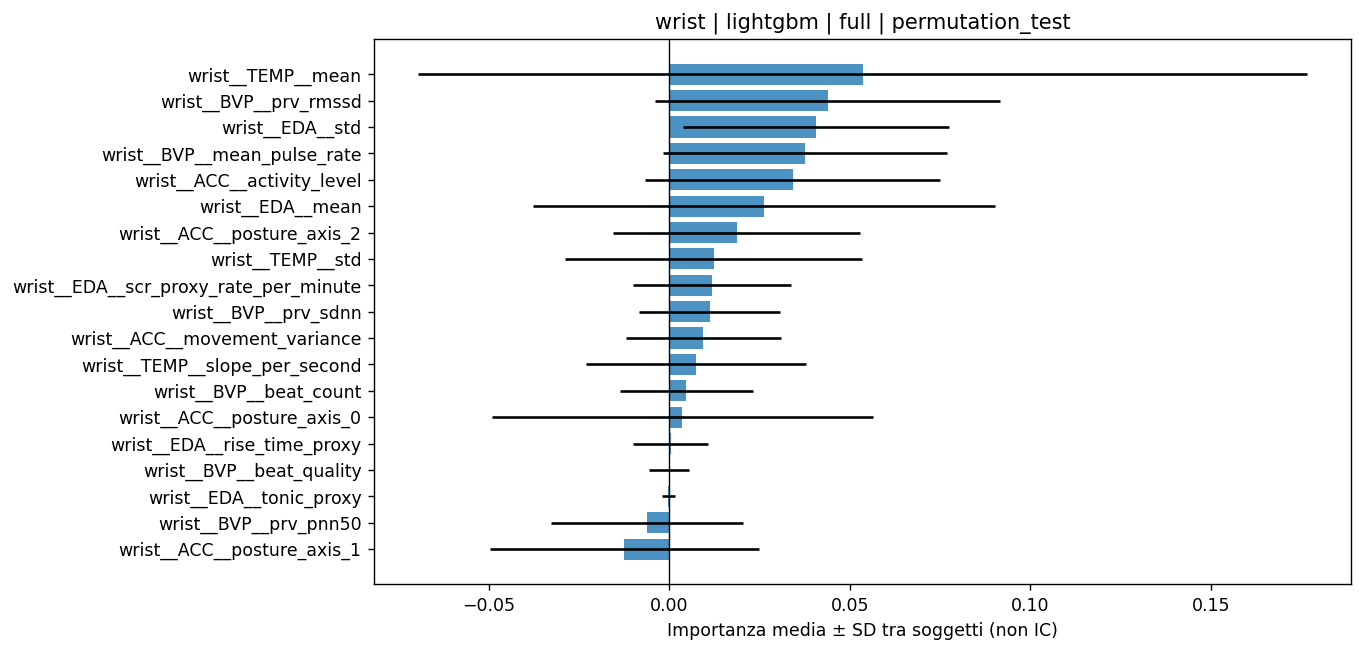

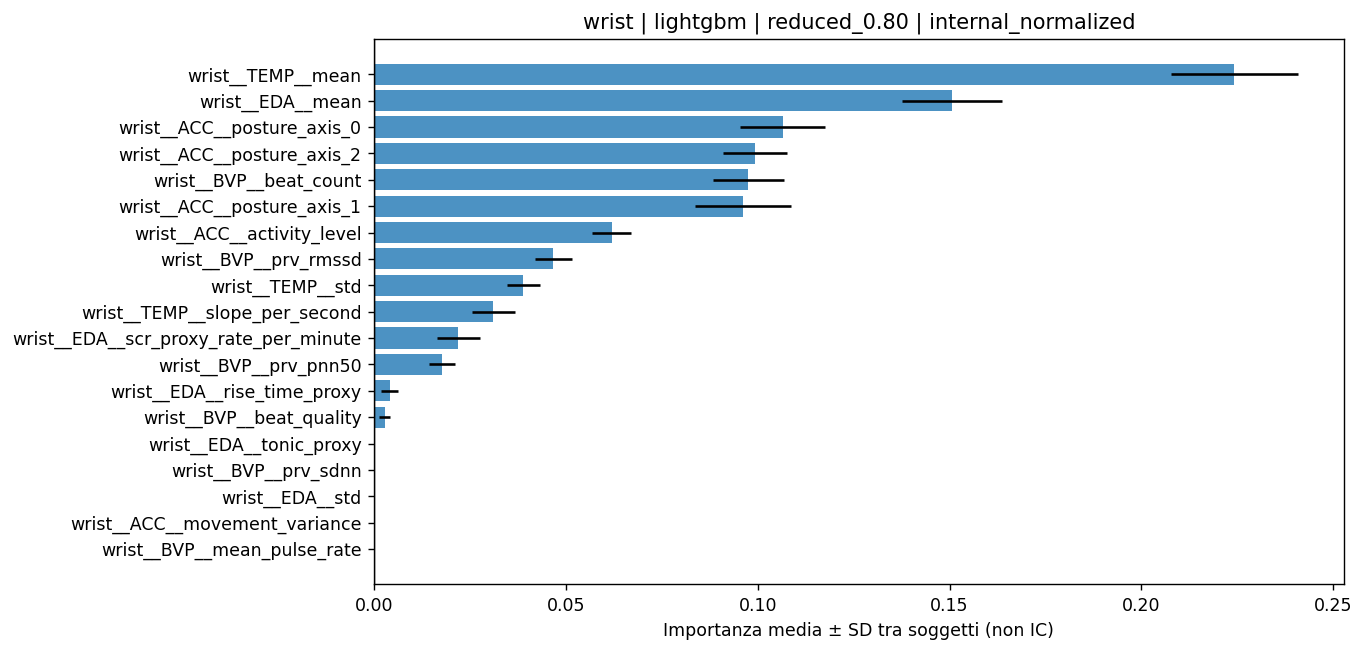

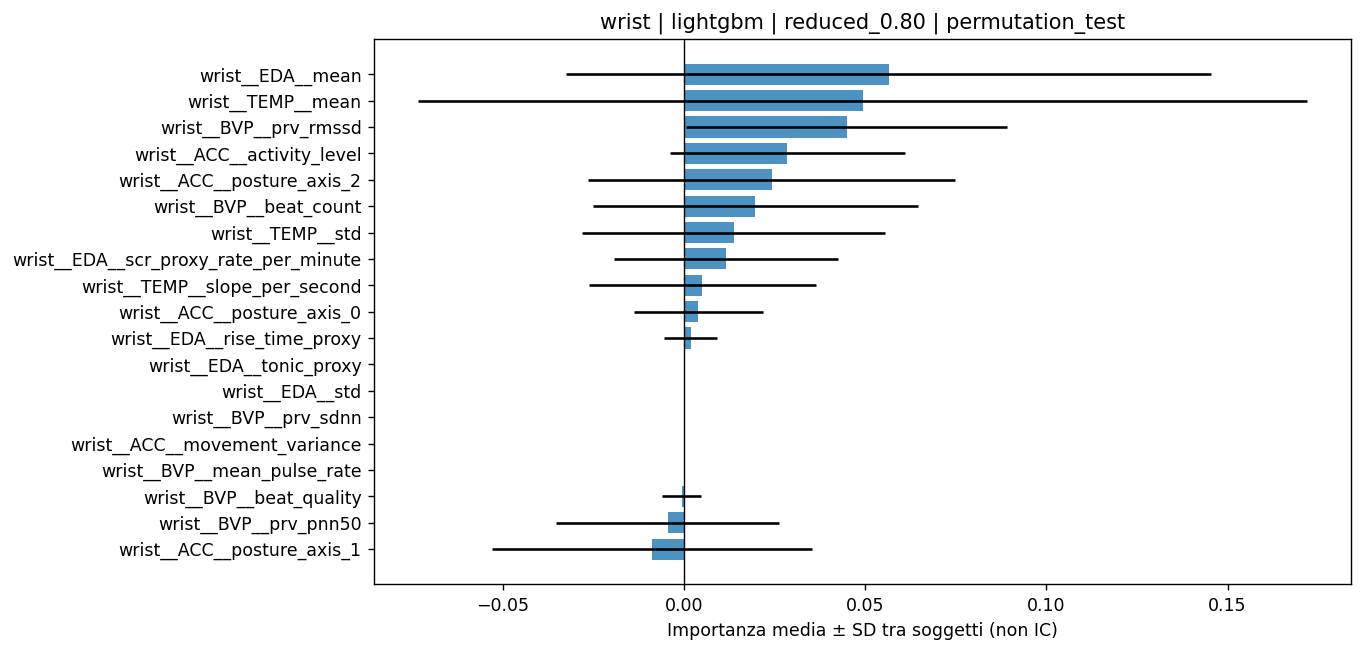

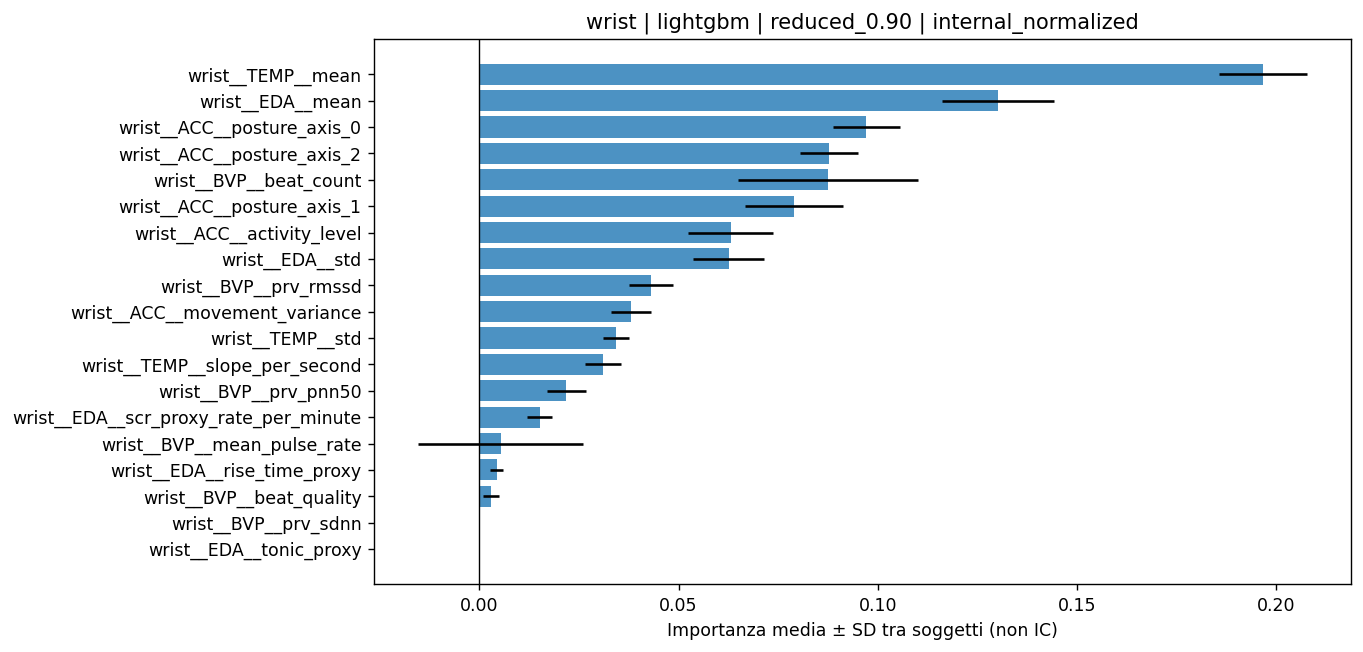

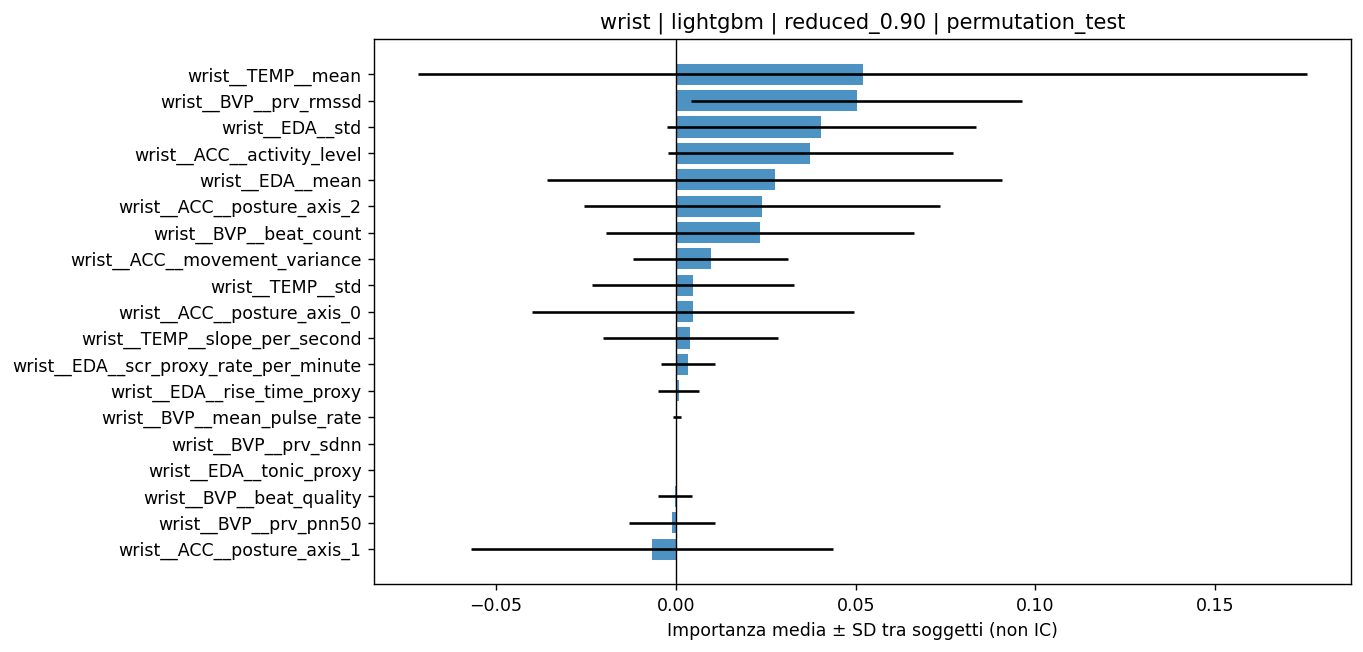

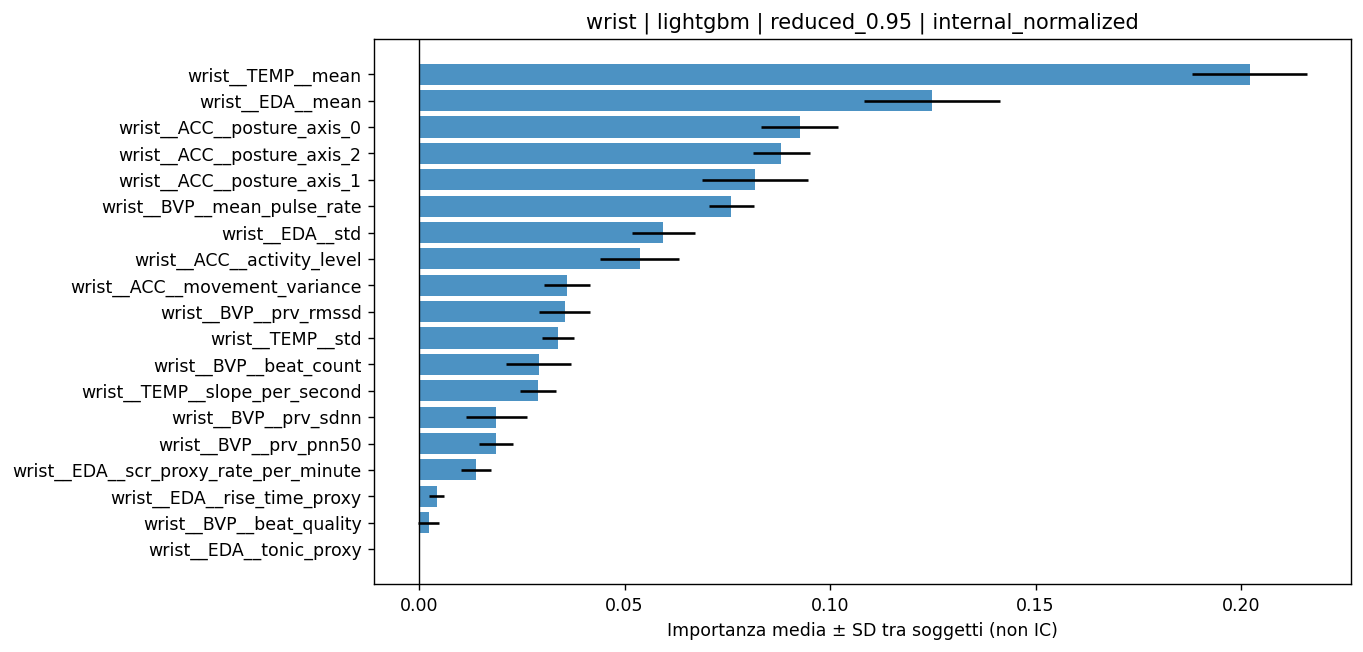

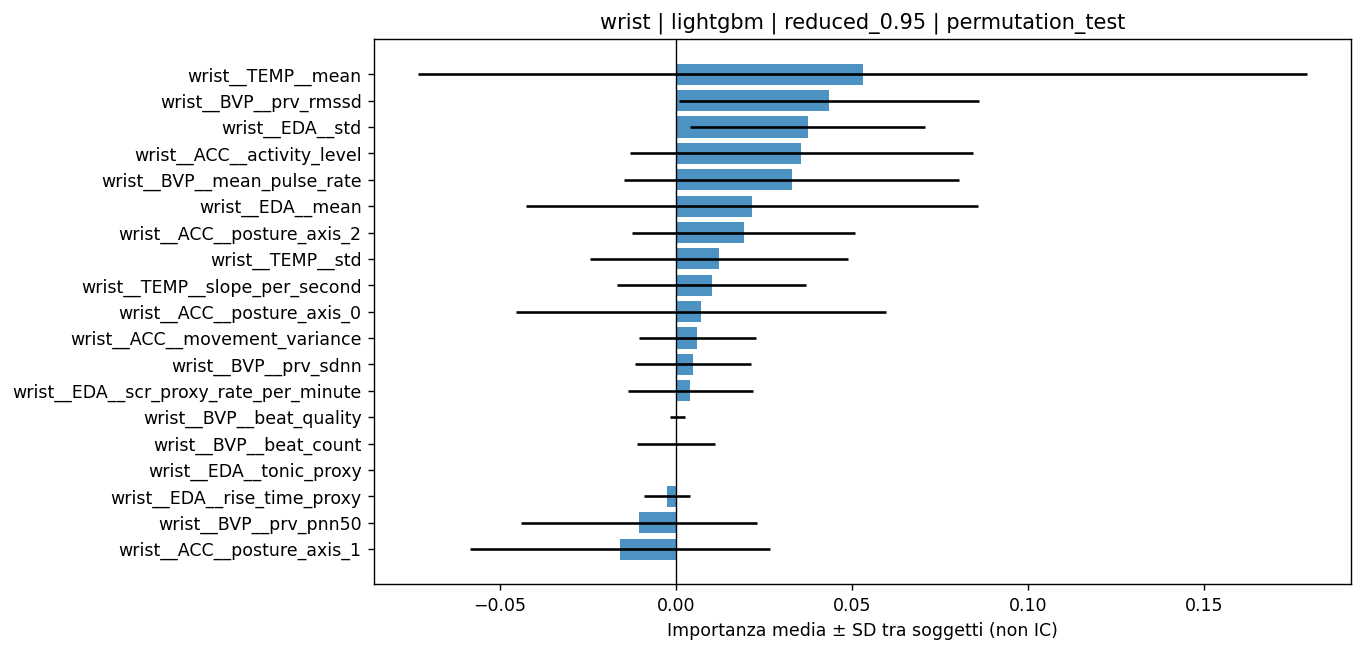

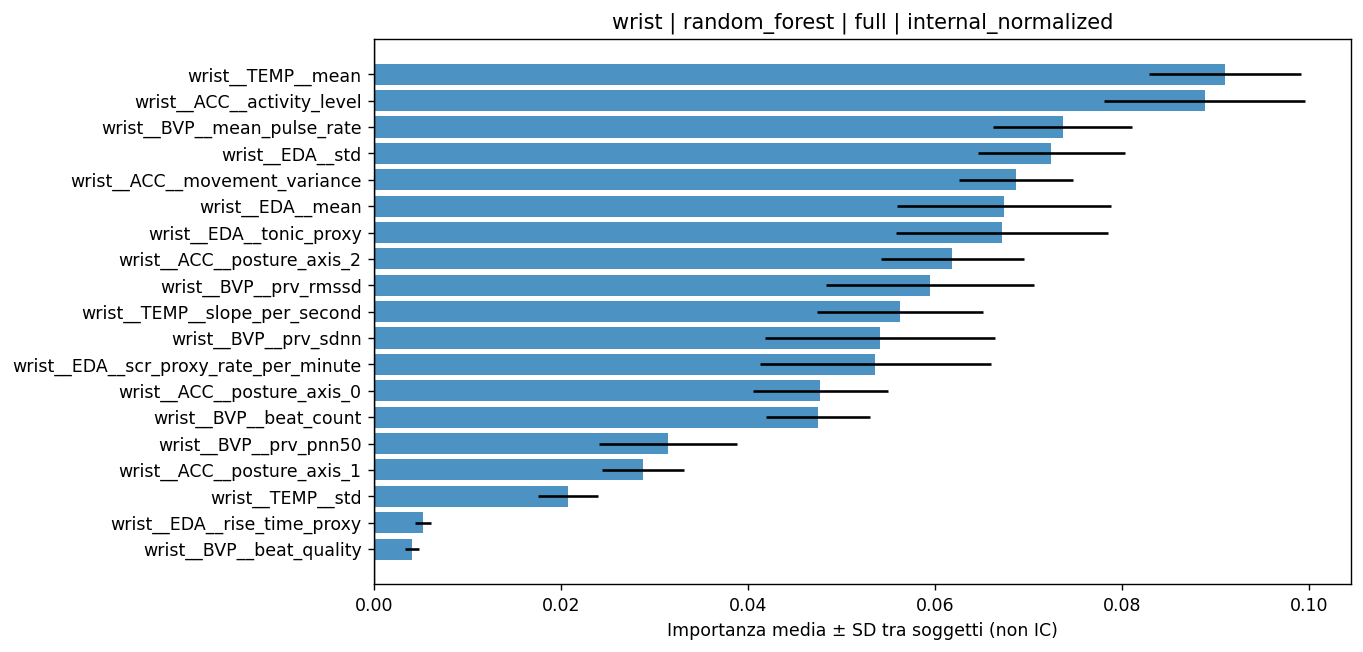

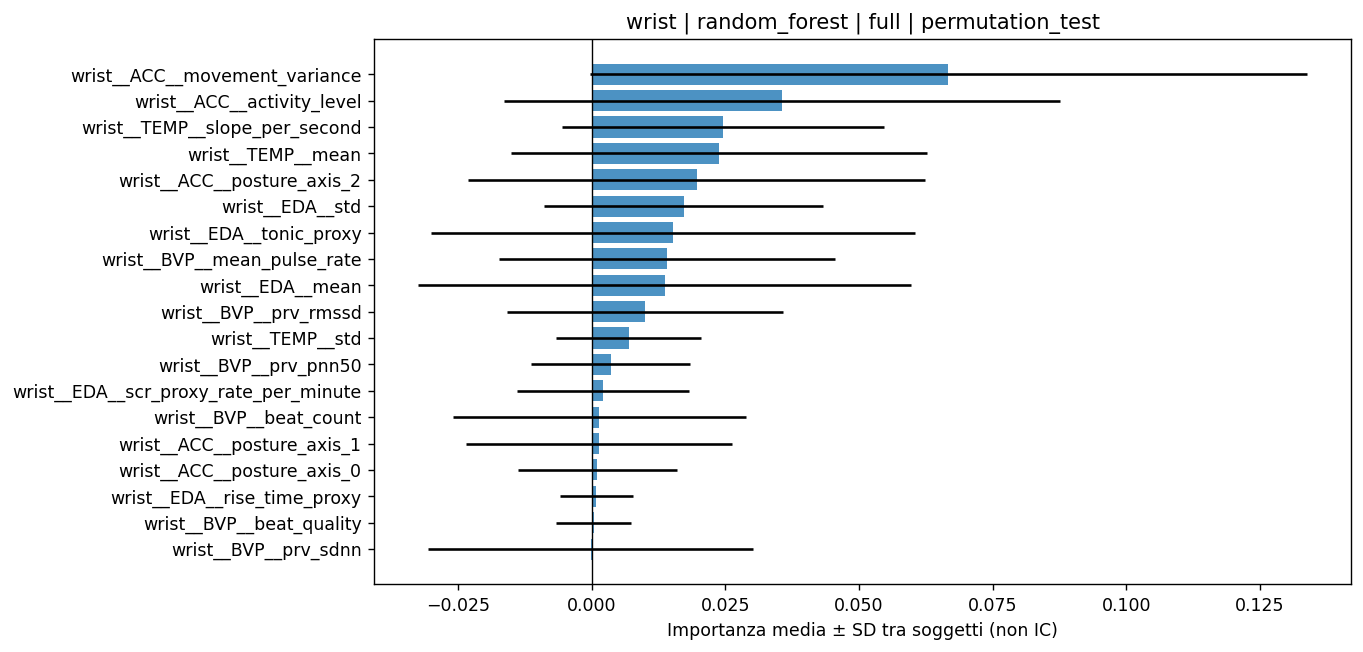

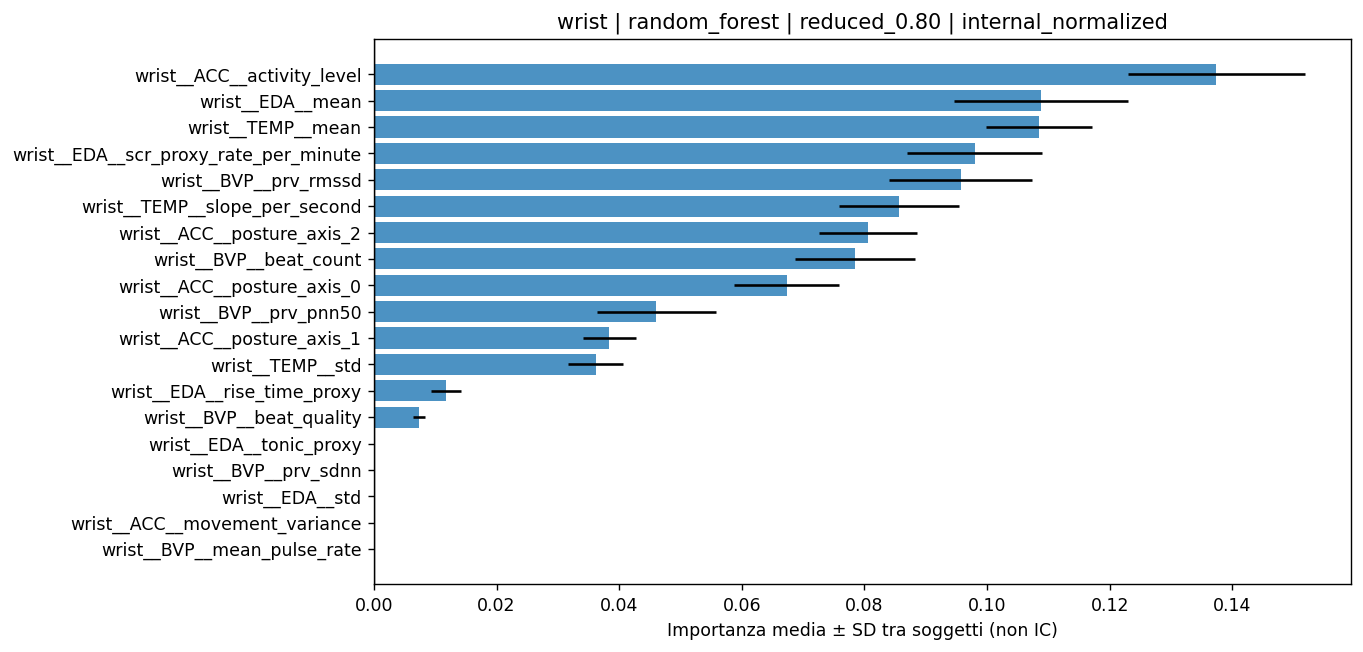

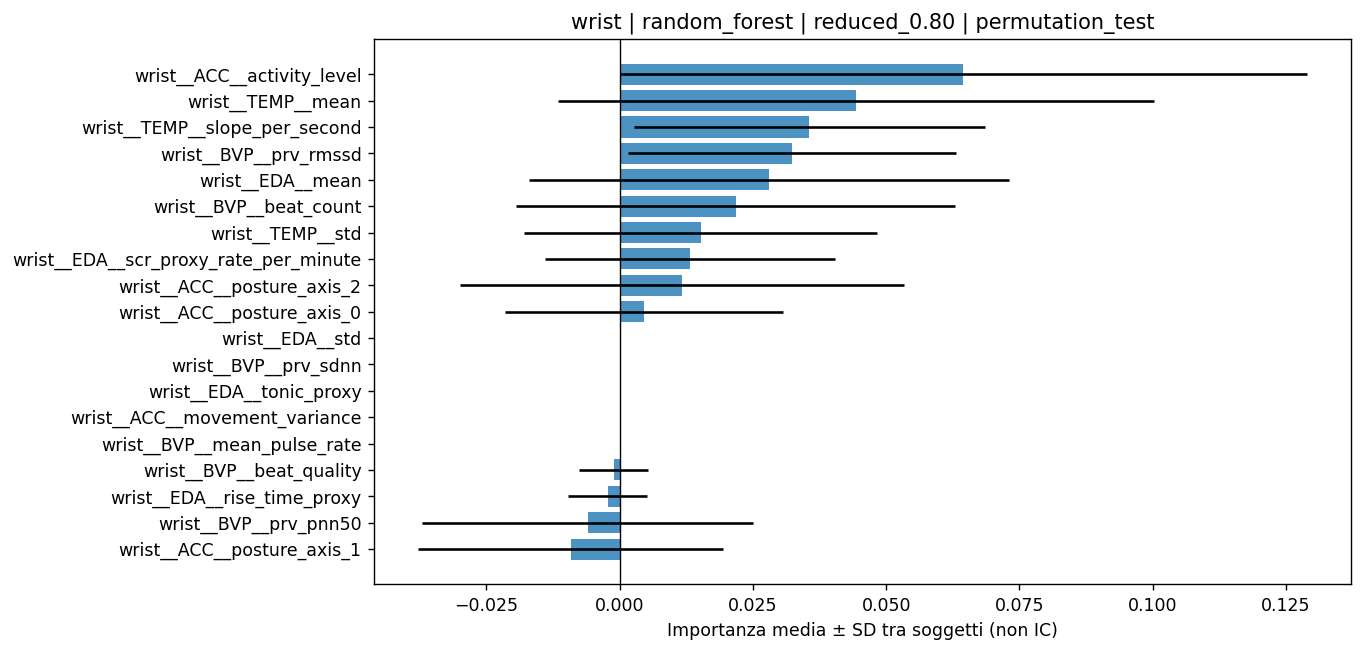

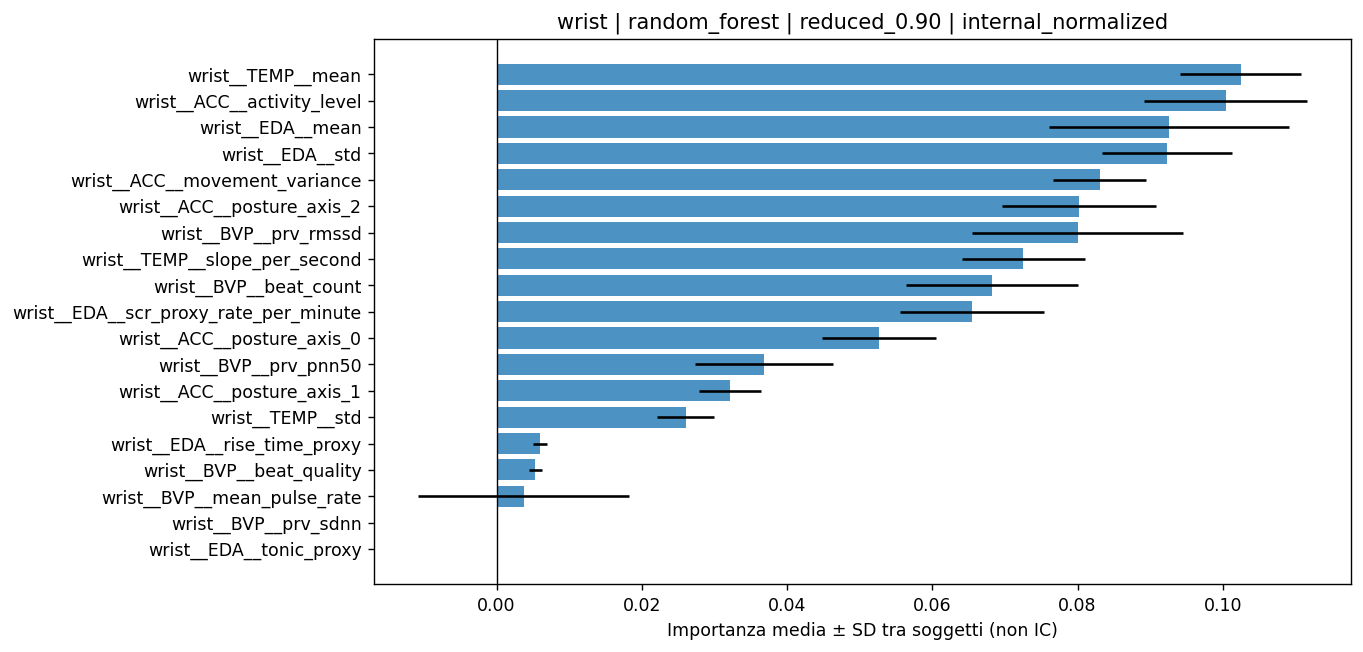

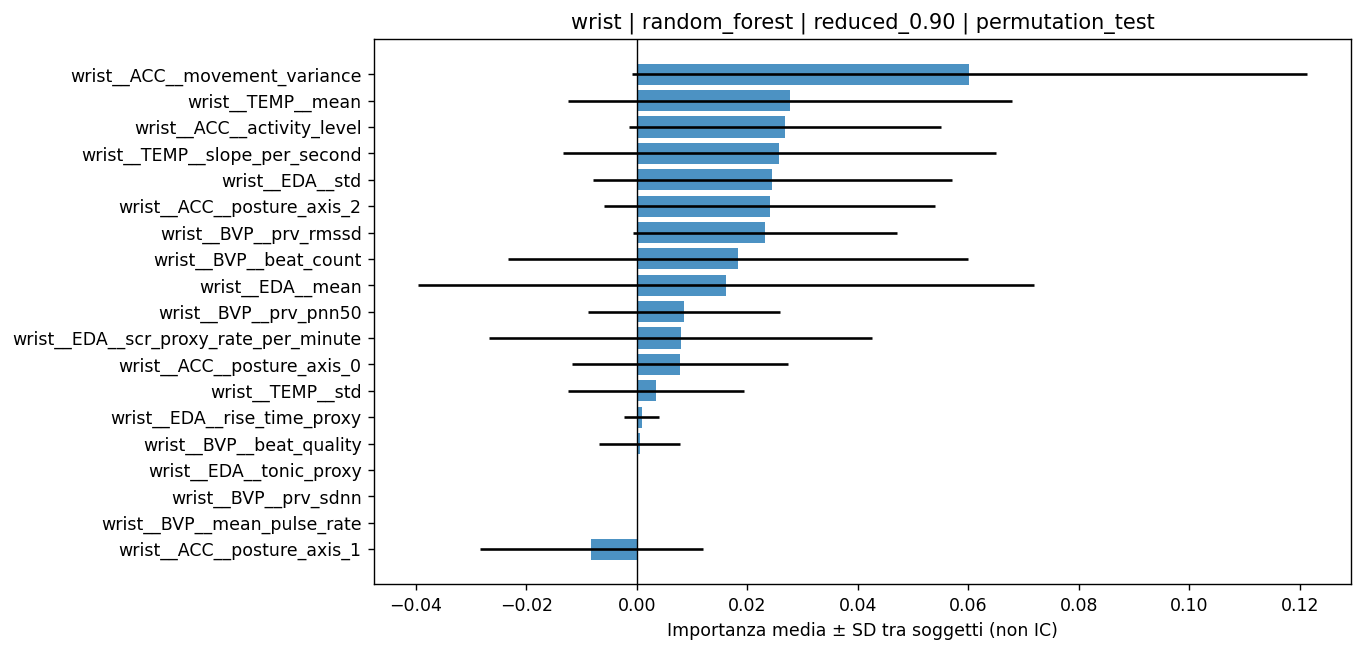

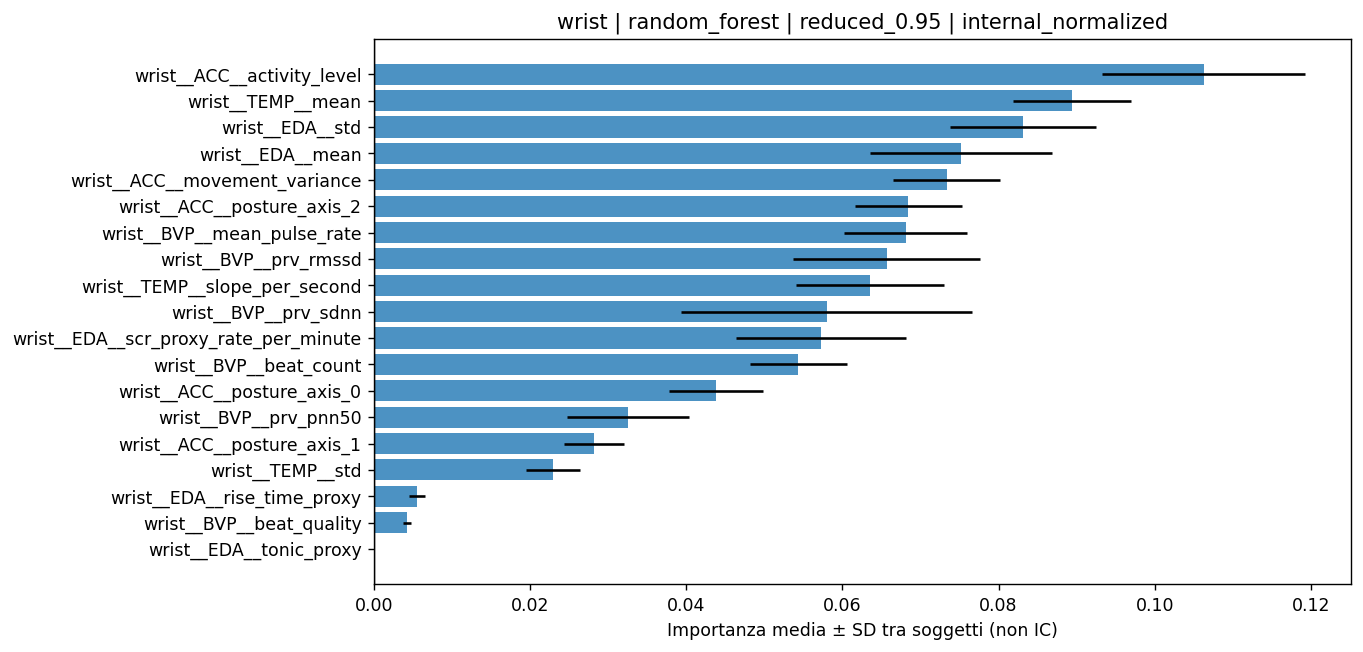

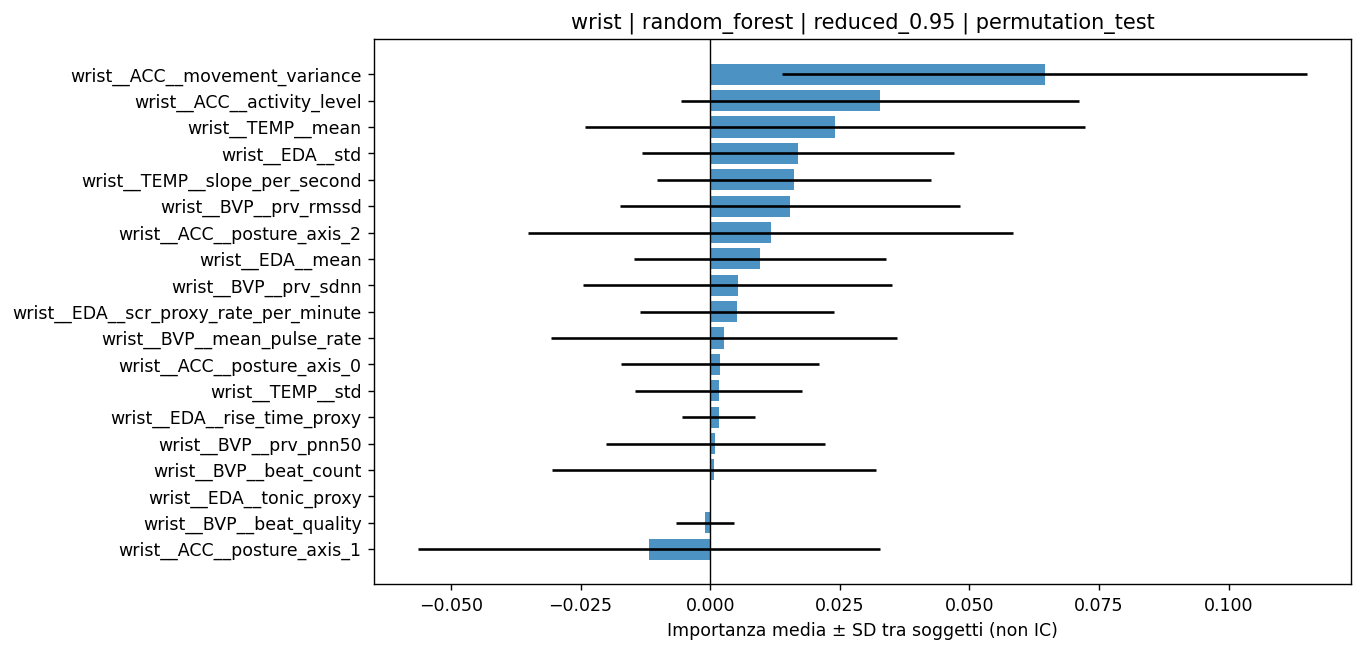

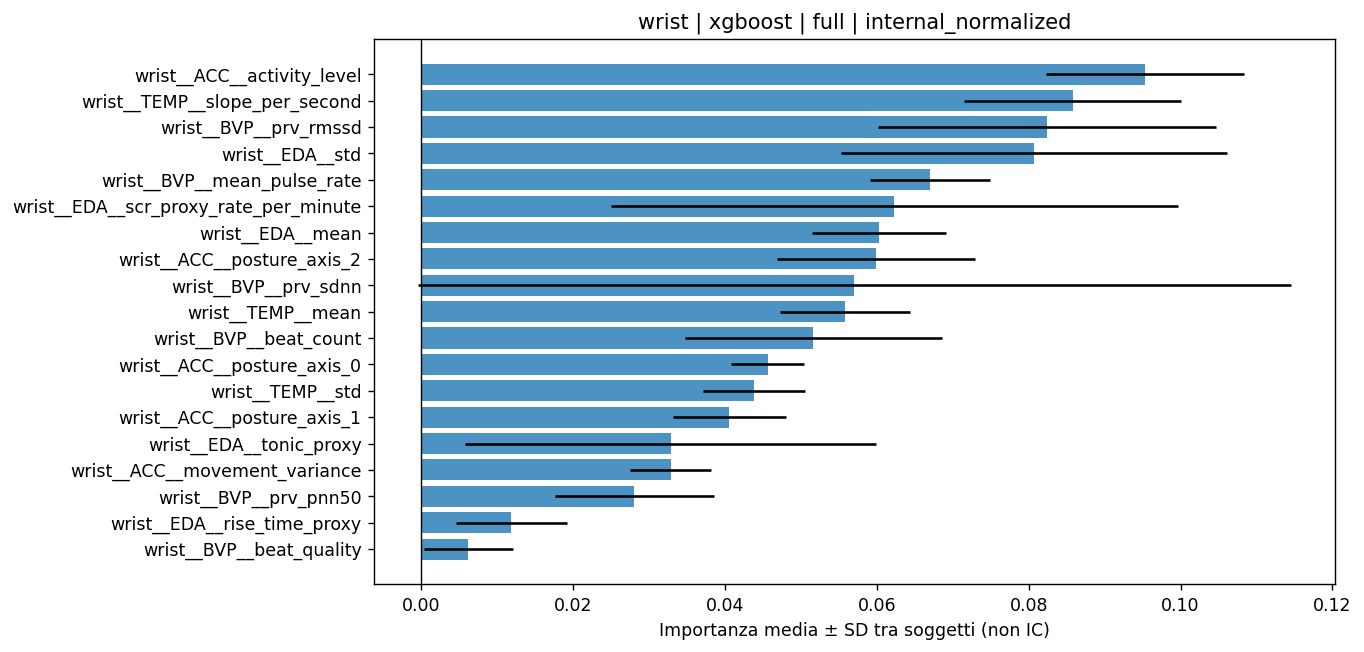

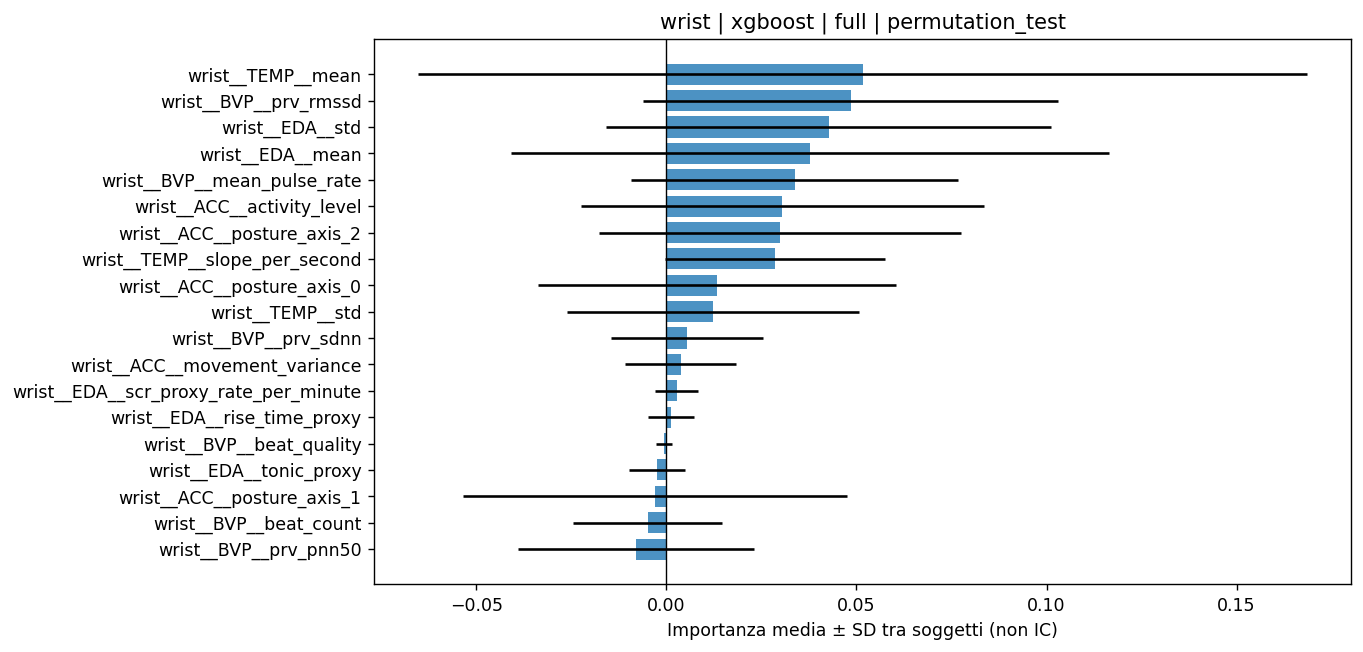

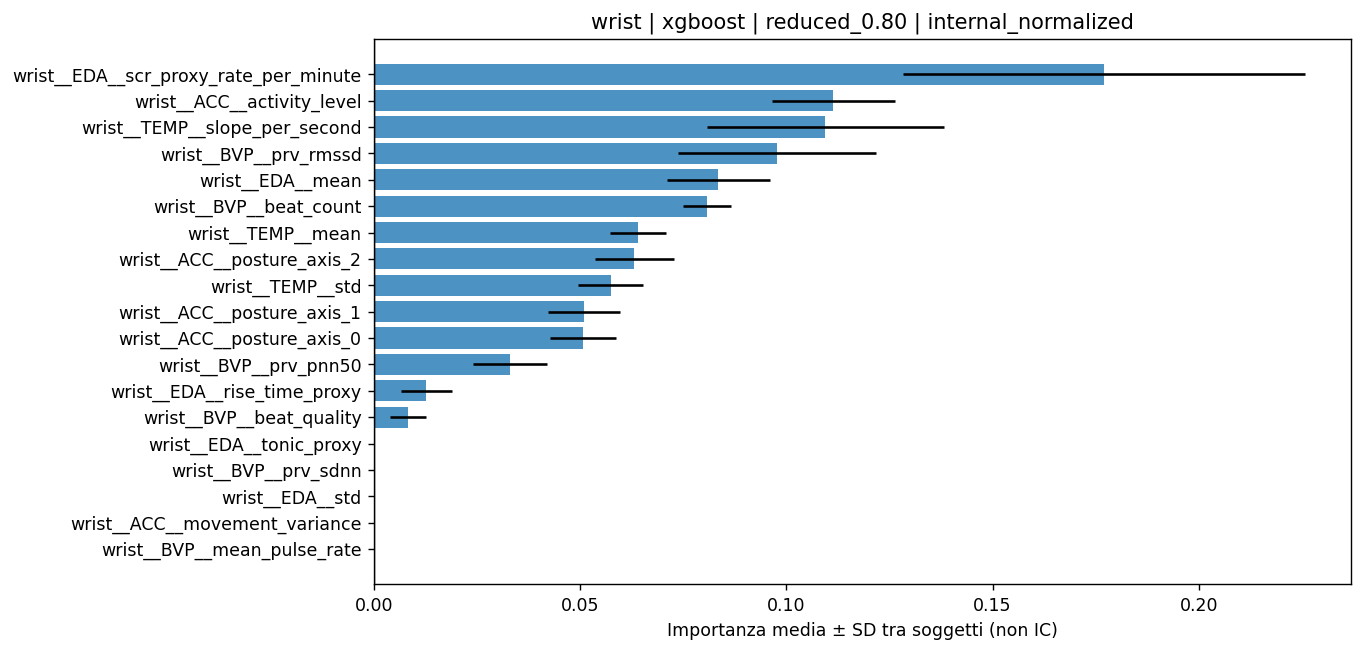

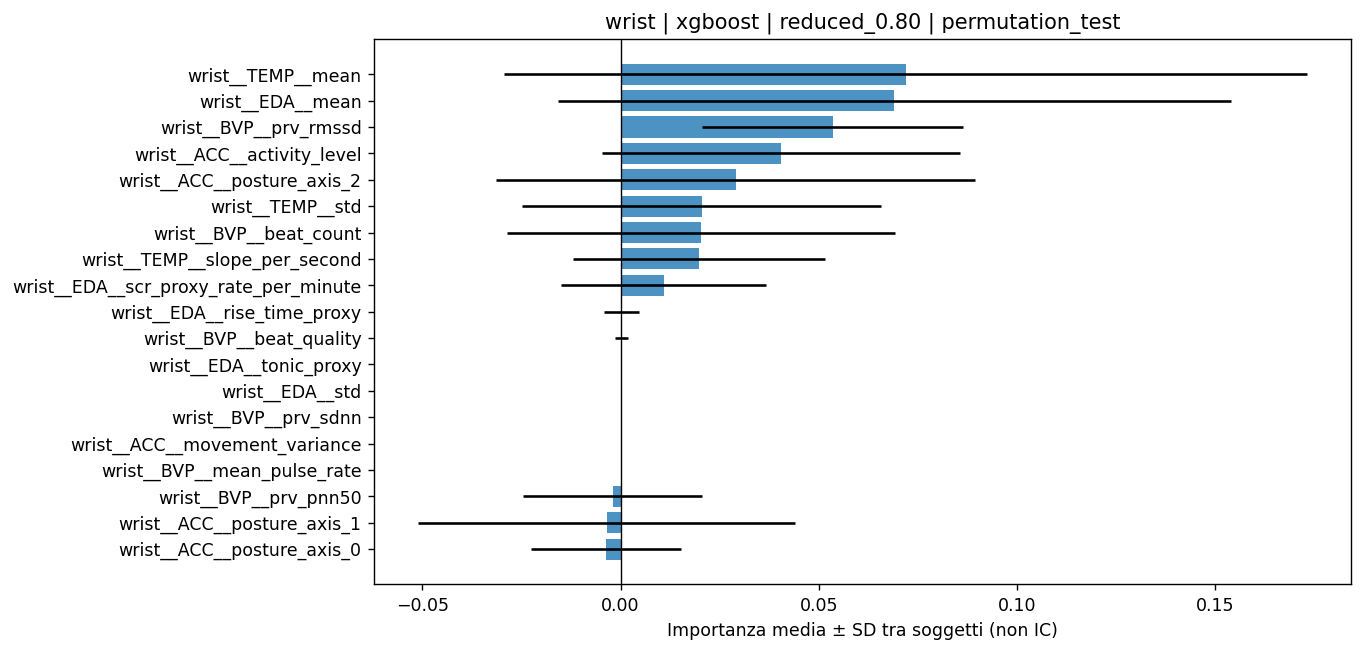

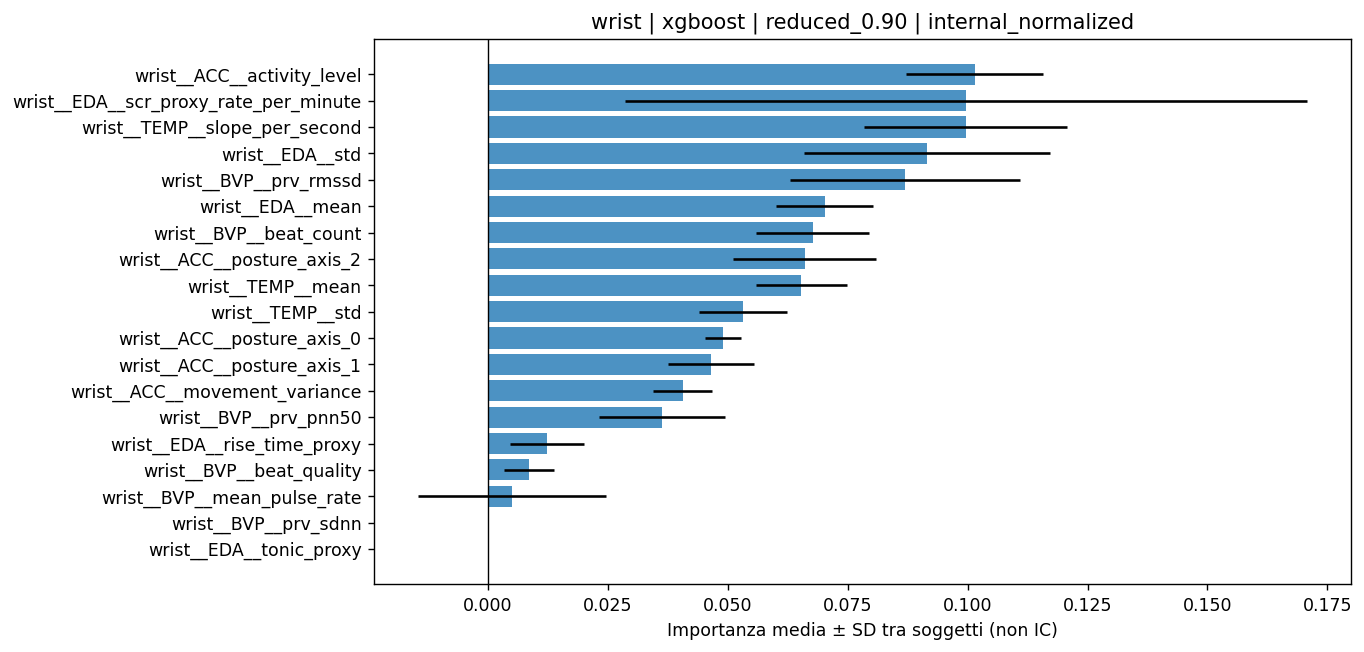

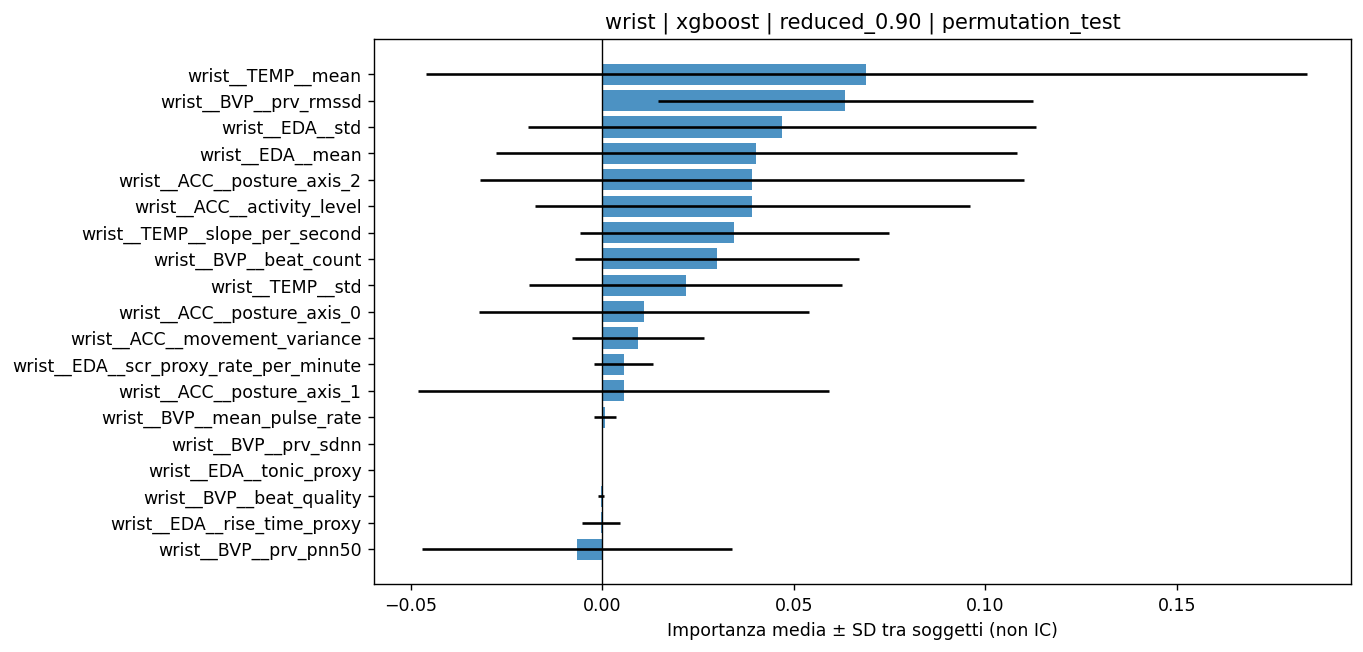

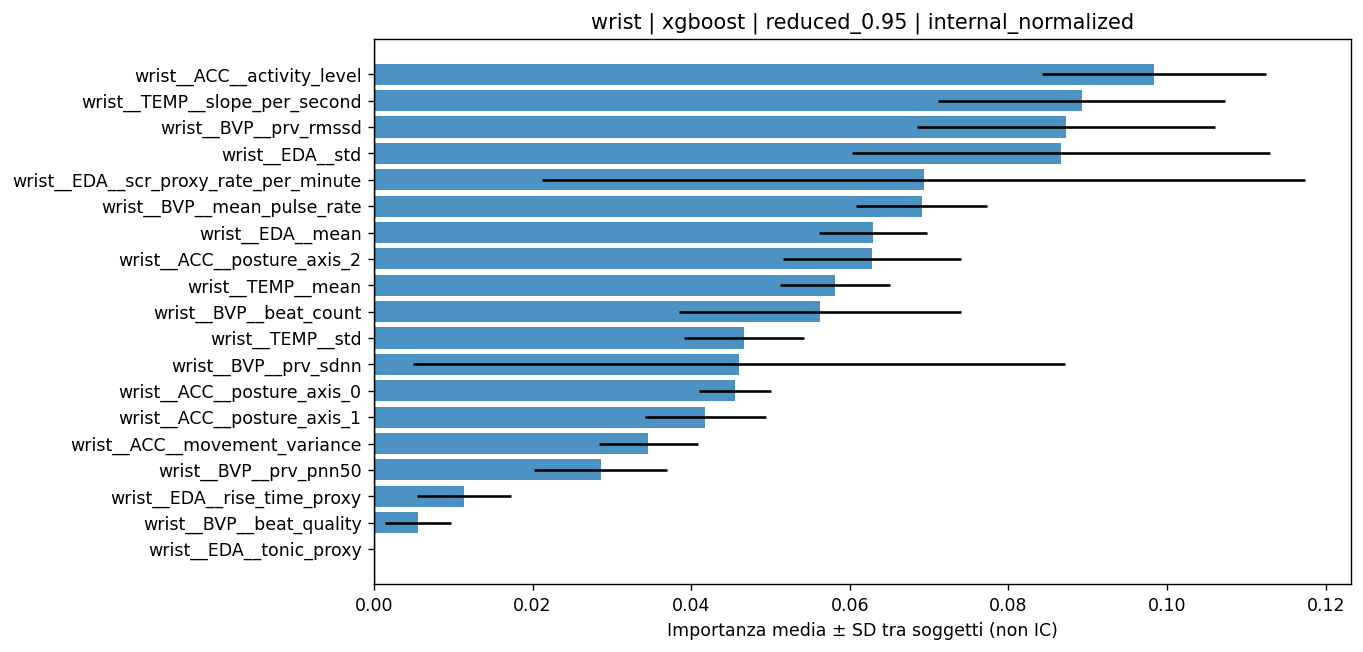

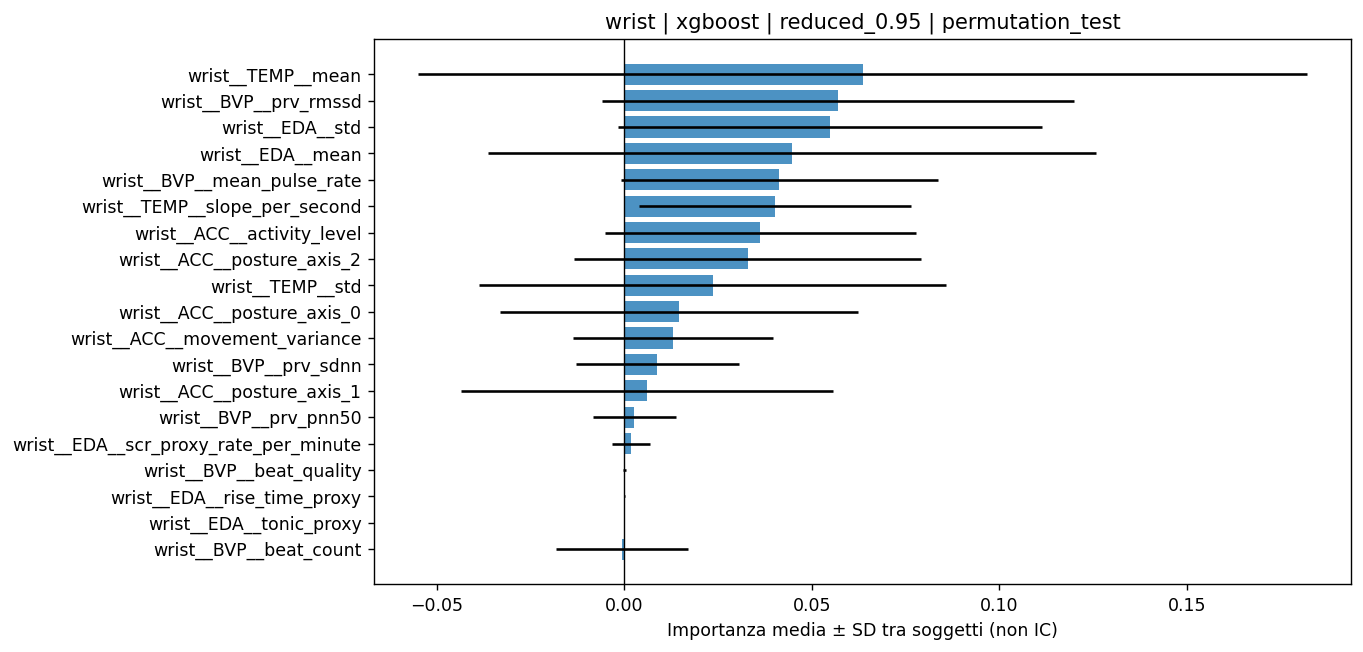

,feature,mean,std,selection_frequency,site,model,variant,kind
1758,wrist__TEMP__mean,0.224143,0.016558,1.0,wrist,lightgbm,reduced_0.80,internal_normalized
1720,wrist__TEMP__mean,0.202574,0.014057,1.0,wrist,lightgbm,full,internal_normalized
1834,wrist__TEMP__mean,0.202058,0.013981,1.0,wrist,lightgbm,reduced_0.95,internal_normalized
1796,wrist__TEMP__mean,0.196788,0.011015,1.0,wrist,lightgbm,reduced_0.90,internal_normalized
468,chest__ACC__activity_level,0.190406,0.028114,1.0,chest,xgboost,reduced_0.80,internal_normalized
520,chest__ACC__activity_level,0.186617,0.026237,1.0,chest,xgboost,reduced_0.90,internal_normalized
2059,wrist__EDA__scr_proxy_rate_per_minute,0.177004,0.048714,1.0,wrist,xgboost,reduced_0.80,internal_normalized
572,chest__ACC__activity_level,0.174697,0.022043,1.0,chest,xgboost,reduced_0.95,internal_normalized
260,chest__ACC__activity_level,0.162550,0.017077,1.0,chest,random_forest,reduced_0.80,internal_normalized
416,chest__ACC__activity_level,0.152112,0.020328,1.0,chest,xgboost,full,internal_normalized


In [5]:
# Read the latest saved tables so an interrupted session cannot leave stale variables.
for variable, filename in [
    ('fold_metrics','fold_metrics.csv'),
    ('selection','feature_selection.csv'),
    ('importances','feature_importances.csv'),
]:
    file=OUT/filename
    if file.is_file() and file.stat().st_size > 2:
        try:
            globals()[variable]=pd.read_csv(file)
        except pd.errors.EmptyDataError:
            pass

if 'importances' not in globals():
    raise RuntimeError('Run the training cell first: no importance table is available.')
if importances.empty:
    completed_models=(sorted(fold_metrics.model.unique())
                      if 'fold_metrics' in globals() and not fold_metrics.empty else [])
    raise RuntimeError(
        f'No tree importances collected. Completed models: {completed_models}. '
        'If only logistic_regression is present, complete the random_forest folds. '
        'If random_forest is present, rerun the corrected training cell; '
        'importance values cannot be reconstructed from metrics alone.'
    )
expected_subjects={site:frames[site].subject_id.nunique() for site in SITES}
display(fold_metrics.groupby(['site','model','variant']).subject_id.nunique().rename('completed_subjects'))
for (site,model,variant),g in fold_metrics.groupby(['site','model','variant']):
    if g.subject_id.nunique()!=expected_subjects[site]:
        warnings.warn(f'Incomplete LOSO: {site}, {model}, {variant}. Plots are preliminary.')
tree_runs=fold_metrics[fold_metrics.model.isin(['random_forest','xgboost','lightgbm'])]
for row in tree_runs[['site','model','variant','subject_id']].drop_duplicates().itertuples(index=False):
    match=importances[(importances.site==row.site)&(importances.model==row.model)&
        (importances.variant==row.variant)&(importances.subject_id==row.subject_id)]
    if set(match.kind) != {'internal_normalized','permutation_test'}:
        raise RuntimeError(f'Incomplete tree importances for {tuple(row)}. Rerun the training cell.')
selection['selected']=selection.selected.astype(str).str.lower().eq('true')
if not importances.empty:
    completed=[]
    for (site,model,variant),group in fold_metrics.groupby(['site','model','variant']):
        part=importances[(importances.site==site)&(importances.model==model)&(importances.variant==variant)]
        if part.empty:continue
        universe=selection[(selection.site==site)&(selection.model==model)&(selection.variant==variant)]
        for kind in part.kind.unique():
            joined=universe.merge(part[part.kind.eq(kind)][['subject_id','feature','importance']],
                on=['subject_id','feature'],how='left',validate='one_to_one')
            # Missing internal entries correspond to features absent after preprocessing.
            if kind=='internal_normalized':joined['importance']=joined.importance.fillna(0.)
            if joined.importance.isna().any():raise ValueError('Importanze di test mancanti.')
            summary=joined.groupby('feature').agg(mean=('importance','mean'),
                std=('importance','std'),selection_frequency=('selected','mean')).reset_index()
            summary['site']=site;summary['model']=model;summary['variant']=variant;summary['kind']=kind
            completed.append(summary)
            top=summary.nlargest(TOP_N,'mean').sort_values('mean')
            fig,ax=plt.subplots(figsize=(11,max(5,len(top)*.28)))
            ax.barh(top.feature,top['mean'],xerr=top['std'].fillna(0),alpha=.8)
            ax.axvline(0,color='black',linewidth=.8)
            ax.set(title=f'{site} | {model} | {variant} | {kind}',
                xlabel='Importanza media ± SD tra soggetti (non IC)')
            fig.tight_layout();show(fig,f'importance_{site}_{model}_{variant}_{kind}.png')
    importance_summary=pd.concat(completed,ignore_index=True)
    importance_summary.to_csv(OUT/'importance_subject_summary.csv',index=False)
    display(importance_summary.sort_values('mean',ascending=False).head(40))


## Come commentare

- Prestazioni simili con meno feature: evidenza esplorativa di ridondanza eliminabile, non prova di equivalenza.
- Prestazioni inferiori dopo la riduzione: la correlazione marginale non identifica automaticamente feature dispensabili; l'ordine di selezione può scartare un predittore utile.
- Coefficienti/importanze instabili non invalidano automaticamente la previsione, ma limitano l'interpretazione delle singole feature.
- Importanza interna elevata con permutation importance bassa può riflettere ridondanza o bias dell'importanza interna; non consente da sola una spiegazione univoca.
- Le finestre condividono dipendenza temporale e i fold condividono training subjects. Nessuna importanza è prova causale o test fisiologico validato.
- L'analisi non cerca la correlazione delle feature con i self-report: quella domanda è trattata nel notebook 08.

Per verificare se una modalità nel complesso è utile, i confronti fra modalità e gli esperimenti di masking sono più appropriati della somma delle singole importanze marginali.

In [6]:
manifest={'analysis_role':'exploratory','thresholds':CORRELATION_THRESHOLDS,
    'correlation_method':CORRELATION_METHOD,'selection_rule':'alphabetical greedy; training only',
    'sites':SITES,'models':MODELS,'nested_subject_tuning':True,
    'permutation_repeats':N_PERMUTATION_REPEATS,'seed':SEED,
    'config_sha256':fingerprint(c),'importance_use':'descriptive only; no test-driven selection'}
(OUT/'manifest.json').write_text(json.dumps(manifest,indent=2),encoding='utf-8')
print('Results saved successfully.')


Results saved successfully.


## Interpretation of the feature-redundancy sensitivity analysis

### Scope and evaluation

This notebook evaluates whether the primary three-class classification
results depend on highly correlated input features.

The analysis includes:

- **15 participants**.
- **Three sensor configurations:** chest, wrist, and early fusion.
- **Five algorithms:** logistic regression, random forest, XGBoost,
  LightGBM, and MLP.
- **Four variants:** complete features and correlation thresholds
  of 0.95, 0.90, and 0.80.

This produces **60 configurations and 900 outer-fold evaluations**.

All configurations use the common valid windows for the
baseline/stress/amusement task. The correlation filter is fitted inside
each training partition, including the inner hyperparameter-validation
folds, and applied unchanged to validation and test data.

The complete and reduced pipelines are saved together with training
participant identifiers, feature names, class order, and OOF predictions
for subsequent interpretation.

### This is a post-hoc sensitivity analysis

The filter examines absolute Spearman correlations between predictors.
It does not remove features because they correlate with the target.

A deterministic alphabetical rule retains a representative feature and
removes subsequent highly correlated features. Constant or entirely
missing training features are also removed in the reduced variants.

The procedure does not guarantee the most informative representative
within a correlated group. A reduced model can therefore improve, remain
similar, or deteriorate.

All thresholds are reported. The best observed threshold is not used
retrospectively to redefine the original primary model.

### Balanced accuracy across all thresholds

Values below are equal-participant mean balanced accuracies.

#### Chest

| Algorithm | Complete | Filter 0.95 | Filter 0.90 | Filter 0.80 |
|---|---:|---:|---:|---:|
| Logistic regression | 65.66% | 66.69% | 66.11% | 66.19% |
| Random forest | 63.05% | 64.32% | 63.98% | 65.75% |
| XGBoost | 67.78% | 67.99% | 66.38% | 67.47% |
| LightGBM | 69.70% | 64.92% | 66.83% | 68.02% |
| MLP | 59.09% | 53.95% | 57.21% | 60.39% |

The chest results do not show a uniform benefit from removing correlated
features. Logistic regression changes relatively little, while LightGBM
performs better with the complete feature set than with any filtered
variant.

#### Early fusion

| Algorithm | Complete | Filter 0.95 | Filter 0.90 | Filter 0.80 |
|---|---:|---:|---:|---:|
| Logistic regression | 68.21% | 69.04% | 66.28% | 66.17% |
| Random forest | 67.44% | 70.26% | **72.36%** | 69.95% |
| XGBoost | 68.46% | 67.62% | 67.29% | 65.37% |
| LightGBM | 67.94% | 66.44% | 68.44% | 68.82% |
| MLP | 60.05% | 62.98% | 62.64% | 65.69% |

Early-fusion random forest benefits most clearly from the 0.90 filter.
However, the pattern is algorithm-dependent: more aggressive filtering
does not consistently improve performance.

#### Wrist

| Algorithm | Complete | Filter 0.95 | Filter 0.90 | Filter 0.80 |
|---|---:|---:|---:|---:|
| Logistic regression | 66.11% | 65.89% | 66.56% | 64.89% |
| Random forest | 68.29% | 68.79% | 68.32% | 65.88% |
| XGBoost | 68.88% | **70.71%** | 67.78% | 66.44% |
| LightGBM | 66.06% | 66.30% | 65.64% | 62.20% |
| MLP | 66.75% | 69.01% | 65.82% | 65.69% |

The 0.95 threshold produces promising observed results for wrist XGBoost
and MLP. Stronger filtering frequently reduces performance.

These comparisons do not support treating all correlated features as
dispensable.

### Feature-count reduction

The mean retained feature counts are:

| Configuration | Complete | Filter 0.95 | Filter 0.90 | Filter 0.80 |
|---|---:|---:|---:|---:|
| Chest | 26.00 | 20.93 | 19.00 | 18.13 |
| Wrist | 19.00 | 17.93 | 16.07 | 14.00 |
| Early fusion | 45.00 | 38.87 | 35.07 | 32.13 |

Fractional counts arise because the selected feature set can differ
between outer training folds.

A smaller feature set is more parsimonious, but this does not by itself
establish greater physiological validity, better generalization, or
reduced sensor requirements.

### Early-fusion random forest: the strongest observed sensitivity result

The complete early-fusion random forest obtains:

- Balanced accuracy: **67.44%**.
- Macro F1: **0.642**.
- Input features: **45**.

With the 0.90 filter, it obtains:

- Balanced accuracy: **72.36%**.
- Macro F1: **0.704**.
- Mean retained features: approximately **35.07**.

The paired balanced-accuracy differences relative to the complete model are:

| Filter | Mean difference | Conditional bootstrap 95% CI |
|---|---:|---|
| 0.95 | +2.82 percentage points | [+0.04, +5.50] |
| 0.90 | **+4.92 percentage points** | **[+2.63, +7.24]** |
| 0.80 | +2.51 percentage points | [−0.49, +5.62] |

The 0.90 result favors the reduced configuration under this exploratory
paired bootstrap.

However, these intervals are conditional on fitted predictions and are
not adjusted for the many algorithms, modalities, and thresholds examined.
They do not establish an independently validated optimal threshold or
a definitive overall winner.

The interval for 0.95 is particularly close to zero and should not be
overinterpreted.

### Class-specific performance remains uneven

For early-fusion random forest with the 0.90 filter, mean participant-level
recalls are approximately:

| Class | Mean recall |
|---|---:|
| Baseline | 88.0% |
| Stress | 85.1% |
| Amusement | **44.0%** |

Amusement recall improves from approximately **34.0%** in the complete
early-fusion random forest, but remains substantially lower than the
other two classes.

The improved overall balanced accuracy therefore does not eliminate
class-specific weaknesses.

### Feature-selection stability

Selection frequency reports how often each feature survives the filter
across outer training folds.

A feature retained in every fold is stable under this particular
correlation rule. This does not prove that it is predictively important
or physiologically necessary.

Likewise, a feature consistently removed may be represented by a
correlated variable. Its removal does not demonstrate that the underlying
physiological process is irrelevant.

Because the representative is chosen alphabetically rather than by
predictive performance, selection frequency must be interpreted as
stability of the filtering procedure.

### Tree-model importance

The notebook reports two different importance measures:

- **Internal normalized importance:** derived from the fitted tree model.
- **Test permutation importance:** the change in held-out balanced accuracy
  after perturbing one input feature.

These measures have different units and should not be ranked together.

Internal importance can distribute credit among correlated predictors.
Permutation importance can underestimate a feature when correlated
alternatives preserve similar information.

The observed prominence of variables such as movement, temperature,
electrodermal activity, and beat-related features identifies areas for
further inspection. It does not establish that they cause stress or
represent stress-specific mechanisms.

In particular, movement-related importance may reflect experimental-task
characteristics. Raw-signal and condition-level inspection is needed
before assigning a physiological interpretation.

Between-participant standard deviations describe variability across
held-out subjects. They are not confidence intervals.

### Overall conclusion

Feature redundancy has a configuration-dependent effect. Removing highly
correlated inputs sometimes improves performance, but can also remove
useful information and reduce discrimination.

Early-fusion random forest with the 0.90 filter is the strongest observed
configuration within this sensitivity analysis, combining higher mean
balanced accuracy and macro F1 with fewer retained features.

This remains a post-hoc exploratory finding. The original primary analysis
is preserved, all thresholds are reported, and independent confirmation
is needed before declaring a preferred model or filtering threshold.
